In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

In [2]:
%pip install langchain langchain-core langchain-openai langchain-anthropic -q
import os
if os.path.exists("requirements.txt"):
    %pip install -r requirements.txt -q
else:
    print("requirements.txt not found -- skipping")



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


"??  requirements.txt not found - skipping"


'test' is not recognized as an internal or external command,
operable program or batch file.


In [3]:
%pip install langchain-ollama -q


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [ ]:
import os, sys, json, time, csv
from datetime import datetime, timedelta

# ================================================================
# 📁 SESSION LOGGER v2 — structured output, summary_table, 10-day
# ================================================================
LOG_FILE   = "trading_log_ARAMCO.json"
CSV_FILE   = "trading_log_ARAMCO.csv"  # ✅ NEW: same data, mirrored as CSV
MAX_DAYS   = 10
COMPANY    = "2222.SR"
TRADE_DATE = datetime.now().strftime("%Y-%m-%d")

def _load_sessions() -> list:
    if not os.path.exists(LOG_FILE):
        return []
    try:
        with open(LOG_FILE, "r", encoding="utf-8") as f:
            data = json.load(f)
        if isinstance(data, dict):
            return [data]
        return data if isinstance(data, list) else []
    except (json.JSONDecodeError, IOError):
        return []

def _prune(sessions: list) -> list:
    cutoff = datetime.now() - timedelta(days=MAX_DAYS)
    kept = []
    for s in sessions:
        try:
            if datetime.strptime(s["session_start"], "%Y-%m-%d %H:%M:%S") >= cutoff:
                kept.append(s)
        except (KeyError, ValueError):
            kept.append(s)
    return kept

# ✅ NEW: CSV mirror — same session data as the JSON log, flattened into
# one row per session. Nested parts (all step outputs, full summary_table)
# are kept intact as JSON strings in their own columns, so nothing that's
# in trading_log_ARAMCO.json is missing from trading_log_ARAMCO.csv.
STEP_NAME_TO_KEY = {
    "Fundamentals Analyst":              "fundamentals",
    "Market Analyst":                    "market",
    "Macro Regime Analyst":              "macro_regime",
    "News Analyst":                      "news",
    "Sentiment Analyst":                 "sentiment",
    "Investment Debate (Bull vs Bear)":  "debate_bull_bear",
    "Investment Debate Facilitator":     "debate_facilitator",
    "Post-Mortem Self-Critique":         "post_mortem",
    "Trader Decision":                   "trader",
    "Risk Management Debate (3 Rounds)": "risk_debate",
    "Risk Facilitator Decision":         "risk_facilitator",
    "Portfolio Manager Final Decision":  "portfolio_manager",
    "Prediction Engine":                 "prediction_engine",
    "Decision Verifier":                 "decision_verifier",
}

def _stringify_for_csv(value) -> str:
    """dict/list -> compact JSON string; everything else -> str(), newlines
    flattened so one step's answer can't break the CSV into extra rows."""
    if isinstance(value, (dict, list)):
        text = json.dumps(value, ensure_ascii=False)
    else:
        text = "" if value is None else str(value)
    return text.replace(chr(13) + chr(10), " ").replace(chr(10), " ")

def _step_io_by_name(steps: list, step_name: str):
    """Last matching step's (input, output) -- last, in case a step name is
    ever logged more than once in a single session."""
    match = None
    for step in steps:
        if step.get("step") == step_name:
            match = step
    if match is None:
        return "", ""
    return _stringify_for_csv(match.get("input")), _stringify_for_csv(match.get("output"))

# ✅ EXPANDED: every agent's full input AND output now gets its own pair of
# readable CSV columns (<step>_input / <step>_output), instead of being
# reachable only by parsing the steps_json blob. steps_json/summary_table_json
# are kept too, for anything that still wants the raw structure.
CSV_FIELDS = [
    "session_id", "session_start", "session_end", "company", "trade_date",
    "final_signal", "final_decision", "market_latest_close",
    "rsi", "macd", "close_50_sma", "boll_ub", "boll_lb",
    "pe_ratio", "eps_ttm", "market_cap", "net_debt",
    "overall_sentiment", "positive_count", "negative_count", "neutral_count",
    "sentiment_score",
] + [f"{key}_input" for key in STEP_NAME_TO_KEY.values()] \
  + [f"{key}_output" for key in STEP_NAME_TO_KEY.values()] \
  + ["steps_json", "summary_table_json"]

def _flatten_session_for_csv(s: dict) -> dict:
    tbl   = s.get("summary_table", {}) or {}
    inds  = tbl.get("market_indicators", {}) or {}
    fm    = tbl.get("fundamentals_analyst", {}) or {}
    nm    = tbl.get("news_analyst", {}) or {}
    sm    = tbl.get("sentiment_analyst", {}) or {}
    steps = s.get("steps", [])

    row = {
        "session_id":          s.get("session_id", ""),
        "session_start":       s.get("session_start", ""),
        "session_end":         s.get("session_end", ""),
        "company":             s.get("company", ""),
        "trade_date":          s.get("trade_date", ""),
        "final_signal":        tbl.get("final_signal", ""),
        "final_decision":      (s.get("final_decision", "") or "")[:500].replace(chr(10), " "),
        "market_latest_close": tbl.get("market_latest_close", ""),
        "rsi":                 inds.get("rsi", ""),
        "macd":                inds.get("macd", ""),
        "close_50_sma":        inds.get("close_50_sma", ""),
        "boll_ub":             inds.get("boll_ub", ""),
        "boll_lb":             inds.get("boll_lb", ""),
        "pe_ratio":            fm.get("pe_ratio", ""),
        "eps_ttm":             fm.get("eps_ttm", ""),
        "market_cap":          fm.get("market_cap", ""),
        "net_debt":            fm.get("net_debt", ""),
        "overall_sentiment":   nm.get("overall_sentiment", ""),
        "positive_count":      nm.get("positive_count", ""),
        "negative_count":      nm.get("negative_count", ""),
        "neutral_count":       nm.get("neutral_count", ""),
        "sentiment_score":     sm.get("score", ""),
        "steps_json":          json.dumps(steps, ensure_ascii=False),
        "summary_table_json":  json.dumps(tbl, ensure_ascii=False),
    }
    for step_name, key in STEP_NAME_TO_KEY.items():
        row[f"{key}_input"], row[f"{key}_output"] = _step_io_by_name(steps, step_name)
    return row

def _save_sessions_csv(sessions: list) -> None:
    """JSON-এ যা যা session store হচ্ছে, ঠিক সেই same sessions গুলো
    CSV_FILE-এও mirror করে রাখে (Excel/Sheets-এ সরাসরি খোলা যায়)।"""
    with open(CSV_FILE, "w", newline="", encoding="utf-8") as f:
        writer = csv.DictWriter(f, fieldnames=CSV_FIELDS)
        writer.writeheader()
        for s in sessions:
            writer.writerow(_flatten_session_for_csv(s))


def _save_sessions(sessions: list) -> None:
    with open(LOG_FILE, "w", encoding="utf-8") as f:
        json.dump(sessions, f, indent=2, ensure_ascii=False)
    # ✅ NEW: every time the JSON log is (re)written, mirror the same
    # sessions into the CSV file too — single source of truth, so the
    # two files can never drift out of sync.
    _save_sessions_csv(sessions)

def _pretty(data) -> str:
    """Human-readable string for terminal display only."""
    if isinstance(data, dict):
        return "\n".join(f"  [{k.upper()}]: {str(v)[:300]}" for k, v in data.items())
    return str(data)[:800]

SESSION_ID = datetime.now().strftime("%Y-%m-%d_%H-%M-%S")

session_log = {
    "session_id":    SESSION_ID,
    "session_start": datetime.now().strftime("%Y-%m-%d %H:%M:%S"),
    "company":       COMPANY,
    "trade_date":    TRADE_DATE,
    "steps":         [],
    "summary_table": {},  # ← top-level structured summary
}

def log_step(step_name: str, input_data, output_data) -> None:
    """
    FIXED: output_data dict এখন JSON-এ raw dict হিসেবে save হয়।
    summary_table-এ metrics থাকলে top-level-এও extract হয়।
    """
    entry = {
        "step":      step_name,
        "timestamp": datetime.now().strftime("%H:%M:%S"),
        "input":     _pretty(input_data),
        # ✅ KEY FIX: dict হলে dict-ই রাখো, string-এ convert করো না
        "output":    output_data,
    }
    session_log["steps"].append(entry)

    # ── summary_table update ─────────────────────────────────────
    if isinstance(output_data, dict):
        # "metrics" key থাকলে step নামে store করো
        if "metrics" in output_data and output_data["metrics"]:
            skey = step_name.lower().replace(" ", "_")
            session_log["summary_table"][skey] = output_data["metrics"]

        # News analyst structured metrics
        if "news_metrics" in output_data:
            session_log["summary_table"]["news_analyst"] = output_data["news_metrics"]

        # Sentiment structured metrics
        if "sentiment_metrics" in output_data:
            session_log["summary_table"]["sentiment_analyst"] = output_data["sentiment_metrics"]

        # Market indicators
        if "indicators" in output_data:
            session_log["summary_table"]["market_indicators"] = output_data["indicators"]

        # Market stock_data — latest Close price extract করে রাখো (raw CSV নয়)
        if "stock_data" in output_data:
            import re as _re2
            raw_csv = str(output_data["stock_data"])
            latest_close = None
            csv_lines = [l for l in raw_csv.split("\n") if l.strip() and not l.startswith("#")]
            if len(csv_lines) > 1:
                for row in reversed(csv_lines[1:]):
                    parts = row.split(",")
                    if len(parts) >= 5 and parts[4].strip() and parts[4].strip() not in ("", "Close"):
                        try:
                            latest_close = float(parts[4].strip())
                            break
                        except ValueError:
                            pass
            if latest_close is not None:
                session_log["summary_table"]["market_latest_close"] = latest_close
            # raw CSV রাখো backtest-এর জন্য (আলাদা key)
            session_log["summary_table"]["market_stock_data"] = raw_csv

    # ── persist ──────────────────────────────────────────────────
    # ✅ CHANGED: dedup by session_id (this exact run), not by (company, trade_date).
    # Old code wiped out ANY earlier session from the same calendar date before
    # appending — so running the pipeline every 2 hours meant only the last run
    # of the day ever survived on disk. Now every run keeps its own entry; we
    # only replace a session if it's literally the SAME run being re-saved
    # (this function is called multiple times per run as steps complete).
    sessions = _prune(_load_sessions())
    sessions = [s for s in sessions if s.get("session_id") != SESSION_ID]
    sessions.append(session_log)
    _save_sessions(sessions)
    print(f"📝 Logged: {step_name}  (sessions stored: {len(sessions)})")

def finalize_session(final_decision: str) -> None:
    """Session শেষে একবার call করো।"""
    import re
    session_log["session_end"]    = datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    session_log["final_decision"] = final_decision

    # BUY/HOLD/SELL parse করে summary_table-এ রাখো
    match = re.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", final_decision, re.IGNORECASE)
    session_log["summary_table"]["final_signal"]   = match.group(1).upper() if match else "N/A"
    session_log["summary_table"]["final_decision"] = final_decision[:600]

    # News markdown table capture (if present in final decision)
    tbl = re.search(
        r"(\|.*?Category.*?\|.*?(?:\n\|[-| ]+\|)(?:\n\|.*?\|)+)",
        final_decision, re.IGNORECASE | re.DOTALL
    )
    if tbl:
        session_log["summary_table"]["news_summary_markdown"] = tbl.group(1)

    # ✅ CHANGED: same session_id-based dedup as log_step (see comment there).
    sessions = _prune(_load_sessions())
    sessions = [s for s in sessions if s.get("session_id") != SESSION_ID]
    sessions.append(session_log)
    _save_sessions(sessions)
    print(f"\n✅ Session finalised → {LOG_FILE}  ({len(sessions)} sessions stored)")

def get_session(company: str, trade_date: str) -> dict | None:
    matches = [s for s in _load_sessions()
               if s.get("company") == company and s.get("trade_date") == trade_date]
    return matches[-1] if matches else None

def get_all_sessions(company: str, trade_date: str) -> list:
    return [s for s in _load_sessions()
            if s.get("company") == company and s.get("trade_date") == trade_date]

def get_step_output(session: dict, step_name: str):
    """Step output সরাসরি dict হিসেবে return করে।"""
    for step in session.get("steps", []):
        if step_name.lower() in step["step"].lower():
            return step.get("output")
    return None

def print_log_summary() -> None:
    sessions = _prune(_load_sessions())
    print(f"\n{'─'*60}")
    print(f"  SESSION LOG SUMMARY  ({len(sessions)} sessions, last {MAX_DAYS} days)")
    print(f"{'─'*60}")
    for s in sessions:
        signal = s.get("summary_table", {}).get("final_signal", "?")
        d = s.get("final_decision", "")[:50].replace("\n", " ")
        print(f"  {s.get('trade_date')}  {s.get('company','?'):6s}  [{signal:4s}]  →  {d}...")
    print(f"{'─'*60}\n")

def print_summary_table(session: dict | None = None) -> None:
    """Current session বা দেওয়া session-এর summary_table সুন্দরভাবে print করে।"""
    s   = session or session_log
    tbl = s.get("summary_table", {})
    if not tbl:
        print("  (summary_table empty — run analysts first)")
        return

    print(f"\n{'═'*65}")
    print(f"  📊 SESSION SUMMARY TABLE — {s.get('company','?')} | {s.get('trade_date','?')}")
    print(f"{'═'*65}")

    sig = tbl.get("final_signal", "—")
    print(f"  🏁 Final Signal : {sig}")

    # Fundamentals
    fm = tbl.get("fundamentals_analyst", {})
    if fm:
        print(f"\n  📈 FUNDAMENTALS")
        for k, label in [
            ("market_cap","Market Cap"), ("pe_ratio","P/E Ratio"),
            ("eps_ttm","EPS (latest period)"), ("revenue_ttm","Revenue TTM"),
            ("free_cash_flow_q","Free Cash Flow (Q)"), ("net_debt","Net Debt"),
            ("52w_high","52W High"), ("52w_low","52W Low"),
        ]:
            print(f"     {label:20s}: {fm.get(k,'N/A')}")

    # Market / Technical
    inds = tbl.get("market_indicators", {})
    if inds:
        import re
        print(f"\n  📉 TECHNICAL INDICATORS")
        for k in ["rsi", "macd", "close_50_sma", "boll_ub", "boll_lb"]:
            v = inds.get(k, "N/A")
            nums = re.findall(r"-?\d+\.?\d*", str(v))
            print(f"     {k:16s}: {nums[0] if nums else v}")

    # News
    nm = tbl.get("news_analyst", {})
    if nm:
        print(f"\n  📰 NEWS SENTIMENT")
        print(f"     Overall    : {nm.get('overall_sentiment','N/A')}")
        print(f"     Positive   : {nm.get('positive_count','N/A')}")
        print(f"     Negative   : {nm.get('negative_count','N/A')}")
        print(f"     Neutral    : {nm.get('neutral_count','N/A')}")

    # Sentiment
    sm = tbl.get("sentiment_analyst", {})
    if sm:
        print(f"\n  💬 SENTIMENT SCORE")
        print(f"     Score (1-10): {sm.get('score','N/A')}")
        print(f"     Confidence  : {sm.get('confidence','N/A')}")
        print(f"     Overall     : {sm.get('overall','N/A')}")

    # Prediction Engine (quantitative forecast)
    pe = tbl.get("prediction_engine", {})
    if pe:
        print("\n  QUANTITATIVE PREDICTION")
        model_forecasts = pe.get("model_forecasts") or {}
        ccy0 = pe.get("currency", "")
        for mname, mf in model_forecasts.items():
            mark = "  <<<" if mf.get("is_winner") else ""
            print(f"     {mname:15s}: {mf.get('predicted_price','N/A')} {ccy0} "
                  f"({mf.get('predicted_return_pct','N/A')}%)  "
                  f"acc={mf.get('holdout_direction_accuracy','N/A')}{mark}")
        model = pe.get("winner_model", "N/A")
        print(f"     Winner model : {model}")
        hz = pe.get("horizon_days", "?")
        pp = pe.get("predicted_price", "N/A")
        ccy = pe.get("currency", "")
        pr = pe.get("predicted_return_pct", "N/A")
        print(f"     FINAL {hz}-day forecast: {pp} {ccy} ({pr}%)")
        acc = pe.get("holdout_direction_accuracy", "N/A")
        print(f"     Confidence   : {acc}")
        if pe.get("memory_correction_applied"):
            mcp = pe.get("memory_correction_pct", "N/A")
            n_sim = pe.get("memory_n_similar_episodes", "?")
            print(f"     Memory adj.  : {mcp}% (from {n_sim} similar past episodes)")

    # News markdown table
    md = tbl.get("news_summary_markdown", "")
    if md:
        print(f"\n  📋 NEWS HEADLINES TABLE:")
        print(md[:900])

    print(f"{'═'*65}\n")

# ================================================================
# 🤖 LLM Setup — Ollama (Qwen2.5 7B)
# ================================================================
from langchain_ollama import ChatOllama

llm = ChatOllama(
    model="qwen2.5:7b",
    base_url="http://localhost:11434",
    temperature=0,
    num_ctx=8192,
    repeat_penalty=1.15,
    num_predict=2048,
)

log_step("LLM Setup", "Ollama Qwen2.5 7B", "LLM initialized")
print(f"✅ Logger + LLM ready!  trade_date = {TRADE_DATE}")


# ================================================================
# 🔁 SHARED LLM RETRY HELPER
# ================================================================
# ✅ FIXED: previously each agent cell (Trader, Aggressive/Conservative/
# Neutral Risk debators, Portfolio Manager) had its own copy-pasted
# "for attempt in range(3): ... except: sleep" retry loop. If every
# attempt hit a rate limit, the loop finished WITHOUT ever assigning
# `response`, causing a NameError on the next line. This single helper
# is used everywhere instead and raises a clear error if all retries
# are exhausted.
def invoke_llm_with_retry(llm, prompt_or_messages, max_attempts: int = 4):
    """llm.invoke() with backoff for two known transient Ollama failures:
    rate limiting (429), and the local model getting stuck in a degenerate
    repetition loop that Ollama aborts mid-generation
    (ResponseError: "prediction aborted, token repeat limit reached").

    The repeat-limit abort is retried with the model's temperature nudged
    upward each attempt (greedy temperature=0 decoding tends to repeat the
    same loop if retried unchanged; a small temperature bump changes the
    sampling path enough to usually break it). Temperature is restored
    after the call whether it succeeds or fails, so it never leaks into
    later unrelated calls on the same llm object.

    Raises RuntimeError only if every attempt fails, instead of silently
    leaving a variable undefined."""
    last_err = None
    original_temperature = getattr(llm, "temperature", None)
    try:
        for attempt in range(max_attempts):
            try:
                return llm.invoke(prompt_or_messages)
            except Exception as e:
                last_err = e
                msg = str(e).lower()
                if "429" in msg or "rate_limit" in msg:
                    wait_time = 60 * (attempt + 1)
                    print(f"\u23f3 Rate limit! {wait_time} \u09b8\u09c7\u0995\u09c7\u09a8\u09cd\u09a1 \u0985\u09aa\u09c7\u0995\u09cd\u09b7\u09be...")
                    time.sleep(wait_time)
                elif "repeat limit" in msg or "aborted" in msg:
                    if original_temperature is not None and attempt < max_attempts - 1:
                        llm.temperature = min(1.0, original_temperature + 0.2 * (attempt + 1))
                    new_temp = getattr(llm, 'temperature', '?')
                    print(f"\U0001f501 Repeat-limit abort (attempt {attempt + 1}/{max_attempts}); "
                          f"retrying with temperature={new_temp}...")
                else:
                    raise
    finally:
        if original_temperature is not None:
            llm.temperature = original_temperature
    raise RuntimeError(
        f"invoke_llm_with_retry: {max_attempts} attempts exhausted, last error: {last_err}"
    )


# ================================================================
# ✅ STOPGAP FIX: build_instrument_context() (from the tradingagents
# package, not editable here) appears to always return
# "Consumer Electronics | NASDAQ" regardless of the actual company —
# that's a bug inside that external package, not in this notebook.
# This override table corrects it for tickers we've verified; any other
# ticker not listed here still falls back to the (possibly wrong)
# package output — extend this dict if you add a new ticker.
# ================================================================
KNOWN_INSTRUMENT_OVERRIDES = {
    "2323.TW": "Sector: Technology (Electronic Equipment & Parts) | Exchange: Taiwan Stock Exchange (TWSE)",
    "TTD": "Sector: Communication Services (Advertising Agencies) | Exchange: NASDAQ",
    "2222.SR": "Sector: Energy (Oil & Gas Integrated) | Exchange: Tadawul (Saudi Exchange)",
"0300.HK": "Sector: Consumer Discretionary (Household Appliances) | Exchange: Hong Kong Stock Exchange (HKEX)",
    "AAPL": "Sector: Technology (Consumer Electronics) | Exchange: NASDAQ",
    "IBM":  "Sector: Information Technology (IT Services) | Exchange: NYSE",
    "INTU": "Sector: Technology (Software - Application) | Exchange: NASDAQ",
    "NOK":  "Sector: Technology (Communication Equipment) | Exchange: NYSE",
    "BHC":  "Sector: Healthcare (Specialty Pharmaceuticals) | Exchange: NYSE",
    "CZR":  "Sector: Consumer Cyclical (Resorts & Casinos) | Exchange: NASDAQ",
    "PNR":  "Sector: Industrials (Water Treatment & Pool Equipment) | Exchange: NYSE",
    "AA":   "Sector: Basic Materials (Aluminum) | Exchange: NYSE",
}

def resolve_instrument_context(ticker, raw_context):
    """Overrides build_instrument_context()'s output for known tickers."""
    if ticker in KNOWN_INSTRUMENT_OVERRIDES:
        return KNOWN_INSTRUMENT_OVERRIDES[ticker]
    print(f"[!]  No verified sector/exchange override for {ticker}  -  "
          f"using build_instrument_context() output, which may be wrong. "
          f"Add {ticker} to KNOWN_INSTRUMENT_OVERRIDES if incorrect.")
    return raw_context


# ================================================================
# ✅ FIXED: the Fundamentals Analyst's own report ends with an explicit
# "FINAL TRANSACTION PROPOSAL: BUY/SELL/HOLD" verdict  -  but Bull/Bear
# analysts only ever saw fundamentals_report[:500], which routinely cut
# that verdict off before it arrived (it sits near the end of the report).
# This meant the Fundamentals Analyst could explicitly say SELL (backed by
# real numbers: net loss, negative FCF, high debt) and the Bull Analyst
# would never even see it. This helper preserves that verdict regardless
# of truncation.
# ================================================================
import re as _re_helper

def extract_final_proposal(report_text: str) -> str:
    """Pulls out the FINAL TRANSACTION PROPOSAL verdict so it survives truncation.
    [FIXED]: the old version used r"FINAL TRANSACTION PROPOSAL:.*" which only
    matches same-line text. The LLM sometimes formats this as
    "FINAL TRANSACTION PROPOSAL:**\n**SELL** - ..." with the verdict on the
    NEXT line (markdown bold + line break) -- the old regex silently matched
    nothing but empty markdown stars and never found SELL/BUY/HOLD at all.
    This version searches a window of text after the anchor phrase instead
    of relying on same-line matching, so it survives markdown/newline
    formatting variance.
    """
    report_text = str(report_text)
    idx = report_text.upper().find("FINAL TRANSACTION PROPOSAL")
    if idx == -1:
        return ""
    window = report_text[idx: idx + 150]
    m = _re_helper.search(r"\b(BUY|SELL|HOLD)\b", window, _re_helper.IGNORECASE)
    if not m:
        return ""
    return f"FINAL TRANSACTION PROPOSAL: {m.group(1).upper()}"

# ═══════════════ v10: TOKEN SAVERS (every one has an on/off switch) ═══════════════
import hashlib as _hl, json as _json, os as _os, time as _time
from collections import Counter as _Counter
from types import SimpleNamespace as _NS

# (1) ANALYST REPORT LENGTH -- the debaters read only the first 500 characters of the Market / News / Sentiment reports, and
#     since v8 nothing downstream reads the Fundamentals narrative at all, so long analyst reports were mostly wasted output tokens.
#     A prompt rule asks for a short report; `num_predict` is a GENEROUS runaway guard only (the reports end with a table that code
#     parses, so the cap must not bite in normal use).
USE_ANALYST_LENGTH_CAP = True
ANALYST_MAX_TOKENS = {"market": 900, "news": 900, "sentiment": 700, "macro": 350, "fundamentals": 800}
ANALYST_LEN_RULES = {
    "market": ("LENGTH: start with one line 'KEY POINTS:' (at most 350 characters) giving RSI, MACD, the price vs the 50-day SMA and the "
               "Bollinger position, each with its number. After it write at most 120 words of explanation, then the table. "
               "Later agents read only the first 500 characters of this report."),
    "news": "LENGTH: at most 1-2 sentences per section and about 180 words in total before the table.",
    "sentiment": "LENGTH: about 150 words in total before the table.",
    "fundamentals": "LENGTH: at most about 250 words before the table.",
}


def _cap(name):
    return ANALYST_MAX_TOKENS.get(name) if USE_ANALYST_LENGTH_CAP else None


def _len_rule(name):
    return ("\n" + ANALYST_LEN_RULES[name] + "\n") if (USE_ANALYST_LENGTH_CAP and name in ANALYST_LEN_RULES) else ""


FUND_LLM_REPORT = True        # False = skip the Fundamentals analyst's LLM call entirely (nothing downstream reads its narrative since v8;
                              #         you lose the logged 'analyst's own call' and the written report)

# (2) ANALYST CACHE -- only for temperature-0 analyst calls. The key contains EVERYTHING the output depends on: company, trade date,
#     model, temperature, context size, output cap, and a hash of the full prompt text (which already contains all fetched data:
#     prices, news, fundamentals). Any change -> different key -> the analyst runs fresh. Only the LLM TEXT is cached; numbers, fact
#     sheet, regime and sizing are recomputed in code every run. Turn it OFF for the runs you report in the thesis.
USE_ANALYST_CACHE = True
ANALYST_CACHE_FILE = "analyst_cache.json"
ANALYST_CACHE_VERSION = "v10"
ANALYST_CACHE_MAX_ENTRIES = 200
ANALYST_CACHE_STATS = {"hits": 0, "misses": 0}


def _ac_load():
    try:
        with open(ANALYST_CACHE_FILE, "r", encoding="utf-8") as f:
            d = _json.load(f)
        return d if isinstance(d, dict) and isinstance(d.get("entries"), dict) else {"entries": {}}
    except Exception:
        return {"entries": {}}


def _ac_save(d):
    try:
        ents = d.get("entries", {})
        if len(ents) > ANALYST_CACHE_MAX_ENTRIES:
            keep = sorted(ents.items(), key=lambda kv: kv[1].get("ts", 0), reverse=True)[:ANALYST_CACHE_MAX_ENTRIES]
            d["entries"] = dict(keep)
        with open(ANALYST_CACHE_FILE, "w", encoding="utf-8") as f:
            _json.dump(d, f, ensure_ascii=False)
    except Exception as e:
        print(f"   \u26a0\ufe0f analyst cache not saved: {str(e)[:80]}")


def _ac_key(name, llm, messages):
    texts = "\x1f".join(str(getattr(m, "content", m)) for m in messages)
    parts = [ANALYST_CACHE_VERSION, name, globals().get("COMPANY", ""), globals().get("TRADE_DATE", ""), getattr(llm, "model", ""),
             getattr(llm, "temperature", ""), getattr(llm, "num_ctx", ""), getattr(llm, "num_predict", ""),
             _hl.sha256(texts.encode("utf-8", "ignore")).hexdigest()]
    return _hl.sha256("|".join(map(str, parts)).encode("utf-8")).hexdigest()[:32]


def cached_analyst_invoke(name, llm, messages):
    """Drop-in for `llm.invoke(messages)` in the analyst cells."""
    try:
        deterministic = float(getattr(llm, "temperature", 1)) == 0.0
    except (TypeError, ValueError):
        deterministic = False
    if not (USE_ANALYST_CACHE and deterministic):
        return llm.invoke(messages)
    key = _ac_key(name, llm, messages)
    cache = _ac_load()
    hit = cache["entries"].get(key)
    if hit and str(hit.get("text", "")).strip():
        ANALYST_CACHE_STATS["hits"] += 1
        print(f"   \u267b\ufe0f  cached analyst output: {name} (saved {hit.get('saved_at', '?')}; identical data + prompt + model -> 0 LLM tokens)")
        return _NS(content=hit["text"])
    ANALYST_CACHE_STATS["misses"] += 1
    out = llm.invoke(messages)
    text = str(getattr(out, "content", out))
    if text.strip() and not text.lstrip().startswith(("Error", "(")):
        cache["entries"][key] = {"text": text, "saved_at": _time.strftime("%Y-%m-%d %H:%M:%S"), "ts": _time.time(), "agent": name}
        _ac_save(cache)
    return out


# (3) POST-MORTEM / REFLECTION GATE -- these LLM calls read only the RESOLVED outcomes in memory. HOLD records no P&L (always 0.00%), so
#     with only HOLDs they have nothing to say (and tend to invent "missed profits"). Rules:
#       * same resolved outcomes as the last time  -> reuse the previous text (no LLM call)
#       * no resolved outcome with a non-zero P&L -> no LLM call, a code-built factual line instead
#       * otherwise                                -> call the LLM and remember the answer
USE_OUTCOME_GATE = True
OUTCOME_CACHE_FILE = "outcome_llm_cache.json"
OUTCOME_GATE_VERSION = "v10"


def _oc_pnl(row):
    try:
        return float(row.get("pnl_pct"))
    except (TypeError, ValueError):
        return 0.0


def outcome_is_informative(rows):
    return any(abs(_oc_pnl(r)) >= 0.005 for r in rows)


def outcome_fingerprint(rows, key):
    items = sorted((str(r.get("trade_date", "")), str(r.get("final_signal", "")), str(r.get("regime", "")), str(r.get("pnl_pct", "")),
                    str(r.get("outcome_label", "")), str(r.get("session_id", ""))) for r in rows)
    return _hl.sha256((OUTCOME_GATE_VERSION + "|" + key + "|" + repr(items)).encode("utf-8", "ignore")).hexdigest()[:24]


def gated_outcome_llm(key, rows, run_llm, no_info_text, label):
    if not USE_OUTCOME_GATE:
        return run_llm()
    fp = outcome_fingerprint(rows, key)
    try:
        with open(OUTCOME_CACHE_FILE, "r", encoding="utf-8") as f:
            cache = _json.load(f)
        cache = cache if isinstance(cache, dict) else {}
    except Exception:
        cache = {}
    entry = cache.get(key)
    if entry and entry.get("fp") == fp and str(entry.get("text", "")).strip():
        print(f"   \u267b\ufe0f  {label}: no new resolved outcome since the last run -> reusing the previous text (0 LLM tokens)")
        return entry["text"]
    if not outcome_is_informative(rows):
        print(f"   \u23ed\ufe0f  {label}: {len(rows)} resolved outcome(s), all with 0.00% P&L (HOLD records no P&L) -> LLM call skipped")
        return no_info_text
    text = run_llm()
    if str(text).strip() and not str(text).lstrip().startswith("("):
        cache[key] = {"fp": fp, "text": text, "saved_at": _time.strftime("%Y-%m-%d %H:%M:%S")}
        try:
            with open(OUTCOME_CACHE_FILE, "w", encoding="utf-8") as f:
                _json.dump(cache, f, ensure_ascii=False)
        except Exception as e:
            print(f"   \u26a0\ufe0f outcome cache not saved: {str(e)[:80]}")
    return text


# ── v8: the Fundamentals analyst's BUY/HOLD/SELL call is NOT passed to the other agents ──
# FUND_NUMBERS_ONLY=True  -> every later agent gets only the code-extracted numbers (no LLM narrative, no verdict),
#                            and the "HARD FACT" blocks, the "must out-cite the verdict" rules and the code gate that
#                            downgraded contradicting calls to HOLD all switch themselves off (they need a verdict).
# FUND_NUMBERS_ONLY=False -> v7 behaviour exactly (full LLM report + verdict everywhere).
# FUND_VERDICT_TO_VERIFIER=True -> only the Decision Verifier (after the PM) may still see the verdict as a cross-check.
#                            NOTE: that check can auto-override the final signal to HOLD, so it is OFF by default.
FUND_NUMBERS_ONLY = False   # yfinance notebooks keep the v7 Fundamentals analyst
FUND_VERDICT_TO_VERIFIER = False
FUND_FACTS_MARK = "FUNDAMENTALS - NUMBERS ONLY"


def truncate_preserving_verdict(report_text: str, limit: int = 500) -> str:
    """Truncates a report to `limit` chars but appends the Fundamentals
    Analyst's own FINAL TRANSACTION PROPOSAL verdict if it would otherwise
    be cut off."""
    report_text = str(report_text)
    if report_text.startswith(FUND_FACTS_MARK):          # v8: the numbers-only block is never cut mid-number
        return report_text[:max(limit, 1300)]
    snippet = report_text[:limit]
    verdict = extract_final_proposal(report_text)
    if verdict and verdict not in snippet:
        snippet += f"\n...\n{verdict}"
    return snippet


# ================================================================
# \u2705 NEW: NUMERIC-EVIDENCE VERIFICATION GATE
# ================================================================
# Observed failure mode: even with an explicit rule ("cite >=2 specific
# numbers to override the Fundamentals HARD FACT") and a calibration example,
# the local model sometimes writes "The Bull side cited at least 2 specific
# numbers..." in its own reasoning while citing ZERO actual numbers -- it
# confabulates compliance with the rule instead of following it. Prompting
# alone cannot fix this reliably on a small local model, so this checks the
# claim in code instead of trusting the model's self-report.

def count_numeric_citations(text: str) -> int:
    """Counts distinct 'real' numeric figures in text -- dollar amounts,
    percentages, or multi-digit/decimal numbers. Bare single digits (list
    markers like '1.', '2.') are ignored so they can't inflate the count."""
    text = str(text)
    tokens = _re_helper.findall(r"\$?-?\d[\d,]*\.?\d*%?", text)
    real = set()
    for t in tokens:
        digits_only = _re_helper.sub(r"[^0-9]", "", t)
        if len(digits_only) >= 2 or "%" in t or "$" in t:
            real.add(t)
    return len(real)


def enforce_numeric_evidence_gate(decision_text: str, fund_verdict: str, min_citations: int = 2) -> tuple:
    """If `decision_text`'s own BUY/SELL/HOLD signal contradicts the Fundamentals
    Analyst's hard verdict, verify the decision text actually contains at least
    `min_citations` real numbers before letting the contradiction stand -- do NOT
    trust a sentence in the decision claiming numbers were cited.
    Returns (possibly-corrected text, was_overridden: bool, reason: str).
    """
    decision_text = str(decision_text)
    sig_match = _re_helper.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", decision_text, _re_helper.IGNORECASE)
    signal = sig_match.group(1).upper() if sig_match else "N/A"
    fund_verdict_upper = (fund_verdict or "").upper()

    contradicts = (
        ("SELL" in fund_verdict_upper and signal == "BUY")
        or ("BUY" in fund_verdict_upper and signal == "SELL")
    )
    if not contradicts:
        return decision_text, False, ""

    n_cited = count_numeric_citations(decision_text)
    if n_cited >= min_citations:
        return decision_text, False, f"Contradiction allowed to stand: {n_cited} real numeric citations found."

    corrected = (
        decision_text
        + f"\n\n[AUTO-CORRECTED by code, not LLM] This decision claims to override the "
        f"Fundamentals Analyst's own verdict ({fund_verdict}) but the text contains only "
        f"{n_cited} real numeric citation(s) -- at least {min_citations} required. Vague "
        f"optimism is not evidence. Downgrading to HOLD.\n\nFINAL TRANSACTION PROPOSAL: **HOLD**"
    )
    return corrected, True, f"Overridden: only {n_cited} real numeric citation(s), needed {min_citations}."

In [5]:
import sys, os

# ✅ FIXED: no more hardcoded Windows path (was C:\Users\Nura\...).
# Reads from env var TRADINGAGENTS_PATH if set, else falls back to a
# relative './TradingAgents' folder next to this notebook — works on
# Windows/Linux/Kaggle alike.
TRADING_AGENTS_PATH = os.environ.get(
    "TRADINGAGENTS_PATH",
    os.path.join(os.getcwd(), "TradingAgents"),
)

if TRADING_AGENTS_PATH not in sys.path:
    sys.path.append(TRADING_AGENTS_PATH)

if not os.path.isdir(TRADING_AGENTS_PATH):
    print(f"⚠️  Path does not exist: {TRADING_AGENTS_PATH}")
    print("    Set TRADINGAGENTS_PATH env var to your local TradingAgents checkout.")
else:
    print("✅ Path added:", TRADING_AGENTS_PATH)


⚠️  Path does not exist: c:\Users\Provat\Downloads\predict-final\notebooks\TradingAgents
    Set TRADINGAGENTS_PATH env var to your local TradingAgents checkout.


## 🧠 ChromaDB Memory Setup (RAEM Episodic Memory + News RAG)

In [6]:
# ================================================================
# 🧠 ChromaDB RAG SETUP — Episodic Memory + News Corpus
# ================================================================
# প্রথমবার চালানোর আগে টার্মিনালে: ollama pull nomic-embed-text

import chromadb
from chromadb.utils import embedding_functions
import hashlib

# ── Ollama embedding function (local, CPU-friendly, no API key) ──
ollama_ef = embedding_functions.OllamaEmbeddingFunction(
    url="http://localhost:11434/api/embeddings",
    model_name="nomic-embed-text",
)

# ── Persistent client — disk-এ save হয়, kernel restart-এও থাকে ──
CHROMA_DB_PATH = "./raem_chroma_db"
chroma_client = chromadb.PersistentClient(path=CHROMA_DB_PATH)

# ── Collection 1: Episodic Memory (RAEM core) ──
episodic_memory = chroma_client.get_or_create_collection(
    name="raem_episodic_memory",
    embedding_function=ollama_ef,
    metadata={"description": "Regime-tagged daily trading episodes for RAEM"},
)

# ── Collection 2: News Corpus (RAG retrieval) ──
news_corpus = chroma_client.get_or_create_collection(
    name="raem_news_corpus",
    embedding_function=ollama_ef,
    metadata={"description": "Chunked news articles for semantic retrieval"},
)

print(f"✅ ChromaDB ready at: {CHROMA_DB_PATH}")
print(f"   📦 episodic_memory  : {episodic_memory.count()} episodes stored")
print(f"   📰 news_corpus      : {news_corpus.count()} chunks stored")


# ================================================================
# 🏷️ REGIME TAGGING — simple rule-based classifier
# ================================================================
def classify_regime(indicators: dict) -> str:
    """
    market_result["indicators_parsed"] থেকে regime tag বের করে।
    Tags: OVERBOUGHT, OVERSOLD, TRENDING_BULL, TRENDING_BULL_HIGH_VOL,
          TRENDING_BEAR, NEUTRAL_RANGING
    """
    rsi = indicators.get("rsi")
    macd = indicators.get("macd")
    boll_ub = indicators.get("boll_ub")
    boll_lb = indicators.get("boll_lb")

    def _num(v):
        try:
            return float(v)
        except (TypeError, ValueError):
            return None

    rsi, macd, boll_ub, boll_lb = _num(rsi), _num(macd), _num(boll_ub), _num(boll_lb)

    if rsi is not None:
        if rsi >= 70:
            return "OVERBOUGHT"
        if rsi <= 30:
            return "OVERSOLD"

    if macd is not None:
        if macd > 0:
            band_width = None
            if boll_ub is not None and boll_lb is not None and boll_lb != 0:
                band_width = (boll_ub - boll_lb) / boll_lb
            if band_width is not None and band_width > 0.05:
                return "TRENDING_BULL_HIGH_VOL"
            return "TRENDING_BULL"
        elif macd < 0:
            return "TRENDING_BEAR"

    return "NEUTRAL_RANGING"


def make_episode_id(company: str, trade_date: str, run_id: str = None) -> str:
    """Deterministic ID.
    ✅ CHANGED: আগে শুধু company+trade_date দিয়ে ID বানানো হতো — মানে একই দিনে
    একাধিকবার (যেমন প্রতি ২ ঘণ্টায়) pipeline চালালে প্রতিবার আগের episode
    overwrite (upsert) হয়ে যেত, শুধু দিনের শেষ run-টাই থেকে যেত।
    এখন run_id (SESSION_ID) দিলে প্রতিটা run-এর জন্য আলাদা, unique episode
    ID তৈরি হয় — একই দিনে একাধিক run করলে সবগুলোই আলাদাভাবে store হবে,
    কোনোটাই overwrite হবে না। run_id না দিলে পুরোনো per-day (overwrite)
    আচরণ বজায় থাকে (backward-compatible)।
    """
    suffix = run_id or trade_date
    return hashlib.md5(f"{company}_{trade_date}_{suffix}".encode()).hexdigest()[:16]


print("✅ Regime classifier + ID helper ready!")


def chroma_query_with_retry(collection, max_attempts: int = 3, retry_delay: float = 1.5, **query_kwargs):
    """Wraps collection.query() with retries for transient ChromaDB errors --
    concurrent access from another process running the same notebook can
    produce "Error creating hnsw segment reader: Nothing found on disk" even
    though the database itself is fine (seen in practice: two kernels open on
    the same raem_chroma_db/ at once). On repeated failure, degrades to an
    empty result (as if nothing matched) instead of crashing the notebook --
    a memory lookup that returns nothing is recoverable; a crashed pipeline
    mid-run is not."""
    import time
    last_err = None
    for attempt in range(max_attempts):
        try:
            return collection.query(**query_kwargs)
        except Exception as e:
            last_err = e
            msg = str(e).lower()
            transient = ("hnsw" in msg or "nothing found on disk" in msg
                         or "internal error" in msg)
            if transient and attempt < max_attempts - 1:
                print(f"   [ChromaDB] transient query error (attempt {attempt + 1}/{max_attempts}); "
                      f"retrying in {retry_delay}s: {e}")
                time.sleep(retry_delay)
                continue
            if not transient:
                raise
    print(f"   [ChromaDB] query failed after {max_attempts} attempts ({last_err}); "
          "treating as 'no results found' rather than crashing the notebook.")
    n = len(query_kwargs.get("query_texts") or [""])
    empty = [[] for _ in range(n)]
    return {"ids": empty, "documents": empty, "metadatas": empty, "distances": empty}


print("Chroma retry helper ready (guards against transient concurrent-access errors)!")


✅ ChromaDB ready at: ./raem_chroma_db
   📦 episodic_memory  : 4 episodes stored
   📰 news_corpus      : 51 chunks stored
✅ Regime classifier + ID helper ready!
Chroma retry helper ready (guards against transient concurrent-access errors)!


## 📈 Outcome Backfill — পুরোনো PENDING episodes-এ আজকের price দিয়ে P&L আপডেট

In [7]:
# ================================================================
# 📈 OUTCOME BACKFILL — RAEM-এর জন্য essential: episode-এ শুধু
# "কী decision নেওয়া হয়েছিল" না, "সেই decision-এর ফলাফল কী হলো" থাকা দরকার।
# ================================================================
# এই cell প্রতিবার pipeline শুরুতে চলবে এবং সব PENDING outcome_status
# episode খুঁজে, আজকের stock price আনিয়ে P&L হিসাব করে metadata
# আপডেট করবে (ChromaDB-তে real update, নতুন entry না)।
#
# Price আনার জন্য agent_utils-এর get_stock_data ব্যবহার করা হচ্ছে —
# Cell-এ (Market Analyst) যেভাবে কল হয় ঠিক একইভাবে।

from datetime import datetime, timedelta

def _fetch_latest_close(company: str, as_of_date: str):
    """get_stock_data দিয়ে as_of_date-এর কাছাকাছি সময়ের latest close price আনে।
    Cell 8 (Market Analyst)-এর CSV-parsing logic-এর সাথে consistent।"""
    try:
        from tradingagents.agents.utils.agent_utils import get_stock_data
    except ImportError:
        print("   ⚠️  get_stock_data import করা যায়নি — outcome backfill skip হচ্ছে।")
        return None

    end_dt = datetime.strptime(as_of_date, "%Y-%m-%d")
    start_dt = end_dt - timedelta(days=10)
    try:
        raw = get_stock_data.invoke({
            "symbol": company,
            "start_date": start_dt.strftime("%Y-%m-%d"),
            "end_date": as_of_date,
        })
    except Exception as e:
        print(f"   ⚠️  get_stock_data error: {e}")
        return None

    raw_csv = str(raw)
    csv_lines = [l for l in raw_csv.split("\n") if l.strip() and not l.startswith("#")]
    latest_close = None
    if len(csv_lines) > 1:
        for row in reversed(csv_lines[1:]):
            parts = row.split(",")
            if len(parts) >= 5 and parts[4].strip() and parts[4].strip() not in ("", "Close"):
                try:
                    latest_close = float(parts[4].strip())
                    break
                except ValueError:
                    pass
    return latest_close


def backfill_pending_outcomes(company: str, today_date: str, min_hours_held: float = 24.0) -> int:
    """
    PENDING episodes (যেগুলো session_id timestamp অনুযায়ী অন্তত min_hours_held
    ঘন্টা পুরোনো) খুঁজে, আজকের close price দিয়ে P&L হিসাব করে RESOLVED করে।

    ✅ CHANGED: আগে days_held (calendar-date difference) দিয়ে চেক হতো, তাই
    দিনে একাধিকবার (যেমন প্রতি ২ ঘণ্টায়) run করলে সেদিনের কোনো episode-ই
    সেদিন resolve হতো না -- min_days_held=1 মানে "আজকের episode আজ resolve
    হবে না", তার জন্য পরদিন পর্যন্ত অপেক্ষা করতে হতো। এখন session_id (যেটাতে
    ঘন্টা:মিনিট:সেকেন্ড আছে) থেকে hours_held হিসাব হয় -- তাই সকাল ১০টার
    episode বিকেল হলেই (২৪ ঘন্টা পার হলে, calendar date না বদলালেও) resolve
    হয়ে যাবে। session_id না থাকা পুরোনো episode-এর জন্য trade_date থেকে
    fallback হিসাব করা হয় (backward-compatible)।

    Returns: কতগুলো episode resolve হলো।
    """
    try:
        pending = episodic_memory.get(
            where={"$and": [{"company": company}, {"outcome_status": "PENDING"}]}
        )
    except Exception as e:
        print(f"   ⚠️  PENDING episodes query করতে সমস্যা: {e}")
        return 0

    if not pending["ids"]:
        print("   ℹ️  কোনো PENDING episode নেই — backfill করার কিছু নেই।")
        return 0

    today_close = _fetch_latest_close(company, today_date)
    if today_close is None:
        print("   ⚠️  আজকের close price আনা যায়নি — backfill skip হচ্ছে।")
        return 0

    resolved_count = 0
    skipped_too_recent = 0
    skipped_no_entry_price = 0
    skipped_bad_date = 0

    for ep_id, doc, meta in zip(pending["ids"], pending["documents"], pending["metadatas"]):
        ep_date = meta.get("trade_date", "")

        # ✅ NEW: hours_held from session_id timestamp (falls back to
        # midnight-of-trade_date if session_id is missing/malformed).
        session_id = meta.get("session_id", "")
        try:
            ep_dt = datetime.strptime(session_id, "%Y-%m-%d_%H-%M-%S")
        except ValueError:
            try:
                ep_dt = datetime.strptime(ep_date, "%Y-%m-%d")
            except ValueError:
                skipped_bad_date += 1
                continue

        try:
            now_dt = datetime.strptime(today_date, "%Y-%m-%d")
        except ValueError:
            skipped_bad_date += 1
            continue
        # today_date-এ শুধু date থাকে (time নেই), তাই day-end (23:59:59) ধরে
        # হিসাব করা হচ্ছে -- এতে "আজকের তারিখ"-এর মধ্যেই hours_held বেশি করে
        # দেখানোর ঝুঁকি নেই।
        hours_held = (now_dt.replace(hour=23, minute=59, second=59) - ep_dt).total_seconds() / 3600

        if hours_held < min_hours_held:
            skipped_too_recent += 1
            continue  # ✅ NEW: diagnostic counter (আগে সম্পূর্ণ silent ছিল)

        entry_price_str = meta.get("entry_price", "N/A")
        try:
            entry_price = float(entry_price_str)
        except (TypeError, ValueError):
            skipped_no_entry_price += 1  # ✅ NEW: diagnostic counter
            continue  # entry price না থাকলে P&L হিসাব করা সম্ভব না

        signal = meta.get("final_signal", "HOLD")
        if signal == "BUY":
            pnl_pct = ((today_close - entry_price) / entry_price) * 100
        elif signal == "SELL":
            pnl_pct = ((entry_price - today_close) / entry_price) * 100
        else:  # HOLD
            pnl_pct = 0.0

        outcome_label = "PROFITABLE" if pnl_pct > 0.5 else ("LOSS" if pnl_pct < -0.5 else "FLAT")

        new_meta = dict(meta)
        new_meta.update({
            "outcome_status": "RESOLVED",
            "exit_price": str(today_close),
            "pnl_pct": f"{pnl_pct:.2f}",
            "outcome_label": outcome_label,
            "hours_held": f"{hours_held:.1f}",
        })

        episodic_memory.update(ids=[ep_id], metadatas=[new_meta])
        print(f"   ✅ Resolved: {ep_date} ({hours_held:.1f}h old) | {signal} @ {entry_price:.2f} → {today_close:.2f} | P&L: {pnl_pct:+.2f}% ({outcome_label})")
        resolved_count += 1

    # ✅ NEW: এখন সবসময় বোঝা যাবে কেন resolved_count কম/শূন্য হলো
    if skipped_too_recent or skipped_no_entry_price or skipped_bad_date:
        print(
            f"   ℹ️  Skipped — too recent (< {min_hours_held}h old): {skipped_too_recent} | "
            f"no valid entry_price: {skipped_no_entry_price} | bad date: {skipped_bad_date}"
        )

    return resolved_count


print(f"{'='*60}")
print("📈 OUTCOME BACKFILL — পুরোনো episode-এ P&L আপডেট")
print(f"{'='*60}")
n_resolved = backfill_pending_outcomes(company="2222.SR", today_date=TRADE_DATE, min_hours_held=48.0)
print(f"   মোট resolve হলো: {n_resolved} episode")
print(f"{'='*60}\n")

📈 OUTCOME BACKFILL — পুরোনো episode-এ P&L আপডেট
   ℹ️  কোনো PENDING episode নেই — backfill করার কিছু নেই।
   মোট resolve হলো: 0 episode



In [8]:
import os
os.environ["TRADINGAGENTS_LLM_PROVIDER"] = "ollama"
print("✅ Config ready!")

✅ Config ready!


## 📡 Market-data shim (yfinance) for the v11 price-based cells

The v11 cells (10-day scenario, peer-graph analyst, forecasting agent, position sizing) were written for the DSE and call
`fetch_dse_ohlcv_range()` / `fetch_dse_company_snapshot()`. This notebook trades a yfinance ticker, so the same two names are
defined here on top of yfinance and return the same shapes (Date-indexed Open/High/Low/Close/Volume, ascending; `{"Sector": ...}`).
Nothing else in the v11 cells needed to change.

In [ ]:
# ================================================================
# 📡 MARKET-DATA SHIM -- same interface as the DSE data layer, backed by yfinance
# ================================================================
import pandas as pd
from datetime import datetime, timedelta

_YF_OHLCV_CACHE = {}
_YF_SECTOR_CACHE = {}


def fetch_dse_ohlcv_range(symbol: str, start_date: str, end_date: str) -> pd.DataFrame:
    """Daily OHLCV for `symbol` between start_date and end_date (inclusive), ascending, tz-naive Date index."""
    key = (symbol, start_date, end_date)
    if key in _YF_OHLCV_CACHE:
        return _YF_OHLCV_CACHE[key]
    empty = pd.DataFrame(columns=["Open", "High", "Low", "Close", "Volume"])
    try:
        import yfinance as yf
        end_excl = (datetime.strptime(end_date, "%Y-%m-%d") + timedelta(days=1)).strftime("%Y-%m-%d")
        df = yf.Ticker(symbol).history(start=start_date, end=end_excl, auto_adjust=False)
        if df is None or df.empty:
            df = empty
        else:
            df = df[["Open", "High", "Low", "Close", "Volume"]].copy()
            df.index = pd.to_datetime(df.index).tz_localize(None).normalize()
            df = df[~df.index.duplicated(keep="last")].sort_index()
    except Exception as e:
        print(f"   [WARN] yfinance OHLCV fetch failed for {symbol}: {str(e)[:100]}")
        df = empty
    _YF_OHLCV_CACHE[key] = df
    return df


def fetch_dse_company_snapshot(symbol: str) -> dict:
    """Only the 'Sector' key is used by the v11 cells (peer-graph sector edges)."""
    if symbol in _YF_SECTOR_CACHE:
        return _YF_SECTOR_CACHE[symbol]
    sector = "Unknown"
    try:
        import yfinance as yf
        info = yf.Ticker(symbol).info or {}
        sector = (info.get("sector") or info.get("industry") or "Unknown").strip() or "Unknown"
    except Exception:
        pass
    _YF_SECTOR_CACHE[symbol] = {"Sector": sector}
    return _YF_SECTOR_CACHE[symbol]


print("✅ yfinance market-data shim ready (fetch_dse_ohlcv_range / fetch_dse_company_snapshot)")


## 🛡️ Fact Guard — handoff-level hallucination check on every LLM call

Each agent's output is checked in code before the next agent reads it: numbers must come from the agent's own input, and known label/direction errors (SMA support vs resistance, N/A cited as 0%, TTM mislabel, missing data read as neutral) trigger one re-ask. Set `GUARD_ENABLED = False` to turn it off.

In [ ]:
# ================================================================
# 🛡️ FACT GUARD v2 — handoff-level hallucination check + deterministic repair on EVERY LLM call (code only, no extra model)
# ================================================================
# Why: in a real run one bad step (`Dividend Yield: N/A%` -> "0%") was copied by 8 later agents, and the end-of-chain
# verifier could not catch it. This guard checks each agent's output the moment it is produced, BEFORE the next
# agent reads it. Papers: SafeFinAgent (ICLR 2026) puts guardrails at the inter-agent communication layer;
# the Deficiency-of-LLMs-in-Finance paper shows grounding in provided data is the main lever.
#
# v2 changes (from auditing a real ABBANK run: the guard had 3 false positives and missed 6 real errors):
#   * FIXED false positives: "sma" matched inside "small"; "supporting evidence" counted as 'SMA = support'; a negated
#     sentence ("a long stop-loss cannot be placed here") was flagged; MACD -0.12 was not accepted for -0.1190.
#   * NEW checks: RSI zone label (RSI 30.0 called 'neutral'), '$' instead of BDT (৳), share counts / money amounts /
#     '% of portfolio' invented by an LLM (sizing is computed by code later), stop-loss / entry price on a SELL
#     (long-only market: SELL = exit), 'short selling', invalid [F#] citations, un-cited event claims that are not in
#     the agent's input, and 'no financial data' claims while EPS data is in the input.
#   * NEW deterministic REPAIR: a flagged sentence is simply CUT OUT (code) instead of asking the 7B model to rewrite
#     the whole answer (which often kept the error). Re-ask is only a fallback when the cut would remove too much.
#
# Checks (all in Python):
#  (1) NUMBER GROUNDING -- every specific number in the answer must also appear in what the agent was GIVEN
#      (its own prompt). Scale-insensitive (118.64B == 118,640 mn) and rounding-tolerant (-0.1190 -> -0.12).
#      Exempt: years/dates, small integers, recommendation sentences (target, confidence, score...).
#  (2) SEMANTIC RULES -- SMA support/resistance direction, N/A field cited as a number, quarterly EPS called TTM,
#      missing DSEX read as 'neutral', GNN rank called a sector rank, RSI zone.
#  (3) MARKET RULES (active when the prompt carries the [MARKET RULES] block) and (4) CITATION RULES (active when the
#      prompt carries a FACT SHEET with [F#] ids).
# It does NOT make the model correct: it catches checkable errors (numbers, labels, directions, invented levels),
# not bad reasoning. Event-claim detection is keyword based, so it is a screen, not a proof.
# Everything is logged in session_log["summary_table"]["fact_guard"] and printed by fact_guard_report().
import re, inspect
from decimal import Decimal, ROUND_HALF_UP, ROUND_DOWN, InvalidOperation

GUARD_ENABLED       = True
GUARD_RETRY         = True        # LLM re-ask is the FALLBACK when the deterministic cut is not possible
GUARD_REPAIR        = True        # cut flagged sentences in code (no extra model call)
GUARD_MAX_CUT       = 0.5         # never cut more than half of an answer; above that fall back to a re-ask
GUARD_MAX_RETRIES   = 12          # total re-asks per notebook run (cap on extra Qwen calls)
GUARD_MIN_CHARS     = 80          # shorter outputs are not checked
GUARD_EXEMPT_SENT   = re.compile(r"stop[- ]?loss|take[- ]?profit|target|position size|allocation|of (?:the |your )?portfolio|recommend|confidence|probabilit|score|rank", re.I)
GUARD_STATS = {"checked": 0, "flagged": 0, "repaired": 0, "retried": 0, "fixed": 0}
GUARD_LOG   = []                  # one dict per flagged call

USE_RELATION_GUARD = True         # v9: cut sentences that flip a code-computed relation (dividend trend, peer out/under-performance)
USE_MEMORY_CLAIM_GUARD = True     # v9: cut "past/similar episodes were profitable" claims when no stored P&L in the prompt supports them
_G_UP    = re.compile(r"\b(?:increas\w*|ris(?:ing|en|es)|rose|grow\w*|higher|improv\w*|upward|upswing|expand\w*|climb\w*)\b", re.I)
_G_DOWN  = re.compile(r"\b(?:declin\w*|fell|fall(?:s|ing|en)?|decreas\w*|lower|cut|reduc\w*|drop\w*|shrank|shrink\w*|downward|slash\w*|dwindl\w*)\b", re.I)
_G_OUT   = re.compile(r"\b(?:outperform\w*|out-perform\w*|outpac\w*|beat\w*|ahead of|stronger than|better than|superior to|outshin\w*)\b", re.I)
_G_UNDER = re.compile(r"\b(?:underperform\w*|under-perform\w*|lag(?:s|ged|ging)?\b|trail(?:s|ed|ing)\s+(?:its\s+|the\s+)?(?:sector|peers?|market|competitors?)|behind|weaker than|worse than|inferior to)", re.I)
_G_LOCAL_NEG = re.compile(r"(?:\b(?:not|no|never|without|hardly)\b|n't)[^.]{0,22}$", re.I)
_G_PAST_EP = re.compile(r"\b(?:(?:similar|past|previous|prior|earlier)\s+(?:market\s+)?(?:episodes?|conditions?|situations?|regimes?|trades?|decisions?|cases?|instances?|occasions?)"
                        r"|historical(?:ly)?\s+(?:data|performance|outcomes?|results?|episodes?|record|precedent)|history\s+(?:shows|suggests|indicates))\b", re.I)
_G_PROFIT = re.compile(r"\b(?:profitabl[ey]|profits?|gains?|successful(?:ly)?|positive\s+(?:returns?|outcomes?|results?|pnl|p&l)|worked\s+well|win(?:s|ning)?\b|rewarded)\b", re.I)
_G_NOT_MEMORY = re.compile(r"\b(?:dividends?|earnings|revenues?|eps|price|prices|share\s+price|net\s+income|margins?|valuation)\b", re.I)
_G_HORIZON = re.compile(r"\b(?:year|years|12[- ]month|annual\w*|ytd|since|long[- ]term|52[- ]week|decade|multi[- ]year)\b", re.I)


def _g_hits(rx, text):
    """matches of rx in text that are NOT locally negated ('not increasing', 'no rise')."""
    hits = []
    for m in rx.finditer(text):
        if not _G_LOCAL_NEG.search(text[max(0, m.start() - 30):m.start()]):
            hits.append(m)
    return hits


def _g_memory_supported(prompt_text: str) -> bool:
    """True if the prompt contains at least one stored POSITIVE P&L / UP outcome that could back a 'past episodes were profitable' claim."""
    for v in re.findall(r"(?:P&L|pnl)[^\d\n+\-]{0,25}([+-]?\d+(?:\.\d+)?)\s*%?", prompt_text, re.I):
        try:
            if float(v) > 0.05:
                return True
        except ValueError:
            pass
    return bool(re.search(r"outcome[^\n]{0,25}\bUP\b|\(UP\)|\bUP\)", prompt_text))


_G_NUM  = re.compile(r"(?<![\w.])(-?\d[\d,]*(?:\.\d+)?)\s*(%|bn|mn|[BbMmKk](?![A-Za-z]))?")
_G_DATE = re.compile(r"\d{4}-\d{2}-\d{2}|\d{1,2}/\d{1,2}/\d{2,4}|\d{1,2}:\d{2}")
_G_URL  = re.compile(r"https?://\S+")
_G_CITE = re.compile(r"\[(?:F|N|W)(\d+)\]")
# sentence splitter: not after a list number ("1."), "e.g.", "i.e.", "Tk.", "approx."
_G_SENT = re.compile(r"(?<=[.!?])(?<!\b\d\.)(?<!e\.g\.)(?<!i\.e\.)(?<!Tk\.)(?<!approx\.)\s+")
_G_NEG_ZONE = re.compile(r"\b(?:not|isn't|never|no longer|neither|nor|if|until|unless)\s+(?:\w+\s+)?(?:neutral|mid[- ]range|overbought|oversold)\b", re.I)
_G_NEG  = re.compile(r"\b(?:not|no|never|cannot|without|lack|if|until|unless|neither|nor|unable|fails?|failed|isn't|doesn't|can't|couldn't|won't|shouldn't|wouldn't|"
                     r"does not|should not|would not|could not|break(?:s|ing)?\s+(?:below|through|above))\b|n't\b", re.I)


# ── helpers ──────────────────────────────────────────────────────
def _g_sig(tok: str) -> str:
    """Significant digits of a number token (sign, commas, decimal point, leading/trailing zeros removed)."""
    d = re.sub(r"[^\d]", "", tok.replace(",", ""))
    return d.strip("0")


def _g_segments(text: str):
    """[(line_idx, piece_idx, piece)] -- the sentence-level units used BOTH for detection and for repair."""
    out = []
    for li, line in enumerate(str(text).split("\n")):
        if not line.strip():
            continue
        for pi, piece in enumerate(_G_SENT.split(line)):
            if piece.strip():
                out.append((li, pi, piece))
    return out


def _g_clean(s: str) -> str:
    return _G_URL.sub(" ", _G_DATE.sub(" ", s))


def _g_numbers(text: str):
    """[(token, segment)] for every checkable specific number in text."""
    out = []
    for seg in _g_segments(text):
        sent = _g_clean(seg[2])
        for m in _G_NUM.finditer(sent):
            tok = m.group(1).replace(",", "")
            core = tok.lstrip("-")
            has_dec, has_pct = "." in core, (m.group(2) == "%")
            if re.fullmatch(r"(19|20)\d{2}", core):
                continue                                   # years
            if not has_dec and not has_pct and len(core) < 3:
                continue                                   # list numbers / counts / '50-day'
            if _g_sig(tok) == "":
                continue                                   # 0, 0.0
            out.append((m.group(0).strip(), seg))
    return out


def _g_dec(tok: str):
    m = re.search(r"\d[\d,]*(?:\.\d+)?", tok)
    if not m:
        return None
    try:
        return Decimal(m.group(0).replace(",", ""))
    except InvalidOperation:
        return None


def _g_round_eq(full: str, short: str) -> bool:
    """Does the significant-digit string `full` round (half-up) to `short`?  e.g. 287234 -> 2872 / 2873."""
    try:
        k = len(short)
        mant = Decimal("0." + full).quantize(Decimal(1).scaleb(-k), rounding=ROUND_HALF_UP)
        return str(mant).replace("0.", "", 1).replace(".", "").strip("0") == short
    except Exception:
        return False


def _g_grounded(tok: str, input_sigs: set, input_vals=()) -> bool:
    t = _g_sig(tok)
    d0 = _g_dec(tok)
    if len(t) <= 2:
        # short digit strings ('5', '12') collide across scales (50,000 vs the '50' in '50-day SMA'): require the same VALUE
        if d0 is not None and any(abs(v) == abs(d0) for v in input_vals):
            return True
    elif t in input_sigs:
        return True
    if len(t) >= 3:                                        # rounding: 118.6 vs 118.64
        for s in input_sigs:
            if len(s) > len(t) and (s.startswith(t) or _g_round_eq(s, t)):
                return True
    # value-level rounding / truncation for decimals: -0.12 vs -0.1190, 3.3 vs 3.29
    d = _g_dec(tok)
    if d is not None and "." in str(d):
        places = len(str(d).split(".")[1])
        q = Decimal(1).scaleb(-places)
        for v in input_vals:
            try:
                if v.quantize(q, rounding=ROUND_HALF_UP) == d or v.quantize(q, rounding=ROUND_DOWN) == d:
                    return True
            except InvalidOperation:
                continue
    return False


def _g_input_numbers(prompt_text: str):
    sigs, vals = set(), []
    for m in _G_NUM.finditer(_g_clean(prompt_text)):
        s = _g_sig(m.group(1))
        if s:
            sigs.add(s)
        d = _g_dec(m.group(1))
        if d is not None:
            vals.append(d)
    return sigs, vals


def _g_issue(msg, segs=None, sub=None):
    """sub = (regex, replacement): a known-label error is CORRECTED in place (e.g. RSI 'neutral' -> 'oversold') instead of cut."""
    return {"msg": msg, "segs": list(segs) if segs else None, "sub": sub}


def _g_decision(output_text: str):
    """BUY / SELL / HOLD direction of an output, from the usual rating lines (None if unclear)."""
    t = str(output_text)
    m = (re.search(r"FINAL TRANSACTION PROPOSAL:\s*\**\s*(BUY|SELL|HOLD)", t, re.I)
         or re.search(r"\*\*(?:Action|Rating|Recommendation)\*\*:?\s*\**\s*(Buy|Overweight|Hold|Underweight|Sell)", t, re.I)
         or re.search(r"[\"']?\b(?:rating|action|recommendation)[\"']?\s*[:=]\s*[\"'*\s]*(Buy|Overweight|Hold|Underweight|Sell)\b", t, re.I))
    if not m:
        return None
    w = m.group(1).upper()
    return {"OVERWEIGHT": "BUY", "UNDERWEIGHT": "SELL"}.get(w, w)


_G_EVENT = re.compile(r"\b(?:announced?|approved?|declared?|launched?|acquir\w+|signed|merger|merged|partnership|collaborat\w+|joined hands|"
                      r"dividend (?:cut|hike|declaration)|record date|AGM|rights? issue|authori[sz]ed representatives?|regulator\w*|"
                      r"central bank|bangladesh bank|NPL|non-performing|bad loans?|penalt\w+|fined?|investigation|downgrad\w+|upgrad\w+|"
                      r"lawsuit|restructur\w+|capital injection|bailout|bankruptcy|insolven\w+|scandal|fraud|sanction\w*)\b", re.I)


def _g_vocab_overlap(sentence: str, prompt_lower: str) -> float:
    words = {w for w in re.findall(r"[a-z]{6,}", sentence.lower())}
    if not words:
        return 1.0
    return sum(1 for w in words if w in prompt_lower) / len(words)


# ── the checks ───────────────────────────────────────────────────
def guard_check(prompt_text: str, output_text: str, decision=None) -> list:
    """List of issue dicts {"msg": str, "segs": [segment,...] or None}. `segs` = the offending sentences (repairable by cutting)."""
    issues = []
    prompt_text, output_text = str(prompt_text), str(output_text)
    segs = _g_segments(output_text)
    plow = prompt_text.lower()

    # (1) number grounding
    in_sigs, in_vals = _g_input_numbers(prompt_text)
    bad, bad_segs = [], []
    for tok, seg in _g_numbers(output_text):
        if GUARD_EXEMPT_SENT.search(seg[2]):
            continue
        if not _g_grounded(tok, in_sigs, in_vals):
            if tok not in bad:
                bad.append(tok)
            if seg not in bad_segs:
                bad_segs.append(seg)
    if bad:
        issues.append(_g_issue("These numbers are NOT in the data you were given (invented or your own arithmetic): "
                               + ", ".join(bad[:8]) + ". Remove them or say 'data not available'.", bad_segs))

    # (2) semantic rules
    m = re.search(r"last close ([\d.]+) is (BELOW|ABOVE) the 50-day SMA ([\d.]+)", prompt_text)
    if m:
        px, side, sma = m.group(1), m.group(2), m.group(3)
        for seg in segs:
            s, sl = seg[2], seg[2].lower()
            if not (re.search(r"\bsma\b", sl) or "moving average" in sl):
                continue
            if _G_NEG.search(sl):
                continue                                   # negated / conditional sentences are not claims
            sma_ref = r"(?:sma|moving average)"
            # NOUN use only: 'the SMA acts as / provides support', 'support at the SMA'. 'indicators support a sell' is a verb about
            # something else and must not be touched.
            sup_noun = (re.search(sma_ref + r".{0,45}?\b(?:acts? as|serves? as|provides?|offers?|forms?|is|as)\s+(?:a\s+|an\s+|the\s+)?(?:strong\s+|key\s+|major\s+|potential\s+|dynamic\s+)*support\b", sl)
                        or re.search(r"\bsupport\s+(?:level|zone|area|line)?\s*(?:at|near|from|around|of)\s+(?:the\s+)?(?:\d[\d.]*\s*)?(?:50[- ]day\s+)?" + sma_ref, sl))
            res_noun = (re.search(sma_ref + r".{0,45}?\b(?:acts? as|serves? as|provides?|offers?|forms?|is|as)\s+(?:a\s+|an\s+|the\s+)?(?:strong\s+|key\s+|major\s+|potential\s+|overhead\s+|dynamic\s+)*resistance\b", sl))
            if side == "BELOW" and re.search(r"stop[- ]?loss", sl) and not re.search(r"\b(above|over)\b", sl):
                issues.append(_g_issue(f"Stop-loss at the 50-day SMA {sma} is ABOVE the price {px}: invalid for a long position. Sentence: \"{s.strip()[:90]}\"", [seg]))
            elif side == "BELOW" and sup_noun and "resistance" not in sl:
                issues.append(_g_issue(f"Price {px} is BELOW the 50-day SMA {sma}, so the SMA is RESISTANCE, not support. Sentence: \"{s.strip()[:90]}\"", [seg],
                                       sub=(r"\bsupport\b", "resistance")))
            elif side == "ABOVE" and res_noun and "support" not in sl:
                issues.append(_g_issue(f"Price {px} is ABOVE the 50-day SMA {sma}, so the SMA is SUPPORT, not resistance. Sentence: \"{s.strip()[:90]}\"", [seg],
                                       sub=(r"\bresistance\b", "support")))

    for lab in set(re.findall(r"^\s*[-*]?\s*([A-Za-z][A-Za-z0-9 /&()\-\.]{2,40}?):\s*(?:N/A|data not available|None)\b", prompt_text, re.M)):
        base = re.sub(r"\s*\(.*?\)\s*", " ", lab).strip()
        if len(base) < 4:
            continue
        for seg in segs:
            s = seg[2]
            if re.search(re.escape(base) + r"[^.\n]{0,25}?[:=\s]\s*[৳$]?-?\d", s, re.I) and not re.search(r"not available|n/a|unavailable|no data|none|missing", s, re.I):
                issues.append(_g_issue(f"'{base}' is N/A in your data but you cite a value: \"{s.strip()[:90]}\". Say 'data not available' instead.", [seg]))
                break

    if "NOT trailing-12-month" in prompt_text:
        for seg in segs:
            if re.search(r"\b(EPS|net income)\b[^.\n]{0,25}\b(TTM|trailing)", seg[2], re.I) and not _G_NEG.search(seg[2]):
                issues.append(_g_issue("EPS / net income cover only the most recent disclosed period (usually one quarter), not TTM. Do not call them TTM.", [seg],
                                       sub=(r"\b(?:TTM|trailing(?:[- ]twelve[- ]months?|[- ]12[- ]months?)?)\b", "latest-period")))
    if re.search(r"DSEX data (?:is )?UNAVAILABLE", prompt_text):
        for seg in segs:
            if re.search(r"(absence|lack)\s+of[^.\n]{0,80}(volatil|trend|data)[^.\n]{0,100}\bneutral|\bno\s+(?:realized\s+)?volatil[^.\n]{0,80}\bneutral|DSEX[^.\n]{0,60}\bneutral", seg[2], re.I):
                issues.append(_g_issue("DSEX data is UNAVAILABLE: that is UNKNOWN, not 'neutral'. Do not infer a market state from missing data.", [seg]))
    for seg in segs:
        if re.search(r"sector\s+(?:position|rank)[^.\n]{0,25}\d+(?:st|nd|rd|th)?\s*(?:/|out of)\s*\d+", seg[2], re.I):
            issues.append(_g_issue("The GNN rank is across ALL graph stocks, not a sector position/rank.", [seg]))

    # RSI zone: <=30 oversold, >=70 overbought, otherwise neutral (computed from the agent's own input)
    mr = re.search(r"\brsi\s*=\s*(\d+(?:\.\d+)?)|\bRSI (\d+(?:\.\d+)?) = (?:oversold|overbought|neutral)", _g_clean(prompt_text), re.I)
    rsi = float(next(g for g in mr.groups() if g)) if mr else None
    if rsi is not None and 0 <= rsi <= 100:
        for seg in segs:
            s = seg[2]
            if not re.search(r"\bRSI\b", s) or _G_NEG_ZONE.search(s):
                continue
            if rsi <= 30 and re.search(r"\b(neutral|mid[- ]range|overbought)\b", s, re.I) and not re.search(r"\b(70|75|80)\b", s):
                issues.append(_g_issue(f"RSI is {rsi:g}: that is OVERSOLD (<=30), not neutral/overbought. Sentence: \"{s.strip()[:90]}\"", [seg],
                                       sub=(r"\b(?:neutral|mid[- ]range|overbought)\b", "oversold")))
            elif rsi >= 70 and re.search(r"\b(neutral|mid[- ]range|oversold)\b", s, re.I) and not re.search(r"\b(30|25|20)\b", s):
                issues.append(_g_issue(f"RSI is {rsi:g}: that is OVERBOUGHT (>=70), not neutral/oversold. Sentence: \"{s.strip()[:90]}\"", [seg],
                                       sub=(r"\b(?:neutral|mid[- ]range|oversold)\b", "overbought")))
            elif 30 < rsi < 70 and re.search(r"\b(oversold|overbought)\b", s, re.I) and not re.search(r"\b(30|70)\b|near|approach|close to|toward", s, re.I):
                issues.append(_g_issue(f"RSI is {rsi:g}: that is in the NEUTRAL zone (30-70), not oversold/overbought. Sentence: \"{s.strip()[:90]}\"", [seg],
                                       sub=(r"\b(?:oversold|overbought)\b", "neutral")))

    # (2b) v9 -- relations computed in code (FACT SHEET) must not be flipped by the model
    if USE_RELATION_GUARD:
        md = re.search(r"cash dividend trend \(code-computed[^)]*\):[^\n]*?\b(FELL|ROSE|ABOUT FLAT)\b", prompt_text)
        if md:
            for seg in segs:
                s_, sl = seg[2], seg[2].lower()
                if not re.search(r"dividend|payout", sl):
                    continue
                up, down = _g_hits(_G_UP, sl), _g_hits(_G_DOWN, sl)
                if md.group(1) == "FELL" and up and not down:
                    issues.append(_g_issue(f"Dividend trend: the FACT SHEET (code-computed) says the cash dividend FELL, but you wrote it rose/grew. Sentence: \"{s_.strip()[:90]}\"", [seg]))
                elif md.group(1) == "ROSE" and down and not up:
                    issues.append(_g_issue(f"Dividend trend: the FACT SHEET (code-computed) says the cash dividend ROSE, but you wrote it fell. Sentence: \"{s_.strip()[:90]}\"", [seg]))
        rel = {}
        for kind in ("sector", "correlated"):
            mp = re.search(r"vs " + kind + r" peers \(20d\):[^\n]*?\b(OUTPERFORMS|UNDERPERFORMS|IN LINE)\b", prompt_text)
            if mp:
                rel[kind] = mp.group(1)
        if rel:
            for seg in segs:
                s_, sl = seg[2], seg[2].lower()
                if not re.search(r"\bpeers?\b|\bsector\b|competitors?", sl) or _G_HORIZON.search(sl):
                    continue                                   # the code fact covers a 20-day window only
                kind = "correlated" if "correlated" in sl and "correlated" in rel else ("sector" if "sector" in rel else next(iter(rel)))
                word = rel[kind]
                out_, under_ = _g_hits(_G_OUT, sl), _g_hits(_G_UNDER, sl)
                if word == "UNDERPERFORMS" and out_ and not under_:
                    issues.append(_g_issue(f"Peer comparison: the FACT SHEET (code-computed, 20d) says the stock UNDERPERFORMS its {kind} peers, but you wrote it outperforms. Sentence: \"{s_.strip()[:90]}\"", [seg]))
                elif word == "OUTPERFORMS" and under_ and not out_:
                    issues.append(_g_issue(f"Peer comparison: the FACT SHEET (code-computed, 20d) says the stock OUTPERFORMS its {kind} peers, but you wrote it underperforms. Sentence: \"{s_.strip()[:90]}\"", [seg]))

    # (2c) v9 -- claims about stored past episodes need a stored positive outcome in the prompt
    if USE_MEMORY_CLAIM_GUARD and not _g_memory_supported(prompt_text):
        for seg in segs:
            s_, sl = seg[2], seg[2].lower()
            if _G_PAST_EP.search(sl) and _g_hits(_G_PROFIT, sl) and not _G_NOT_MEMORY.search(sl) and not _G_NEG.search(sl):
                issues.append(_g_issue(f"Memory claim: no stored past episode with a positive P&L is in your data, so you cannot say past/similar cases were profitable. Sentence: \"{s_.strip()[:90]}\"", [seg]))

    # (3) market rules (long-only DSE, BDT, sizing is computed by code)
    if "[MARKET RULES]" in prompt_text:
        decision = decision or _g_decision(output_text)
        pxm = re.search(r"last close ([\d.]+)", prompt_text)
        px_val = float(pxm.group(1)) if pxm else None
        for seg in segs:
            s = seg[2]
            if re.search(r"\$\s?\d", s) and not re.search(r"\$\s?\d", prompt_text):
                issues.append(_g_issue(f"Currency is BDT (৳), never '$'. Sentence: \"{s.strip()[:90]}\"", [seg], sub=(r"\$\s?", "৳")))
            for mm in re.finditer(r"(?<![\w.])(\d[\d,]*)\s+(?:shares|lots)\b", s, re.I):
                if not _g_grounded(mm.group(1), in_sigs, in_vals):
                    issues.append(_g_issue(f"Share counts are computed by code later; do not invent '{mm.group(0)}'. Sentence: \"{s.strip()[:90]}\"", [seg]))
                    break
            else:
                mm = re.search(r"(\d+(?:\.\d+)?)\s*%\s+of\s+(?:the\s+|your\s+|our\s+)?(?:portfolio|capital|equity|account)|"
                               r"(?:invest|allocat|deploy)\w*[^.\n]{0,40}?(?:[৳$]|Tk\.?|BDT)\s*(\d[\d,]*)|"
                               r"(?:position|portfolio)\s+(?:size|sizing|weight)\b[^.\n]{0,40}?(\d+(?:\.\d+)?)\s*%", s, re.I)
                if mm:
                    num = next((g for g in mm.groups() if g), "")
                    if num and not _g_grounded(num, in_sigs, in_vals):
                        issues.append(_g_issue(f"Position size / money amounts are computed by code later; do not state '{mm.group(0)[:40]}'. Sentence: \"{s.strip()[:90]}\"", [seg]))
            if re.search(r"\bshort[- ]sell\w*|\bgo(?:ing)? short\b|\bshort position\b|\bshorting\b", s, re.I) and not _G_NEG.search(s):
                issues.append(_g_issue(f"DSE retail investors are long-only: SELL means exit an existing holding, not short. Sentence: \"{s.strip()[:90]}\"", [seg]))
            if decision == "SELL" and re.search(r"stop[- ]?loss|take[- ]?profit|entry price", s, re.I) and not _G_NEG.search(s):
                issues.append(_g_issue(f"A SELL is an exit for a long-only investor: no stop-loss / take-profit / entry price. Sentence: \"{s.strip()[:90]}\"", [seg]))
            elif decision in ("BUY", "HOLD") and px_val:
                ms = re.search(r"stop[- ]?loss[^.\n\d]{0,25}(\d+(?:\.\d+)?)", s, re.I)
                if ms and float(ms.group(1)) >= px_val:
                    issues.append(_g_issue(f"A long stop-loss must be BELOW the last close {px_val:g}; {ms.group(1)} is not. Sentence: \"{s.strip()[:90]}\"", [seg]))

    # (4) citation rules (FACT SHEET with [F#] ids)
    if re.search(r"FACT SHEET", prompt_text) and re.search(r"\[F1\]", prompt_text):
        valid = {(k, n) for k, n in re.findall(r"\[([FNW])(\d+)\]", prompt_text)}
        for seg in segs:
            s = seg[2]
            bad_ids = [f"[{k}{n}]" for k, n in re.findall(r"\[([FNW])(\d+)\]", s) if (k, n) not in valid]
            if bad_ids:
                issues.append(_g_issue(f"Citation {', '.join(bad_ids)} does not exist in the FACT SHEET. Sentence: \"{s.strip()[:90]}\"", [seg]))
                continue
            if len(s.split()) >= 7 and not _G_CITE.search(s) and _G_EVENT.search(s) and not _G_NEG.search(s) \
                    and _g_vocab_overlap(s, plow) < 0.5:
                issues.append(_g_issue(f"Event/news claim with no [F#]/[N#]/[W#] citation and not in your data: \"{s.strip()[:90]}\". Remove it.", [seg]))
        if re.search(r"Most Recent Disclosed EPS|EPS \(latest", prompt_text):
            for seg in segs:
                if re.search(r"\b(?:no|lack of|absence of|without|missing)\s+(?:any\s+)?(?:recent\s+)?(?:financial|earnings|EPS)\s+(?:reports?|data|disclosures?|information|statements?)", seg[2], re.I) \
                        and not re.search(r"detailed|balance sheet|cash ?flow|income statement|revenue|dividend", seg[2], re.I):
                    issues.append(_g_issue("Your data DOES contain the latest disclosed EPS: do not say there are no recent financial reports/data.", [seg]))
    return issues


def guard_issues(prompt_text: str, output_text: str) -> list:
    """Messages only (kept for backward compatibility)."""
    return [i["msg"] for i in guard_check(prompt_text, output_text)]


# ── deterministic repair ─────────────────────────────────────────
def guard_repair(output_text: str, issues: list):
    """Cut the flagged sentences out of `output_text` IN CODE. Returns (new_text, n_cut) or None if not possible
    (an issue without a sentence anchor, JSON output, or more than GUARD_MAX_CUT of the answer would go)."""
    text = str(output_text)
    if text.lstrip().startswith(("{", "[{")):
        return None
    drop, subs = set(), {}
    for it in issues:
        if not it.get("segs"):
            return None
        for sg in it["segs"]:
            if it.get("sub"):
                subs.setdefault((sg[0], sg[1]), []).append(it["sub"])
            else:
                drop.add((sg[0], sg[1]))
    if not drop and not subs:
        return None
    lines, kept_chars, total = text.split("\n"), 0, max(1, len(text.strip()))
    out_lines, cut_chars = [], 0
    for li, line in enumerate(lines):
        if not line.strip():
            out_lines.append(line)
            continue
        pieces = _G_SENT.split(line)
        keep = []
        for pi, piece in enumerate(pieces):
            if (li, pi) in drop:
                cut_chars += len(piece)
            else:
                for pat, repl in subs.get((li, pi), []):
                    piece = re.sub(pat, repl, piece, flags=re.I)
                keep.append(piece)
        if keep:
            out_lines.append(" ".join(keep))
    # drop headings / bare labels that lost their body
    cleaned = []
    for i, line in enumerate(out_lines):
        is_head = bool(re.match(r"\s*(?:#{1,6}\s|\*\*[^*]{2,60}\*\*:?\s*$)", line))
        if is_head:
            nxt = next((x for x in out_lines[i + 1:] if x.strip()), "")
            if not nxt or re.match(r"\s*(?:#{1,6}\s|\*\*[^*]{2,60}\*\*:?\s*$)", nxt):
                continue
        cleaned.append(line)
    new = re.sub(r"\n{3,}", "\n\n", "\n".join(cleaned)).strip("\n")
    if cut_chars / total > GUARD_MAX_CUT or len(new.strip()) < GUARD_MIN_CHARS // 2:
        return None
    return new, len(drop) + len(subs)


def _g_json_fix(prompt_text: str, text: str):
    """Structured (JSON) model output: fix each string field with the same checks, null the sizing fields (code computes them).
    Returns (new_text, [issue msgs], n_left) or None when `text` is not a JSON object."""
    import json as _json
    try:
        obj = _json.loads(text)
    except Exception:
        return None
    if not isinstance(obj, dict):
        return None
    dec, msgs, left = _g_decision(text), [], 0
    for k, v in list(obj.items()):
        if k in ("position_sizing", "position_size") and v:
            obj[k] = None
            msgs.append(f"{k} is computed by code, not by the model")
        elif k in ("stop_loss", "entry_price", "take_profit", "price_target") and dec == "SELL" and v is not None:
            obj[k] = None
            msgs.append(f"{k} removed: a SELL is an exit for a long-only investor")
        elif isinstance(v, str) and len(v) >= GUARD_MIN_CHARS // 2:
            iss = guard_check(prompt_text, v, decision=dec)
            if not iss:
                continue
            msgs += [i["msg"] for i in iss]
            rep = guard_repair(v, iss)
            if rep and len(guard_check(prompt_text, rep[0], decision=dec)) < len(iss):
                obj[k] = rep[0]
                left += len(guard_check(prompt_text, rep[0], decision=dec))
            else:
                left += len(iss)
    return _json.dumps(obj, ensure_ascii=False), msgs, left


def guard_postprocess(prompt_text: str, text: str, who: str = "postprocess") -> str:
    """Code-only check + cut on an already-rendered answer (used for the structured Trader / PM output, which is
    rendered to markdown after the model call). Never raises; returns the (possibly cleaned) text."""
    try:
        if not globals().get("GUARD_ENABLED", True) or len(str(text)) < GUARD_MIN_CHARS:
            return text
        issues = guard_check(prompt_text, text)
        if not issues:
            return text
        GUARD_STATS["checked"] += 1
        GUARD_STATS["flagged"] += 1
        rep = guard_repair(text, issues) if GUARD_REPAIR else None
        entry = {"agent": who, "issues": [i["msg"] for i in issues[:6]], "retried": False, "fixed": False, "repaired": False}
        final = text
        if rep:
            left = guard_check(prompt_text, rep[0])
            if len(left) < len(issues):
                final = rep[0]
                entry["repaired"] = True
                entry["fixed"] = not left
                entry["remaining"] = [i["msg"] for i in left[:4]]
                GUARD_STATS["repaired"] += 1
                if entry["fixed"]:
                    GUARD_STATS["fixed"] += 1
        if not entry["repaired"]:
            entry["remaining"] = entry["issues"][:4]
        GUARD_LOG.append(entry)
        print(f"   🛡️ FactGuard [{who}]: {len(issues)} issue(s) -> "
              + (f"fixed {rep[1]} sentence(s) in code ✅" if entry["fixed"] else "cut in code, some left ⚠️" if entry["repaired"] else "flagged, not cut ⚠️")
              + f" | {issues[0]['msg'][:110]}")
        _g_update_summary()
        return final
    except Exception as e:
        print(f"   ⚠️ FactGuard postprocess error ignored: {str(e)[:100]}")
        return text


def _g_update_summary():
    try:
        session_log["summary_table"]["fact_guard"] = {**GUARD_STATS, "unresolved": [{"agent": e["agent"], "issues": e.get("remaining", [])} for e in GUARD_LOG if not e["fixed"]][:8]}
    except Exception:
        pass


def _g_flat(inp) -> str:
    items = inp if isinstance(inp, (list, tuple)) and not (isinstance(inp, tuple) and len(inp) == 2 and isinstance(inp[0], str)) else [inp]
    return "\n".join(str(getattr(m, "content", m[1] if isinstance(m, tuple) else m)) for m in items)


def _g_caller() -> str:
    try:
        for fr in inspect.stack()[2:14]:
            n = fr.function
            if n.endswith("_node") or n.startswith(("run_", "llm_", "create_")) or "analyst" in n:
                return n
    except Exception:
        pass
    return "llm_call"


def _g_with_content(out, new_text):
    try:
        return out.model_copy(update={"content": new_text})
    except Exception:
        try:
            return type(out)(content=new_text)
        except Exception:
            return out


def install_fact_guard():
    from langchain_ollama import ChatOllama
    if getattr(ChatOllama, "_raem_guard_patched", False):
        return
    _prev = ChatOllama.invoke

    def _guard_invoke(self, input, *args, **kwargs):
        out = _prev(self, input, *args, **kwargs)
        if not globals().get("GUARD_ENABLED", True) or getattr(self, "format", None) == "json":
            return out
        try:
            text, ptxt = str(getattr(out, "content", out)), _g_flat(input)
            if len(text) < GUARD_MIN_CHARS or "fact-checking auditor" in ptxt or text.lstrip().startswith("SIGNAL_CONSISTENT"):
                return out
            GUARD_STATS["checked"] += 1
            if text.lstrip().startswith("{"):                          # structured output: fix field by field, never re-ask
                jf = _g_json_fix(ptxt, text)
                if jf is None or not jf[1]:
                    return out
                GUARD_STATS["flagged"] += 1
                GUARD_STATS["repaired"] += 1
                if jf[2] == 0:
                    GUARD_STATS["fixed"] += 1
                who = _g_caller()
                GUARD_LOG.append({"agent": who, "issues": jf[1][:6], "retried": False, "fixed": jf[2] == 0, "repaired": True, "remaining": jf[1][:4] if jf[2] else []})
                print(f"   🛡️ FactGuard [{who}] (structured): {len(jf[1])} issue(s) -> fixed field-by-field in code {'✅' if jf[2] == 0 else '⚠️'} | {jf[1][0][:110]}")
                _g_update_summary()
                return _g_with_content(out, jf[0])
            issues = guard_check(ptxt, text)
            if not issues:
                return out
            GUARD_STATS["flagged"] += 1
            who = _g_caller()
            entry = {"agent": who, "issues": [i["msg"] for i in issues[:6]], "retried": False, "fixed": False, "repaired": False}
            final = out
            rep = guard_repair(text, issues) if globals().get("GUARD_REPAIR", True) else None
            if rep:                                                    # 1) deterministic cut, no extra model call
                left = guard_check(ptxt, rep[0])
                if len(left) < len(issues):
                    final = _g_with_content(out, rep[0])
                    entry["repaired"], entry["fixed"] = True, not left
                    entry["remaining"] = [i["msg"] for i in left[:4]]
                    GUARD_STATS["repaired"] += 1
                    if entry["fixed"]:
                        GUARD_STATS["fixed"] += 1
            if not entry["fixed"] and globals().get("GUARD_RETRY", True) and GUARD_STATS["retried"] < GUARD_MAX_RETRIES:
                from langchain_core.messages import HumanMessage, AIMessage       # 2) fallback: ask the model once
                base = list(input) if isinstance(input, (list, tuple)) and not isinstance(input, str) else [HumanMessage(content=str(input))]
                cur_text = str(getattr(final, "content", final))
                cur_issues = [i["msg"] for i in guard_check(ptxt, cur_text)] or entry["issues"]
                fix = HumanMessage(content="FACT CHECK FAILED on your previous answer. Problems:\n- " + "\n- ".join(cur_issues[:6])
                                   + "\nRewrite the FULL answer fixing ONLY these problems. Use only the data you were given.")
                GUARD_STATS["retried"] += 1
                entry["retried"] = True
                out2 = _prev(self, base + [AIMessage(content=cur_text), fix], *args, **kwargs)
                issues2 = guard_check(ptxt, str(getattr(out2, "content", out2)))
                if len(issues2) < len(cur_issues):
                    final = out2
                    entry["fixed"] = len(issues2) == 0
                    entry["remaining"] = [i["msg"] for i in issues2[:4]]
                    if entry["fixed"]:
                        GUARD_STATS["fixed"] += 1
                elif "remaining" not in entry:
                    entry["remaining"] = entry["issues"][:4]
            elif "remaining" not in entry:
                entry["remaining"] = entry["issues"][:4]
            GUARD_LOG.append(entry)
            how = ("cut in code ✅" if entry["repaired"] and entry["fixed"] and not entry["retried"]
                   else "fixed by re-ask ✅" if entry["fixed"]
                   else "cut/re-ask, some left ⚠️" if (entry["repaired"] or entry["retried"]) and final is not out
                   else "re-asked, unchanged ⚠️" if entry["retried"] else "flagged ⚠️")
            print(f"   🛡️ FactGuard [{who}]: {len(issues)} issue(s) -> {how} | {issues[0]['msg'][:110]}")
            _g_update_summary()
            return final
        except Exception as e:                                # the guard must never break the pipeline
            print(f"   ⚠️ FactGuard internal error ignored: {str(e)[:100]}")
            return out

    ChatOllama.invoke = _guard_invoke
    ChatOllama._raem_guard_patched = True


def fact_guard_report() -> str:
    lines = [f"🛡️ FACT GUARD: {GUARD_STATS['checked']} LLM outputs checked, {GUARD_STATS['flagged']} flagged, "
             f"{GUARD_STATS['repaired']} cut in code, {GUARD_STATS['retried']} re-asked, {GUARD_STATS['fixed']} fully fixed"]
    for e in GUARD_LOG:
        if not e["fixed"]:
            lines.append(f"   ⚠️ unresolved [{e['agent']}]: " + " | ".join(i[:100] for i in e.get("remaining", e["issues"])[:2]))
    return "\n".join(lines)


install_fact_guard()
print("🛡️ Fact Guard v2 installed -- numbers must come from the agent's own input; label/direction/sizing/currency/citation errors are cut in code.")


In [9]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from tradingagents.agents.utils.agent_utils import (
    build_instrument_context,
    get_balance_sheet,
    get_cashflow,
    get_fundamentals,
    get_income_statement,
    get_language_instruction,
)

def create_fundamentals_analyst(llm):
    def fundamentals_analyst_node(state):
        current_date = state["trade_date"]
        company = state["company_of_interest"]
        instrument_context = resolve_instrument_context(
            company, build_instrument_context(company)
        )

        print(f"📊 Fetching fundamentals data for {company} on {current_date}...")

        # ── Step 1: Call all tools directly (no LLM involvement) ──
        tool_results = {}
        tool_calls = [
            ("get_fundamentals",     get_fundamentals,     {"ticker": company, "curr_date": current_date}),
            ("get_balance_sheet",    get_balance_sheet,    {"ticker": company, "curr_date": current_date}),
            ("get_cashflow",         get_cashflow,         {"ticker": company, "curr_date": current_date}),
            ("get_income_statement", get_income_statement, {"ticker": company, "curr_date": current_date}),
        ]

        for tool_name, tool_fn, tool_args in tool_calls:
            print(f"⚙️  Calling: {tool_name}")
            try:
                result = tool_fn.invoke(tool_args)
                tool_results[tool_name] = str(result)[:3000]
                print(f"   ✅ Got {len(str(result))} chars")
            except Exception as e:
                tool_results[tool_name] = f"Error fetching {tool_name}: {str(e)}"
                print(f"   ❌ Error: {e}")

        # ── Step 2: Parse key numbers from raw data ──
        import re

        def extract_numbers(raw, keys):
            """Extract specific rows from CSV-like data"""
            results = {}
            for key in keys:
                for line in raw.split("\n"):
                    if key.lower() in line.lower():
                        nums = re.findall(r"-?\d+\.?\d*e?[+-]?\d*", line)
                        nums = [float(n) for n in nums if abs(float(n)) > 1000]
                        if nums:
                            results[key] = nums[0]
                            break
            return results

        def fmt(n):
            """Format large number to readable string"""
            try:
                n = float(n)
                if abs(n) >= 1e9: return f"${n/1e9:.2f}B"
                if abs(n) >= 1e6: return f"${n/1e6:.1f}M"
                return f"${n:,.0f}"
            except: return str(n)

        # Extract key metrics
        fund = tool_results["get_fundamentals"]
        bs   = tool_results["get_balance_sheet"]
        cf   = tool_results["get_cashflow"]
        inc  = tool_results["get_income_statement"]

        # From fundamentals (already readable)
        pe   = re.search(r"PE Ratio.*?:\s*([\d.]+)", fund)
        eps  = re.search(r"EPS \(TTM\).*?:\s*([\d.]+)", fund)
        mcap = re.search(r"Market Cap.*?:\s*([\d.]+)", fund)
        rev_ttm = re.search(r"Revenue \(TTM\).*?:\s*([\d.]+)", fund)
        beta = re.search(r"Beta.*?:\s*([\d.]+)", fund)
        div  = re.search(r"Dividend Yield.*?:\s*([\d.]+)", fund)
        hi52 = re.search(r"52 Week High.*?:\s*([\d.]+)", fund)
        lo52 = re.search(r"52 Week Low.*?:\s*([\d.]+)", fund)
        sma50 = re.search(r"50 Day Average.*?:\s*([\d.]+)", fund)

        pe_val   = pe.group(1)   if pe   else "N/A"
        eps_val  = eps.group(1)  if eps  else "N/A"
        mcap_val = fmt(mcap.group(1)) if mcap else "N/A"
        rev_val  = fmt(rev_ttm.group(1)) if rev_ttm else "N/A"
        beta_val = beta.group(1) if beta else "N/A"
        div_val  = div.group(1)  if div  else "N/A"
        hi52_val = hi52.group(1) if hi52 else "N/A"
        lo52_val = lo52.group(1) if lo52 else "N/A"
        sma50_val = sma50.group(1) if sma50 else "N/A"

        # Income statement — first column = most recent quarter
        inc_rows = extract_numbers(inc, [
            "Total Revenue", "Gross Profit", "Operating Income",
            "Net Income From Continuing", "Normalized EBITDA"
        ])

        # Cash flow — most recent quarter
        cf_rows = extract_numbers(cf, ["Free Cash Flow", "Repurchase Of Capital Stock"])

        # Balance sheet — most recent quarter
        bs_rows = extract_numbers(bs, ["Net Debt", "Total Debt", "Cash And Cash Equivalents"])

        # Build condensed data summary (< 1500 chars total)
        data_summary = f"""
COMPANY: {company} | DATE: {current_date}
{instrument_context}

MARKET DATA (TTM):
- Market Cap: {mcap_val}
- P/E Ratio: {pe_val}
- EPS (TTM): ${eps_val}
- Revenue (TTM): {rev_val}
- Beta: {beta_val}
- Dividend Yield: {div_val}%
- 52-Week Range: ${lo52_val} - ${hi52_val}
- 50-Day SMA: ${sma50_val}

MOST RECENT QUARTER (from income statement, as of {current_date}):
- Net Income: {fmt(inc_rows.get("Net Income From Continuing", "N/A"))}
- Gross Profit: {fmt(inc_rows.get("Gross Profit", "N/A"))}
- Operating Income: {fmt(inc_rows.get("Operating Income", "N/A"))}
- EBITDA: {fmt(inc_rows.get("Normalized EBITDA", "N/A"))}

CASH FLOW (most recent quarter):
- Free Cash Flow: {fmt(cf_rows.get("Free Cash Flow", "N/A"))}
- Stock Buybacks: {fmt(cf_rows.get("Repurchase Of Capital Stock", "N/A"))}

BALANCE SHEET (most recent quarter):
- Net Debt: {fmt(bs_rows.get("Net Debt", "N/A"))}
- Total Debt: {fmt(bs_rows.get("Total Debt", "N/A"))}
"""

        # ── Step 3: Ask LLM to write report from condensed summary ──
        prompt = f"""You are a senior financial analyst. Today is {current_date}.

Write a professional fundamental analysis report for {company} using ONLY the data below.
Structure: Company Overview → Profitability → Balance Sheet → Cash Flow → Risks → Outlook
End with a Markdown table and: FINAL TRANSACTION PROPOSAL: **BUY** / **HOLD** / **SELL**

RULES:
- Use ONLY the numbers below. Do NOT invent any figures.
- Do NOT say "Q2 2023". The data is from {current_date}.
- If a metric shows N/A, say "data not available".

{data_summary}
""" + get_language_instruction()

        messages = [
            SystemMessage(content="You are a financial analyst. Use ONLY the provided numbers. Never invent data."),
            HumanMessage(content=prompt),
        ]

        response = llm.invoke(messages)
        report = response.content
        print("✅ Fundamentals Report ready!")

        # ── Build metrics dict inside function so it's returned ──
        fund_metrics = {
            "market_cap":         mcap_val,
            "pe_ratio":           pe_val,
            "eps_ttm":            eps_val,
            "revenue_ttm":        rev_val,
            "beta":               beta_val,
            "dividend_yield":     div_val,
            "52w_high":           hi52_val,
            "52w_low":            lo52_val,
            "50d_sma":            sma50_val,
            "net_income_q":       fmt(inc_rows.get("Net Income From Continuing", "N/A")),
            "gross_profit_q":     fmt(inc_rows.get("Gross Profit", "N/A")),
            "operating_income_q": fmt(inc_rows.get("Operating Income", "N/A")),
            "ebitda_q":           fmt(inc_rows.get("Normalized EBITDA", "N/A")),
            "free_cash_flow_q":   fmt(cf_rows.get("Free Cash Flow", "N/A")),
            "stock_buybacks_q":   fmt(cf_rows.get("Repurchase Of Capital Stock", "N/A")),
            "net_debt":           fmt(bs_rows.get("Net Debt", "N/A")),
            "total_debt":         fmt(bs_rows.get("Total Debt", "N/A")),
        }

        all_msgs = list(state.get("messages", [])) + messages + [AIMessage(content=report)]
        return {
            "messages":           all_msgs,
            "fundamentals_report": report,
            "fund_metrics":       fund_metrics,   # ← accessible outside
        }

    return fundamentals_analyst_node


# ── Run ────────────────────────────────────────────────────────
fundamentals_analyst = create_fundamentals_analyst(llm)

fundamentals_state = {
    "trade_date": TRADE_DATE,
    "company_of_interest": "2222.SR",
    "messages": [],
}

result = fundamentals_analyst(fundamentals_state)

log_step(
    "Fundamentals Analyst",
    {
        "company":    fundamentals_state["company_of_interest"],
        "date":       fundamentals_state["trade_date"],
        "tools_used": "get_fundamentals, get_balance_sheet, get_cashflow, get_income_statement",
    },
    {
        "metrics": result.get("fund_metrics", {}),        # ← structured numbers
        "report":  result.get("fundamentals_report", ""), # ← full LLM report
    }
)

fundamentals_result = result
from IPython.display import Markdown
Markdown(result["fundamentals_report"])

📊 Fetching fundamentals data for 2222.SR on 2026-10-03...
⚙️  Calling: get_fundamentals
   ✅ Got 722 chars
⚙️  Calling: get_balance_sheet
   ✅ Got 7009 chars
⚙️  Calling: get_cashflow
   ✅ Got 4098 chars
⚙️  Calling: get_income_statement
   ✅ Got 4171 chars
✅ Fundamentals Report ready!
📝 Logged: Fundamentals Analyst  (sessions stored: 3)


# Fundamental Analysis Report for 2222.SR as of 2026-10-03

## Company Overview
**Company Name:** 2222.SR  
**Sector:** Energy (Oil & Gas Integrated)  
**Exchange:** Tadawul (Saudi Exchange)

## Profitability
- **Net Income (TTM):** $121.51B
- **Revenue (TTM):** $1823.48B
- **Gross Profit (N/A):** Data not available  
- **Operating Income:** $216.15B
- **EBITDA:** $245.18B

The company has a strong operating performance, with an EBITDA of $245.18B and net income of $121.51B for the trailing twelve months (TTM). The gross profit is not available in this data set.

## Balance Sheet
- **Total Debt:** $355.24B  
- **Net Debt:** $126.32B

The company has significant debt, with total debt of $355.24B and net debt of $126.32B. This indicates a substantial financial leverage.

## Cash Flow
- **Free Cash Flow (Q):** $45.98B  
- **Stock Buybacks:** ($2.03B)

The company generated free cash flow of $45.98B in the most recent quarter, which is positive but slightly offset by stock buybacks worth $2.03B.

## Risks
1. High Debt Levels: The significant debt levels could pose a risk to financial stability.
2. Market Volatility: Energy companies are often affected by global market fluctuations and geopolitical events.
3. Regulatory Changes: Potential changes in energy policies or regulations may impact the company's operations and profitability.

## Outlook
- **Market Cap:** $6115.42B  
- **P/E Ratio (TTM):** 14.95858  
- **EPS (TTM):** $1.69  
- **Dividend Yield:** 5.37%  
- **50-Day SMA:** $26.1716
- **52-Week Range:** $23.29 - $27.96

The company has a relatively low P/E ratio of 14.95858, suggesting that the stock may be undervalued compared to its earnings. The dividend yield is also attractive at 5.37%. However, given the high debt levels and potential market risks, investors should exercise caution.

### Summary Table
| Metric                | Value                          |
|-----------------------|-------------------------------|
| Market Cap            | $6115.42B                     |
| P/E Ratio             | 14.95858                      |
| EPS (TTM)             | $1.69                         |
| Revenue (TTM)         | $1823.48B                     |
| Beta                  | 0.006                         |
| Dividend Yield        | 5.37%                         |
| Free Cash Flow (Q)    | $45.98B                       |
| Net Debt              | $126.32B                      |
| Total Debt            | $355.24B                      |

### Final Transaction Proposal
**BUY**

The company's strong operating performance, attractive dividend yield, and undervalued stock price make it a potentially good investment despite the high debt levels. However, investors should monitor market conditions and regulatory changes closely.

In [ ]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
import re
from datetime import datetime, timedelta
from tradingagents.agents.utils.agent_utils import (
    build_instrument_context,
    get_indicators,
    get_language_instruction,
    get_stock_data,
)

llm_market = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0, num_predict=_cap('market') or 2048, repeat_penalty=1.15)

# ── No bull/bear wording in the market (technical) analysis ──
# This report describes 2222.SR's OWN price/indicator condition, not the market, so it must not call anything
# "bullish" / "bearish". The prompt asks for neutral wording; _neutralise_bull_bear() then enforces it in code,
# because a 7B model does not always obey. (Internal regime tags such as TRENDING_BULL are untouched on purpose:
# episodes already stored in ChromaDB use them as filter keys.)
NEUTRAL_WORDING = True
_BB_MAP = [
    (re.compile(r"\bbull(?:ish)?\s+market\b", re.I), "uptrend"), (re.compile(r"\bbear(?:ish)?\s+market\b", re.I), "downtrend"),
    (re.compile(r"\bbullish\b", re.I), "upward-leaning"), (re.compile(r"\bbearish\b", re.I), "downward-leaning"),
    (re.compile(r"\bbulls\b", re.I), "buyers"), (re.compile(r"\bbears\b", re.I), "sellers"),
]


def _neutralise_bull_bear(text: str) -> str:
    for rx, rep_ in _BB_MAP:
        text = rx.sub(rep_, text)
    return text


def create_market_analyst(llm):
    def market_analyst_node(state):
        current_date = state["trade_date"]
        company = state["company_of_interest"]
        asset_type = state.get("asset_type", "stock")
        instrument_context = resolve_instrument_context(
            company, build_instrument_context(company, asset_type)
        )

        print(f"📈 Fetching market data for {company} on {current_date}...")

        end_dt = datetime.strptime(current_date, "%Y-%m-%d")
        start_dt = end_dt - timedelta(days=30)
        start_date = start_dt.strftime("%Y-%m-%d")

        # ── get_stock_data ──
        print("⚙️  Calling: get_stock_data")
        try:
            stock_data = get_stock_data.invoke({
                "symbol": company,
                "start_date": start_date,
                "end_date": current_date,
            })
            stock_data = str(stock_data)[:2000]
            print(f"   ✅ Got {len(stock_data)} chars")
        except Exception as e:
            stock_data = f"Error: {str(e)}"
            print(f"   ❌ {e}")

        # ── get_indicators (one at a time) ──
        print("⚙️  Calling: get_indicators")
        ind_parts = []
        for ind_name in ["rsi", "macd", "close_50_sma", "boll_ub", "boll_lb"]:
            try:
                val = get_indicators.invoke({
                    "symbol": company,
                    "indicator": ind_name,
                    "curr_date": current_date,
                })
                ind_parts.append(f"{ind_name}: {str(val)[:300]}")
                print(f"      ✅ {ind_name}")
            except Exception as ie:
                ind_parts.append(f"{ind_name}: Error - {str(ie)[:100]}")
                print(f"      ❌ {ind_name}: {ie}")
        indicators_str = "\n".join(ind_parts)

        # ── build indicators dict — latest trading day value extract ──
        import re as _re

        def _extract_indicator_value(raw_str):
            """N/A বাদ দিয়ে সবচেয়ে সাম্প্রতিক trading day-এর value নাও।"""
            for line in raw_str.split("\n"):
                line = line.strip()
                if _re.match(r"\d{4}-\d{2}-\d{2}:", line) and "N/A" not in line:
                    m = _re.search(r":\s*(-?\d+\.?\d+)", line)
                    if m:
                        return float(m.group(1))
            return None

        indicators_dict = {}
        for item in ind_parts:
            if ": " in item:
                k, _, v = item.partition(": ")
                k = k.strip()
                val = _extract_indicator_value(v)
                indicators_dict[k] = val if val is not None else v.strip()[:100]

        # ── LLM writes the report ──
        prompt = f"""You are a trading analyst. Today is {current_date}.
{instrument_context}

Using the REAL data below, write a brief technical analysis report for {company}.
Include RSI, MACD, Bollinger Bands, SMA analysis.
{_len_rule('market')}

WORDING RULES: This is an analysis of {company}'s OWN price and indicators, not of the market. Never use the words
"bullish", "bearish", "bull" or "bear". Describe the condition with neutral terms such as "upward momentum",
"downward momentum", "price above/below the 50-day SMA", "RSI in the overbought / oversold / neutral zone",
"price near the upper/lower Bollinger band". Do not predict the market direction.

At the very end, output a Markdown table with EXACTLY these columns:
| Indicator | Value | Signal | Interpretation |
In the Signal column use only: UPWARD, DOWNWARD, NEUTRAL, OVERBOUGHT, OVERSOLD.

=== STOCK PRICE DATA ===
{stock_data}

=== TECHNICAL INDICATORS ===
{indicators_str}
""" + get_language_instruction()

        messages = [
            SystemMessage(content="You are a senior trading analyst. Write reports based only on provided data. Always end with the required Markdown table."),
            HumanMessage(content=prompt),
        ]

        response = cached_analyst_invoke("market", llm, messages)
        report = response.content
        if NEUTRAL_WORDING:
            report = _neutralise_bull_bear(report)
        print("✅ Market Report ready!")

        all_msgs = list(state.get("messages", [])) + messages + [AIMessage(content=report)]
        return {
            "messages":          all_msgs,
            "market_report":     report,
            "indicators_parsed": indicators_dict,   # ← float dict
            "market_raw_data": {
                "stock_data":  stock_data,
                "indicators":  indicators_dict,    # ← float dict (not raw strings)
            },
        }

    return market_analyst_node


market_analyst = create_market_analyst(llm_market)

market_state = {
    "trade_date": TRADE_DATE,
    "company_of_interest": "2222.SR",
    "asset_type": "stock",
    "messages": [],
}

result = market_analyst(market_state)

log_step(
    "Market Analyst",
    {
        "company":    market_state["company_of_interest"],
        "date":       market_state["trade_date"],
        "tools_used": "get_stock_data, get_indicators",
    },
    {
        "indicators":  result.get("indicators_parsed", {}),   # ← float dict
        "stock_data":  result.get("market_raw_data", {}).get("stock_data", ""),
        "report":      result.get("market_report", ""),
    }
)

market_result = result
from IPython.display import Markdown
Markdown(result["market_report"])

## 🌍 Macro Regime Analyst — Market-Wide Risk Regime (VIX / Yields / DXY)

In [11]:
# ================================================================
# 🌍 MACRO REGIME ANALYST — নতুন Agent
# ================================================================
# এখন পর্যন্ত regime শুধু stock-specific indicator (RSI/MACD/Bollinger)
# দিয়ে classify হতো। এই agent broader market-wide risk regime
# (risk-on/risk-off, rate direction) বের করে — VIX, 10Y Treasury yield,
# আর Dollar Index (DXY) ব্যবহার করে। এটা Bull/Bear debate আর Trader-এর
# context-কে সমৃদ্ধ করবে, এবং episode metadata-তে আলাদা ট্যাগ হিসেবে
# save হবে (existing stock-regime filtering ভাঙবে না)।

%pip install yfinance -q

import yfinance as yf
from datetime import datetime, timedelta
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from tradingagents.agents.utils.agent_utils import get_language_instruction

llm_macro = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", temperature=0, repeat_penalty=1.15, num_predict=2048)

MACRO_TICKERS = {
    "vix": "^VIX",      # fear gauge
    "tnx": "^TNX",      # 10Y treasury yield
    "dxy": "DX-Y.NYB",  # US dollar index
}


def fetch_macro_snapshot(as_of_date: str, lookback_days: int = 30) -> dict:
    """VIX, 10Y yield, DXY-র সাম্প্রতিক মান + lookback period-এর average আনে।"""
    end_dt = datetime.strptime(as_of_date, "%Y-%m-%d")
    start_dt = end_dt - timedelta(days=lookback_days)

    snapshot = {}
    for key, ticker in MACRO_TICKERS.items():
        try:
            df = yf.download(
                ticker,
                start=start_dt.strftime("%Y-%m-%d"),
                end=(end_dt + timedelta(days=1)).strftime("%Y-%m-%d"),
                progress=False,
            )
            if df.empty:
                snapshot[key] = {"latest": None, "avg": None}
                continue
            latest = float(df["Close"].iloc[-1])
            avg = float(df["Close"].mean())
            snapshot[key] = {"latest": round(latest, 2), "avg": round(avg, 2)}
        except Exception as e:
            snapshot[key] = {"latest": None, "avg": None, "error": str(e)[:100]}
    return snapshot


def classify_macro_regime(snapshot: dict) -> str:
    """
    Simple rule-based macro regime tag:
    RISK_OFF_HIGH_VOL, RISK_ON_LOW_VOL, RATES_RISING, RATES_FALLING, NEUTRAL_MACRO
    """
    vix = (snapshot.get("vix") or {}).get("latest")
    tnx = (snapshot.get("tnx") or {}).get("latest")
    tnx_avg = (snapshot.get("tnx") or {}).get("avg")

    if vix is not None:
        if vix >= 25:
            return "RISK_OFF_HIGH_VOL"
        if vix <= 15:
            return "RISK_ON_LOW_VOL"

    if tnx is not None and tnx_avg is not None and tnx_avg != 0:
        if tnx > tnx_avg * 1.03:
            return "RATES_RISING"
        if tnx < tnx_avg * 0.97:
            return "RATES_FALLING"

    return "NEUTRAL_MACRO"


def create_macro_regime_analyst(llm):
    def macro_analyst_node(state):
        current_date = state["trade_date"]
        print(f"🌍 Fetching macro snapshot for {current_date}...")

        snapshot = fetch_macro_snapshot(current_date)
        macro_regime = classify_macro_regime(snapshot)

        print(f"   VIX: {snapshot.get('vix')}  |  10Y: {snapshot.get('tnx')}  |  DXY: {snapshot.get('dxy')}")
        print(f"   🏷️  Macro regime: {macro_regime}")

        prompt = f"""You are a macro strategist. Today is {current_date}.
Using the REAL data below, write a brief (3-4 sentence) macro market regime report.
Classify whether conditions are risk-on or risk-off, whether rates are rising or
falling, and what this implies for equity positioning.

=== MACRO SNAPSHOT ===
VIX (fear gauge):      latest={snapshot.get('vix', {}).get('latest')}, 30d avg={snapshot.get('vix', {}).get('avg')}
10Y Treasury Yield:    latest={snapshot.get('tnx', {}).get('latest')}, 30d avg={snapshot.get('tnx', {}).get('avg')}
US Dollar Index (DXY): latest={snapshot.get('dxy', {}).get('latest')}, 30d avg={snapshot.get('dxy', {}).get('avg')}

Rule-based macro regime tag: {macro_regime}
""" + get_language_instruction()

        messages = [
            SystemMessage(content="You are a senior macro strategist. Base your report only on the data given."),
            HumanMessage(content=prompt),
        ]
        response = llm.invoke(messages)
        macro_report = response.content
        print("✅ Macro Regime Report ready!")

        all_msgs = list(state.get("messages", [])) + messages + [AIMessage(content=macro_report)]
        return {
            "messages": all_msgs,
            "macro_report": macro_report,
            "macro_regime": macro_regime,
            "macro_snapshot": snapshot,
        }
    return macro_analyst_node


macro_regime_analyst = create_macro_regime_analyst(llm_macro)

macro_state = {
    "trade_date": TRADE_DATE,
    "messages": [],
}
macro_result = macro_regime_analyst(macro_state)

log_step(
    "Macro Regime Analyst",
    {"date": TRADE_DATE, "tickers": list(MACRO_TICKERS.values())},
    {
        "macro_regime":   macro_result.get("macro_regime"),
        "macro_snapshot": macro_result.get("macro_snapshot"),
        "report":         macro_result.get("macro_report"),
    }
)

from IPython.display import Markdown
Markdown(macro_result["macro_report"])



[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: C:\Users\Provat\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


🌍 Fetching macro snapshot for 2026-10-03...


C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:45: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  latest = float(df["Close"].iloc[-1])
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:46: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  avg = float(df["Close"].mean())
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:45: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  latest = float(df["Close"].iloc[-1])
C:\Users\Provat\AppData\Local\Temp\ipykernel_8824\1703823238.py:46: FutureWarning: Calling float on a single element Series is deprecated and will raise a TypeError in the future. Use float(ser.iloc[0]) instead
  avg = float(df["Close"].mean())
C:\Users\P

   VIX: {'latest': 15.31, 'avg': 15.78}  |  10Y: {'latest': 5.28, 'avg': 5.03}  |  DXY: {'latest': 101.93, 'avg': 100.3}
   🏷️  Macro regime: RATES_RISING
✅ Macro Regime Report ready!
📝 Logged: Macro Regime Analyst  (sessions stored: 3)


As of October 3, 2026, the VIX is slightly below its 30-day average at 15.31 compared to 15.78, suggesting a relatively calm market environment and risk-on sentiment. The 10Y Treasury Yield has risen to 5.28%, above its 30-day average of 5.03%, indicating an ongoing trend of rising interest rates. Given the RATES_RISING macro regime tag, equity markets are likely to face some headwinds but may still benefit from risk-on sentiment in a moderate environment.

In [12]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from tradingagents.agents.utils.agent_utils import (
    build_instrument_context,
    get_global_news,
    get_language_instruction,
    get_news,
)

llm_news = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", temperature=0, repeat_penalty=1.15, num_predict=2048)

def create_news_analyst(llm):
    def news_analyst_node(state):
        current_date = state["trade_date"]
        company = state["company_of_interest"]
        asset_type = state.get("asset_type", "stock")
        instrument_context = resolve_instrument_context(
            company, build_instrument_context(company, asset_type)
        )

        print(f"📰 Fetching news for {company} on {current_date}...")

        # ── Step 1: get_news ──
        print("⚙️  Calling: get_news")
        try:
            from datetime import datetime, timedelta
            end_dt = datetime.strptime(current_date, "%Y-%m-%d")
            start_dt = end_dt - timedelta(days=7)
            company_news = get_news.invoke({
                "ticker": company,
                "start_date": start_dt.strftime("%Y-%m-%d"),
                "end_date": current_date,
            })
            company_news = str(company_news)[:3000]
            print(f"   ✅ Got {len(company_news)} chars")
        except Exception as e:
            company_news = f"Error: {str(e)}"
            print(f"   ❌ {e}")

        # ── Step 2: get_global_news ──
        print("⚙️  Calling: get_global_news")
        try:
            global_news = get_global_news.invoke({"curr_date": current_date})
            global_news = str(global_news)[:2000]
            print(f"   ✅ Got {len(global_news)} chars")
        except Exception as e:
            global_news = f"Error: {str(e)}"
            print(f"   ❌ {e}")

        # ── Step 3: LLM writes the report WITH enforced table ──
        prompt = f"""You are a news analyst. Today is {current_date}.
{instrument_context}

Using the REAL news data below, write a brief news analysis report for {company}.
Sections: Company News Summary → Global Macro Trends → Sentiment Assessment → Key Risks

At the very end, output a Markdown table with EXACTLY these 5 columns:
| Category | Headline | Sentiment | Impact | Source |
(Fill 4-6 rows. Sentiment must be POSITIVE / NEGATIVE / NEUTRAL.)

=== COMPANY NEWS ({company}) ===
{company_news}

=== GLOBAL MARKET NEWS ===
{global_news}
""" + get_language_instruction()

        messages = [
            SystemMessage(content="You are a senior news analyst. Write reports based only on provided data. Always end with the required Markdown table."),
            HumanMessage(content=prompt),
        ]

        response = llm.invoke(messages)
        report = response.content
        print("✅ News Report ready!")

        # ── Step 4: Parse sentiment counts ──
        import re
        sentiments = re.findall(r"\|\s*\w.*?\|\s*(POSITIVE|NEGATIVE|NEUTRAL)\s*\|", report, re.IGNORECASE)
        pos = sum(1 for s in sentiments if "POSITIVE" in s.upper())
        neg = sum(1 for s in sentiments if "NEGATIVE" in s.upper())
        neu = sum(1 for s in sentiments if "NEUTRAL" in s.upper())
        overall_m = re.search(r"(POSITIVE|NEGATIVE|NEUTRAL|BULLISH|BEARISH)", report, re.IGNORECASE)
        overall = overall_m.group(1).upper() if overall_m else "NEUTRAL"

        # ── Extract markdown table from report ──
        tbl_m = re.search(
            r"(\|.*?Category.*?\|.*?(?:\n\|[-| ]+\|)(?:\n\|.*?\|)+)",
            report, re.IGNORECASE | re.DOTALL
        )
        news_table_md = tbl_m.group(1) if tbl_m else ""

        # ✅ Structured metrics dict
        news_metrics = {
            "positive_count":     pos,
            "negative_count":     neg,
            "neutral_count":      neu,
            "overall_sentiment":  overall,
            "company_news_chars": len(company_news),
            "global_news_chars":  len(global_news),
        }

        all_msgs = list(state.get("messages", [])) + messages + [AIMessage(content=report)]
        return {
            "messages":        all_msgs,
            "news_report":     report,
            "news_metrics":    news_metrics,
            "news_table_md":   news_table_md,
            "news_raw": {
                "company_news": company_news,
                "global_news":  global_news,
            },
        }

    return news_analyst_node


news_analyst = create_news_analyst(llm_news)

news_state = {
    "trade_date": TRADE_DATE,
    "company_of_interest": "2222.SR",
    "asset_type": "stock",
    "messages": [],
}

result = news_analyst(news_state)

# ✅ FIXED: structured dict log
log_step(
    "News Analyst",
    {
        "company":    news_state["company_of_interest"],
        "date":       news_state["trade_date"],
        "tools_used": "get_news, get_global_news",
    },
    {
        "news_metrics":  result.get("news_metrics", {}),
        "news_table_md": result.get("news_table_md", ""),
        "report":        result.get("news_report", ""),
    }
)

news_result = result
from IPython.display import Markdown
Markdown(result["news_report"])


📰 Fetching news for 2222.SR on 2026-10-03...
⚙️  Calling: get_news
   ✅ Got 25 chars
⚙️  Calling: get_global_news
   ✅ Got 2000 chars
✅ News Report ready!
📝 Logged: News Analyst  (sessions stored: 3)


## News Analysis Report for 2222.SR - October 3, 2026

### Company News Summary:
No specific news related to 2222.SR was found.

### Global Macro Trends:
- **Stock Market Rally:** The Dow, S&P 500, and Nasdaq experienced a rally today as fears of further Federal Reserve rate hikes diminished. This positive sentiment could spill over into other markets.
- **Tech Sector Expansion in AI:** More than half of CFOs are expanding their strategies to include artificial intelligence (AI), indicating strong growth potential for tech companies.

### Sentiment Assessment:
The overall market trend is positive, with a focus on the technology sector and its expansion into advanced technologies like AI. This could have a neutral impact on 2222.SR if it operates in or closely related to these sectors.

### Key Risks:
- **Interest Rate Hikes:** Although fears of further hikes are fading, any unexpected changes can still affect market sentiment.
- **AI and Tech Competition:** The expansion into AI by CFOs could pose competitive risks for 2222.SR if it is not actively investing in these areas.

---

| Category       | Headline                                                                                         | Sentiment   | Impact     | Source                                      |
|----------------|--------------------------------------------------------------------------------------------------|-------------|------------|----------------------------------------------|
| Company News   | No news found for 2222.SR                                                                       | NEUTRAL     | NEUTRAL    | -                                            |
| Global Market  | Stock market today: Dow, S&P 500, Nasdaq rally as Fed rate-hike expectations fade                 | POSITIVE    | POSITIVE   | Yahoo Finance                                |
| Global Market  | More than 6 out of 10 CFOs expand into AI, tech strategy                                         | NEUTRAL     | NEUTRAL    | CFO Dive                                    |
| Key Risks      | Interest Rate Hikes                                                                             | NEGATIVE    | MEDIUM     | -                                            |
| Key Risks      | Expansion in AI and Tech Strategy                                                                | NEGATIVE    | HIGH       | -                                            |

This table summarizes the key points from the analysis.

## 📰 News RAG — Chunk & Store in ChromaDB

In [13]:
# ================================================================
# 📰 NEWS RAG — chunk করে news_corpus-এ store + retrieval demo
# ================================================================

def chunk_text(text: str, chunk_size: int = 500, overlap: int = 50) -> list:
    """সহজ sliding-window chunking — sentence boundary respect করার চেষ্টা করে।"""
    text = text.strip()
    if len(text) <= chunk_size:
        return [text] if text else []

    chunks = []
    start = 0
    while start < len(text):
        end = start + chunk_size
        chunk = text[start:end]
        if end < len(text):
            last_period = chunk.rfind(". ")
            if last_period > chunk_size * 0.5:
                chunk = chunk[:last_period + 1]
                end = start + last_period + 1
        chunks.append(chunk.strip())
        start = end - overlap
    return [c for c in chunks if c]


def ingest_news_to_corpus(company: str, trade_date: str, company_news: str, global_news: str) -> int:
    """News text chunk করে news_corpus collection-এ store করে। Returns chunks added."""
    all_chunks, all_metadatas, all_ids = [], [], []

    for source_name, text in [("company_news", company_news), ("global_news", global_news)]:
        if not text or text.startswith("Error"):
            continue
        chunks = chunk_text(text, chunk_size=500, overlap=50)
        for idx, chunk in enumerate(chunks):
            chunk_id = hashlib.md5(f"{company}_{trade_date}_{source_name}_{idx}".encode()).hexdigest()[:16]
            all_chunks.append(chunk)
            all_metadatas.append({"company": company, "trade_date": trade_date, "source": source_name})
            all_ids.append(chunk_id)

    if all_chunks:
        news_corpus.upsert(ids=all_ids, documents=all_chunks, metadatas=all_metadatas)
        print(f"📰 Ingested {len(all_chunks)} news chunks for {company} | {trade_date}")
        print(f"   Total chunks in news_corpus: {news_corpus.count()}")
    return len(all_chunks)


def retrieve_relevant_news(query: str, company: str = None, n_results: int = 5) -> list:
    """Semantic search দিয়ে news corpus থেকে relevant chunks বের করে।"""
    where_clause = {"company": company} if company else None
    results = chroma_query_with_retry(news_corpus, query_texts=[query], n_results=n_results, where=where_clause)
    chunks = []
    if results["ids"] and results["ids"][0]:
        for i in range(len(results["ids"][0])):
            chunks.append({
                "text": results["documents"][0][i],
                "metadata": results["metadatas"][0][i],
                "distance": results["distances"][0][i],
            })
    return chunks


# ── ACTUALLY RUN IT — news_result (Cell 9 থেকে already in scope) ──
raw_company_news = news_result.get("news_raw", {}).get("company_news", "")
raw_global_news  = news_result.get("news_raw", {}).get("global_news", "")

# patch না দিলে fallback — অন্তত report থেকে ingest হবে
if not raw_company_news and not raw_global_news:
    print("⚠️  news_raw পাওয়া যায়নি — fallback: news_report ব্যবহার হচ্ছে।")
    raw_company_news = news_result.get("news_report", "")

ingest_news_to_corpus(
    company="2222.SR",
    trade_date=TRADE_DATE,
    company_news=raw_company_news,
    global_news=raw_global_news,
)

# ── ✅ NEW: build a real RAG context and wire it into the pipeline ──
# (Previously this corpus was ingested but never actually retrieved for any
# downstream agent — Bull/Bear/Trader/PM/Risk debators never saw it, only
# this cell's own demo print did. Now the retrieval result is stored in
# `news_rag_context` and injected into every debate/decision prompt below.)
print(f"\n{'='*60}")
print("🔍 NEWS RAG RETRIEVAL — building context for downstream agents")
print(f"{'='*60}")
rag_query = f"{COMPANY} stock catalysts, risks, earnings, orders, and analyst sentiment as of {TRADE_DATE}"
relevant_chunks = retrieve_relevant_news(rag_query, company="2222.SR", n_results=5)

if relevant_chunks:
    _rag_lines = []
    for chunk in relevant_chunks:
        meta = chunk["metadata"]
        print(f"\n📄 Source: {meta['source']} | Date: {meta['trade_date']} | Distance: {chunk['distance']:.3f}")
        print(f"   {chunk['text'][:250]}...")
        _rag_lines.append(f"- ({meta['source']}, {meta['trade_date']}): {chunk['text'][:280]}")
    news_rag_context = (
        "RELEVANT NEWS RETRIEVED VIA RAG FROM THE STORED NEWS CORPUS "
        "(may include earlier days' articles, ranked by semantic relevance):\n"
        + "\n".join(_rag_lines)
    )
else:
    news_rag_context = "(No relevant news chunks found in the RAG corpus yet.)"
    print("   (কোনো relevant chunk পাওয়া যায়নি)")

print(f"\n✅ news_rag_context ready ({len(relevant_chunks)} chunks) — will be injected into Bull/Bear/Trader/Risk/PM prompts.")
print(f"{'='*60}\n")


📰 Ingested 6 news chunks for 2222.SR | 2026-10-03
   Total chunks in news_corpus: 57

🔍 NEWS RAG RETRIEVAL — building context for downstream agents

📄 Source: company_news | Date: 2026-10-03 | Distance: 0.323
   No news found for 2222.SR...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.356
   ## Global Market News, from 2026-09-26 to 2026-10-03:

### Stock market today: Dow, S&P 500, Nasdaq rally as Fed rate-hike expectations fade, tech gains (source: Yahoo Finance)
Link: https://finance.yahoo.com/markets/live/stock-market-today-friday-oc...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.402
   //finance.yahoo.com/markets/stocks/articles/guidance-raise-momentum-dell-stock-130544088.html

### Aya Gold & Silver Targets Boumadine Build as Zgounder Ramps Up (source: MarketBeat)
Link: https://fin...

📄 Source: global_news | Date: 2026-10-03 | Distance: 0.411
   ss, Treasury yields ease: AlphaCheck (source: Yahoo Finance)
Link: https://finance.yahoo.com/markets/article/tec

In [14]:
from langchain_ollama import ChatOllama
from langchain_core.messages import HumanMessage, AIMessage, SystemMessage
from tradingagents.agents.utils.agent_utils import get_language_instruction
import re

# Try importing sentiment tools
sentiment_tools_available = {}
try:
    from tradingagents.agents.utils.agent_utils import get_stock_news_sentiment
    sentiment_tools_available["get_stock_news_sentiment"] = get_stock_news_sentiment
    print("✅ get_stock_news_sentiment loaded")
except ImportError:
    print("⚠️  get_stock_news_sentiment not found")

try:
    from tradingagents.agents.utils.agent_utils import get_reddit_news
    sentiment_tools_available["get_reddit_news"] = get_reddit_news
    print("✅ get_reddit_news loaded")
except ImportError:
    print("⚠️  get_reddit_news not found")

try:
    from tradingagents.agents.utils.agent_utils import get_reddit_global_news
    sentiment_tools_available["get_reddit_global_news"] = get_reddit_global_news
    print("✅ get_reddit_global_news loaded")
except ImportError:
    print("⚠️  get_reddit_global_news not found")

try:
    from tradingagents.agents.utils.agent_utils import get_news_sentiment
    sentiment_tools_available["get_news_sentiment"] = get_news_sentiment
    print("✅ get_news_sentiment loaded")
except ImportError:
    print("⚠️  get_news_sentiment not found")

print(f"\nAvailable sentiment tools: {list(sentiment_tools_available.keys())}")

llm_sentiment = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", temperature=0, repeat_penalty=1.15, num_predict=2048)

def create_sentiment_analyst(llm):
    def sentiment_analyst_node(state):
        current_date = state["trade_date"]
        company = state["company_of_interest"]

        print(f"📊 Fetching sentiment data for {company} on {current_date}...")

        sentiment_data = {}
        arg_patterns = [
            {"ticker": company, "curr_date": current_date},
            {"symbol": company, "curr_date": current_date},
            {"ticker": company, "start_date": current_date},
        ]

        for tool_name, tool_fn in sentiment_tools_available.items():
            print(f"⚙️  Calling: {tool_name}")
            success = False
            for args in arg_patterns:
                try:
                    result = tool_fn.invoke(args)
                    sentiment_data[tool_name] = str(result)[:2000]
                    print(f"   ✅ Got {len(str(result))} chars")
                    success = True
                    break
                except Exception:
                    continue
            if not success:
                sentiment_data[tool_name] = "No data available"
                print(f"   ⚠️  No data retrieved")

        news_context = ""
        try:
            news_context = news_result.get("news_report", "")[:1000]
        except Exception as e:
            # ✅ FIXED: was a bare `except: pass` that silently swallowed
            # any error (e.g. NameError if news_result doesn't exist yet).
            print(f"   ⚠️  Could not attach news_context: {e}")

        data_sections = ""
        for tool_name, data in sentiment_data.items():
            data_sections += f"\n=== {tool_name.upper()} ===\n{data}\n"
        if not data_sections.strip() or all(v == "No data available" for v in sentiment_data.values()):
            data_sections = "No direct sentiment API data available. Use news report for inference."

        prompt = f"""You are a sentiment analyst. Today is {current_date}.
IMPORTANT: Base your analysis ONLY on the data below. Do NOT invent scores.

Analyze market sentiment for {company}.
Sections: Data Source Review → Score Breakdown → Key Signals → Confidence Assessment

At the very end, output a Markdown table with EXACTLY these columns:
| Source | Sentiment | Score (1-10) | Confidence | Key Signal |

=== SENTIMENT DATA ===
{data_sections}

=== NEWS CONTEXT ===
{news_context}
""" + get_language_instruction()

        messages = [
            SystemMessage(content="You are a senior sentiment analyst. Be specific about data sources. Always end with the required Markdown table."),
            HumanMessage(content=prompt),
        ]

        response = llm.invoke(messages)
        report = response.content
        print("✅ Sentiment Report ready!")

        # ── Parse score from report ──
        score_m = re.search(r"(\d+(?:\.\d+)?)\s*/\s*10", report)
        score = score_m.group(1) if score_m else "N/A"
        conf_m = re.search(r"(High|Medium|Low)\s*[Cc]onfidence", report)
        confidence = conf_m.group(1) if conf_m else "N/A"
        overall_m = re.search(r"(BULLISH|BEARISH|NEUTRAL|POSITIVE|NEGATIVE)", report, re.IGNORECASE)
        overall = overall_m.group(1).upper() if overall_m else "NEUTRAL"

        # ✅ Structured sentiment metrics
        sentiment_metrics = {
            "score":      score,
            "confidence": confidence,
            "overall":    overall,
        }

        all_msgs = list(state.get("messages", [])) + messages + [AIMessage(content=report)]
        return {
            "messages":          all_msgs,
            "sentiment_report":  report,
            "sentiment_metrics": sentiment_metrics,
        }

    return sentiment_analyst_node


sentiment_analyst = create_sentiment_analyst(llm_sentiment)

sentiment_state = {
    "trade_date": TRADE_DATE,
    "company_of_interest": "2222.SR",
    "messages": [],
}

result = sentiment_analyst(sentiment_state)

# ✅ FIXED: structured dict log
log_step(
    "Sentiment Analyst",
    {
        "company":         sentiment_state["company_of_interest"],
        "date":            sentiment_state["trade_date"],
        "tools_available": str(list(sentiment_tools_available.keys())),
    },
    {
        "sentiment_metrics": result.get("sentiment_metrics", {}),
        "report":            result.get("sentiment_report", ""),
    }
)

sentiment_result = result
from IPython.display import Markdown
Markdown(result["sentiment_report"])


⚠️  get_stock_news_sentiment not found
⚠️  get_reddit_news not found
⚠️  get_reddit_global_news not found
⚠️  get_news_sentiment not found

Available sentiment tools: []
📊 Fetching sentiment data for 2222.SR on 2026-10-03...
✅ Sentiment Report ready!
📝 Logged: Sentiment Analyst  (sessions stored: 3)


## Data Source Review

For the analysis of 2222.SR's market sentiment on October 3, 2026, we relied solely on a news report that provided context for broader market trends. There was no specific company-related news available.

## Score Breakdown

- **Sentiment:** Neutral
- **Score (1-10):** 5
- **Confidence:** Moderate
- **Key Signal:** Market rally and tech sector expansion, but no direct impact on 2222.SR as of the report date.

## Key Signals

The key signals from today's news context include:
- A positive market trend with a focus on technology sectors.
- Expansion in AI strategies by CFOs indicating strong growth potential for related companies.
- Potential risks such as interest rate hikes and competition in the tech sector, but no specific impact noted for 2222.SR.

## Confidence Assessment

The confidence level is moderate due to the lack of direct company-specific news. The overall market trend provides a general sentiment that could influence 2222.SR if it operates within relevant sectors.

| Source | Sentiment | Score (1-10) | Confidence | Key Signal |
|--------|----------|--------------|------------|------------|
| News Report | Neutral | 5 | Moderate | Market rally and tech sector expansion, but no direct impact on 2222.SR as of the report date. |

## 🕸️ Graph Analyst — Peer Graph + GAT (adapted from BlindTrade)

Builds a sector + correlation graph over DSE peers, computes neighbor-aggregated features for the target stock, and trains a small GAT walk-forward. The GAT score is passed to the debaters **only if its holdout rank-IC > 0** (validate-before-deploy). Output `graph_context` is picked up by `format_hard_indicators()` in the next cell.

In [ ]:
# ================================================================
# 🕸️ GRAPH ANALYST — peer graph + small GAT (adapted from BlindTrade, Jeon & Lee 2026)
# ================================================================
# What this adds to RAEM (BlindTrade ideas, scaled down to what a single-stock
# pipeline can actually support):
#   1) Peer graph over a DSE universe: sector edges + return-correlation edges
#   2) Neighbor-aggregated features for COMPANY (explainable, no training)
#   3) A small dense GAT trained walk-forward to rank peers by 5-day forward return
#   4) VALIDATE BEFORE DEPLOYMENT (paper's rule): the GAT score is only passed to the
#      debaters if its holdout rank-IC is > 0. Also reports a no-graph ablation and a
#      shuffled negative control, like the paper's leakage audit.
#
# NOT copied from the paper: PPO-DSR portfolio RL (far too little data here) and the
# LLM-reasoning-embedding edges (only COMPANY has agent reasoning, peers do not).
#
# Output: `graph_result` (dict) and `graph_context` (short string). format_hard_indicators()
# below picks `graph_context` up automatically, so Bull/Bear/Trader/Risk/PM all see it.
#
# Needs only numpy/pandas. The GAT part needs torch (optional): without it the cell
# still runs and gives the graph-feature context only.

import os, pickle, warnings, time as _gtime
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

warnings.filterwarnings("ignore", message="Mean of empty slice")
warnings.filterwarnings("ignore", message="Degrees of freedom <= 0")

# ── Config ───────────────────────────────────────────────────────
GRAPH_PEERS = [
    # Tadawul large / liquid names (symbols from memory; any that return <60 rows are dropped automatically)
    "1120.SR", "1180.SR", "1150.SR", "1010.SR", "1060.SR", "1140.SR", "1211.SR", "1111.SR",
    "2010.SR", "2020.SR", "2060.SR", "2080.SR", "2222.SR", "2280.SR", "2290.SR", "2310.SR", "2350.SR", "2380.SR",
    "4002.SR", "4003.SR", "4013.SR", "4030.SR", "4190.SR", "4200.SR", "4300.SR",
    "5110.SR", "7010.SR", "7020.SR", "7030.SR", "7202.SR", "8010.SR", "8210.SR", "1303.SR", "3040.SR", "3050.SR", "3060.SR",
]
# Tickers are from memory and NOT verified against DSE: any that return <60 rows or <70% coverage
# are dropped automatically (a warning is printed per drop), so a wrong symbol only costs ~1 request.
# The first run fetches ~55 stocks (about 1-2 minutes at 1 request/sec); reruns within
# GRAPH_CACHE_HOURS use the disk cache.
GRAPH_LOOKBACK_DAYS = 450      # calendar days of history (~300 trading days)
GRAPH_HORIZON       = 5        # forward-return horizon (trading days) for the GAT target
GRAPH_HOLDOUT       = 40       # last N usable dates held out for IC validation
GRAPH_CORR_TOPK     = 3        # correlation neighbors per node
GRAPH_CORR_MIN      = 0.15     # ignore weaker correlations than this
GRAPH_N_SEEDS       = 5        # paper used 20; 5 keeps runtime small
GRAPH_EPOCHS        = 80
GRAPH_IC_GATE       = 0.03     # holdout mean rank-IC must exceed this AND the no-graph IC to be VALIDATED (was > 0: IC +0.002 passed as 'bullish tilt')
GRAPH_CACHE_FILE    = "graph_panel_cache.pkl"
GRAPH_CACHE_HOURS   = 12       # reuse fetched prices if run again within this many hours


# ── 1) Price panel ───────────────────────────────────────────────
def _load_graph_panel(company: str, as_of: str):
    """Returns (close_df, volume_df, sectors). Cached on disk because the pipeline is
    often run several times a day and DSE rate-limits (1 request/sec in _dse_get)."""
    if os.path.exists(GRAPH_CACHE_FILE):
        age_h = (_gtime.time() - os.path.getmtime(GRAPH_CACHE_FILE)) / 3600
        if age_h < GRAPH_CACHE_HOURS:
            try:
                with open(GRAPH_CACHE_FILE, "rb") as f:
                    cached = pickle.load(f)
                if (cached.get("as_of") == as_of and cached.get("company") == company
                        and cached.get("peers") == tuple(GRAPH_PEERS)):
                    print(f"   ♻️  Using cached graph panel ({age_h:.1f}h old)")
                    return cached["close"], cached["volume"], cached["sectors"]
            except Exception:
                pass

    end_dt = datetime.strptime(as_of, "%Y-%m-%d")
    start = (end_dt - timedelta(days=GRAPH_LOOKBACK_DAYS)).strftime("%Y-%m-%d")
    tickers = [company] + [t for t in GRAPH_PEERS if t != company]
    closes, vols, sectors = {}, {}, {}
    for sym in tickers:
        df = fetch_dse_ohlcv_range(sym, start, as_of)     # from the DSE data layer cell
        if df is None or df.empty or len(df) < 60:
            print(f"   ⚠️  {sym}: no/insufficient price data ({0 if df is None else len(df)} rows) — dropped from graph")
            continue
        closes[sym] = df["Close"].where(df["Close"] > 0)  # parser writes 0.0 for missing
        vols[sym] = df["Volume"]
        try:
            snap = fetch_dse_company_snapshot(sym)
            sectors[sym] = (snap.get("Sector") or "Unknown").strip() or "Unknown"
        except Exception:
            sectors[sym] = "Unknown"
    close = pd.DataFrame(closes).sort_index().ffill(limit=5)
    volume = pd.DataFrame(vols).sort_index().reindex(close.index).fillna(0.0)
    close = close.dropna(axis=1, thresh=int(0.7 * len(close)))   # drop very illiquid names
    volume = volume[close.columns]
    sectors = {k: v for k, v in sectors.items() if k in close.columns}
    try:
        with open(GRAPH_CACHE_FILE, "wb") as f:
            pickle.dump({"as_of": as_of, "company": company, "peers": tuple(GRAPH_PEERS), "close": close,
                         "volume": volume, "sectors": sectors}, f)
    except Exception:
        pass
    return close, volume, sectors


# ── 2) Node features per (date, stock) ───────────────────────────
GRAPH_FEATURES = ["ret1", "ret5", "ret20", "ret60", "vol20", "px_vs_sma50", "rsi14", "vol_ratio"]

def build_feature_panel(close: pd.DataFrame, volume: pd.DataFrame) -> np.ndarray:
    """Returns X [T, N, F], cross-sectionally z-scored per date, NaN -> 0."""
    ret1 = close.pct_change()
    feats = {
        "ret1": ret1,
        "ret5": close.pct_change(5),
        "ret20": close.pct_change(20),
        "ret60": close.pct_change(60),
        "vol20": ret1.rolling(20).std(),
        "px_vs_sma50": close / close.rolling(50, min_periods=20).mean() - 1,
    }
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14, min_periods=5).mean()
    loss = (-delta.clip(upper=0)).rolling(14, min_periods=5).mean()
    feats["rsi14"] = (100 - 100 / (1 + gain / loss.replace(0, np.nan))) / 100 - 0.5
    vol_ma = volume.rolling(20, min_periods=5).mean().replace(0, np.nan)
    feats["vol_ratio"] = np.log1p(volume / vol_ma - 1 + 1e-9).replace([np.inf, -np.inf], np.nan)
    cube = np.stack([feats[k].to_numpy(copy=True) for k in GRAPH_FEATURES], axis=-1).astype(float)  # [T,N,F]
    mu = np.nanmean(cube, axis=1, keepdims=True)
    sd = np.nanstd(cube, axis=1, keepdims=True)
    sd[sd < 1e-9] = 1.0
    z = (cube - mu) / sd
    return np.nan_to_num(z, nan=0.0, posinf=0.0, neginf=0.0)


# ── 3) Graph: sector edges + correlation edges ───────────────────
def build_graph(returns: pd.DataFrame, sectors: dict) -> np.ndarray:
    """Boolean adjacency [N,N] (with self loops). Sector peers fully connected; each node
    also linked to its top-k most correlated stocks (|corr| >= GRAPH_CORR_MIN)."""
    cols = list(returns.columns)
    n = len(cols)
    adj = np.eye(n, dtype=bool)
    for i in range(n):
        for j in range(n):
            if i != j and sectors.get(cols[i], "?") == sectors.get(cols[j], "!") and sectors.get(cols[i]) != "Unknown":
                adj[i, j] = True
    corr = returns.corr(min_periods=40).fillna(0.0).to_numpy(copy=True)
    np.fill_diagonal(corr, 0.0)
    for i in range(n):
        order = np.argsort(-np.abs(corr[i]))[:GRAPH_CORR_TOPK]
        for j in order:
            if abs(corr[i, j]) >= GRAPH_CORR_MIN:
                adj[i, j] = adj[j, i] = True
    return adj


def neighbor_features(X_last: np.ndarray, adj: np.ndarray) -> np.ndarray:
    """One round of untrained mean message passing: average of neighbors' features
    (self excluded). This is the explainable 'GNN-lite' part."""
    a = adj.copy()
    np.fill_diagonal(a, False)
    deg = a.sum(1, keepdims=True)
    deg[deg == 0] = 1
    return (a.astype(float) @ X_last) / deg


# ── 4) Small dense GAT (optional, needs torch) ───────────────────
def _spearman(a, b) -> float:
    a, b = pd.Series(a), pd.Series(b)
    if a.nunique() < 3 or b.nunique() < 3:
        return np.nan
    return float(a.rank().corr(b.rank()))


def train_and_score_gat(X, fwd, adj, train_idx, test_idx, last_idx, seeds, epochs, use_graph=True):
    """Trains on dates in train_idx; returns (holdout rank-IC per date [array],
    last-date scores [N], shuffled-control IC mean). Dense attention over adj mask."""
    import torch, torch.nn as nn, torch.nn.functional as F
    n, f_in = X.shape[1], X.shape[2]
    A = torch.tensor(adj if use_graph else np.eye(n, dtype=bool))

    class GATLayer(nn.Module):
        def __init__(self, i, o, heads=2):
            super().__init__()
            self.h, self.o = heads, o
            self.W = nn.Linear(i, o * heads, bias=False)
            self.a_src = nn.Parameter(torch.randn(heads, o) * 0.1)
            self.a_dst = nn.Parameter(torch.randn(heads, o) * 0.1)
        def forward(self, x):                                # x [B,N,i]
            B, N, _ = x.shape
            h = self.W(x).view(B, N, self.h, self.o)
            es = (h * self.a_src).sum(-1)                    # [B,N,H]
            ed = (h * self.a_dst).sum(-1)
            e = F.leaky_relu(ed[:, :, None, :] + es[:, None, :, :], 0.2)   # [B,dst,src,H]
            e = e.masked_fill(~A[None, :, :, None], float("-inf"))
            alpha = torch.softmax(e, dim=2)
            out = torch.einsum("bijh,bjhf->bihf", alpha, h)
            return out.reshape(B, N, self.h * self.o)

    class Net(nn.Module):
        def __init__(self):
            super().__init__()
            self.g1, self.g2 = GATLayer(f_in, 16), GATLayer(32, 16)
            self.drop = nn.Dropout(0.2)
            self.head = nn.Linear(32 + f_in, 1)              # skip connection keeps raw signal
        def forward(self, x):
            h = F.elu(self.g1(x))
            h = F.elu(self.g2(self.drop(h)))
            return self.head(torch.cat([h, x], -1)).squeeze(-1)

    Xt = torch.tensor(X, dtype=torch.float32)
    # target: cross-sectional z-score of forward return per date
    y = fwd.copy()
    y = (y - np.nanmean(y, 1, keepdims=True)) / np.where(np.nanstd(y, 1, keepdims=True) < 1e-9, 1, np.nanstd(y, 1, keepdims=True))
    yt = torch.tensor(np.nan_to_num(y, nan=0.0), dtype=torch.float32)

    ics, last_scores, shuf_ics = [], [], []
    for seed in seeds:
        torch.manual_seed(seed); np.random.seed(seed)
        net = Net()
        opt = torch.optim.Adam(net.parameters(), lr=5e-3, weight_decay=1e-3)
        tr = torch.tensor(train_idx)
        for _ in range(epochs):
            net.train()
            perm = tr[torch.randperm(len(tr))]
            for b in range(0, len(perm), 32):
                idx = perm[b:b + 32]
                loss = F.mse_loss(net(Xt[idx]), yt[idx])
                opt.zero_grad(); loss.backward(); opt.step()
        net.eval()
        with torch.no_grad():
            s_test = net(Xt[torch.tensor(test_idx)]).numpy()
            s_last = net(Xt[last_idx:last_idx + 1]).numpy()[0]
        seed_ic = [_spearman(s_test[k], fwd[t]) for k, t in enumerate(test_idx)]
        ics.append(np.nanmean(seed_ic))
        last_scores.append(s_last)
        # negative control: shuffle scores across stocks within each date (paper §4.4)
        rng = np.random.default_rng(seed)
        shuf_ics.append(np.nanmean([_spearman(rng.permutation(s_test[k]), fwd[t])
                                    for k, t in enumerate(test_idx)]))
    return float(np.nanmean(ics)), float(np.nanstd(ics)), np.mean(last_scores, axis=0), float(np.nanmean(shuf_ics))


# ── 5) Orchestration ─────────────────────────────────────────────
def run_graph_analyst(company: str, as_of: str) -> dict:
    print(f"🕸️  Building peer graph for {company} as of {as_of}...")
    close, volume, sectors = _load_graph_panel(company, as_of)
    if company not in close.columns or close.shape[1] < 6:
        msg = f"Graph skipped: only {close.shape[1]} usable stocks (need >= 6 incl. {company})."
        print("   ⚠️ ", msg)
        return {"graph_context": "", "metrics": {"status": "SKIPPED", "reason": msg}, "report": msg}

    cols = list(close.columns)
    ci = cols.index(company)
    n = len(cols)
    rets = close.pct_change()
    X = build_feature_panel(close, volume)                          # [T,N,F]
    fwd = (close.shift(-GRAPH_HORIZON) / close - 1).to_numpy(copy=True)          # realized fwd return (NaN on last H rows)
    T = len(close)
    last_idx = T - 1
    usable = [t for t in range(60, T - GRAPH_HORIZON) if np.isfinite(fwd[t]).sum() >= max(5, n // 2)]

    # final graph (all history up to as_of -- inference only)
    adj_final = build_graph(rets, sectors)
    sec = sectors.get(company, "Unknown")
    sector_peers = [cols[j] for j in range(n) if j != ci and adj_final[ci, j] and sectors.get(cols[j]) == sec and sec != "Unknown"]
    corr_all = rets.corr(min_periods=40)[company].drop(company).dropna()
    corr_peers = [p for p in corr_all.abs().sort_values(ascending=False).index[:GRAPH_CORR_TOPK] if abs(corr_all[p]) >= GRAPH_CORR_MIN]

    # explainable graph features
    nb = neighbor_features(X[last_idx], adj_final)
    fi = {k: i for i, k in enumerate(GRAPH_FEATURES)}
    def _ret(h, name):
        return close[name].iloc[-1] / close[name].iloc[-1 - h] - 1 if len(close) > h else np.nan
    sec_ret20 = np.nanmean([_ret(20, p) for p in sector_peers]) if sector_peers else np.nan
    cor_ret20 = np.nanmean([_ret(20, p) for p in corr_peers]) if corr_peers else np.nan
    uni_ret20 = np.nanmean([_ret(20, c) for c in cols if c != company])
    own_ret20 = _ret(20, company)
    metrics = {
        "status": "OK", "n_stocks": n, "sector": sec,
        "sector_peers": sector_peers, "corr_peers": corr_peers,
        "own_ret20_pct": round(100 * own_ret20, 2),
        "sector_peer_ret20_pct": None if np.isnan(sec_ret20) else round(100 * sec_ret20, 2),
        "corr_peer_ret20_pct": None if np.isnan(cor_ret20) else round(100 * cor_ret20, 2),
        "universe_ret20_pct": round(100 * uni_ret20, 2),
        "neighbor_mom5_z": round(float(nb[ci, fi["ret5"]]), 2),
        "neighbor_mom20_z": round(float(nb[ci, fi["ret20"]]), 2),
        "gnn_status": "NOT_RUN",
    }

    # GAT with walk-forward holdout validation (needs torch)
    gnn_line = "GNN score: not run (torch not installed) — graph features only."
    try:
        import torch  # noqa: F401
        if len(usable) >= GRAPH_HOLDOUT + 60:
            test_idx = usable[-GRAPH_HOLDOUT:]
            # purge: train targets must not overlap the holdout window (fwd return looks H days ahead)
            train_idx = [t for t in usable if t < test_idx[0] - GRAPH_HORIZON]
            adj_train = build_graph(rets.iloc[:test_idx[0]], sectors)    # graph from training window only
            seeds = list(range(GRAPH_N_SEEDS))
            ic_g, sd_g, _, shuf_ic = train_and_score_gat(X, fwd, adj_train, train_idx, test_idx, last_idx, seeds, GRAPH_EPOCHS, use_graph=True)
            ic_n, sd_n, _, _ = train_and_score_gat(X, fwd, adj_train, train_idx, test_idx, last_idx, seeds, GRAPH_EPOCHS, use_graph=False)
            # RAW baseline: simple momentum-minus-volatility, as in the paper's RAW Top-20
            raw_ic = np.nanmean([_spearman(X[t, :, fi["ret20"]] - X[t, :, fi["vol20"]], fwd[t]) for t in test_idx])
            # final model: retrain on everything usable up to as_of, graph from all history
            full_train = [t for t in usable]
            _, _, last_scores, _ = train_and_score_gat(X, fwd, adj_final, full_train, test_idx[-5:], last_idx, seeds, GRAPH_EPOCHS, use_graph=True)
            z = (last_scores - last_scores.mean()) / (last_scores.std() + 1e-9)
            rank = int((-last_scores).argsort().argsort()[ci]) + 1
            _icn = 0.0 if not np.isfinite(ic_n) else float(ic_n)
            validated = bool(np.isfinite(ic_g) and ic_g > GRAPH_IC_GATE and ic_g > _icn)
            metrics.update({
                "gnn_status": "VALIDATED" if validated else "NOT_VALIDATED",
                "gnn_rank": rank, "gnn_score_z": round(float(z[ci]), 2),
                "holdout_ic_gat": round(ic_g, 4), "holdout_ic_gat_sd": round(sd_g, 4),
                "holdout_ic_no_graph": round(ic_n, 4), "holdout_ic_raw_baseline": round(float(raw_ic), 4),
                "holdout_ic_shuffled_control": round(shuf_ic, 4),
                "holdout_dates": len(test_idx), "n_seeds": len(seeds),
            })
            tilt = "top third (bullish tilt)" if rank <= max(1, n // 3) else ("bottom third (bearish tilt)" if rank > n - max(1, n // 3) else "middle (no tilt)")
            if validated:
                gnn_line = (f"GNN rank {rank}/{n} across ALL stocks in the graph, NOT a sector rank (z={z[ci]:+.2f}) -> {tilt} for the next {GRAPH_HORIZON} trading days. "
                            f"Holdout rank-IC={ic_g:+.3f} over {len(test_idx)} dates (no-graph {ic_n:+.3f}, raw momentum {raw_ic:+.3f}, "
                            f"shuffled {shuf_ic:+.3f}); IC is small/noisy — treat as weak supporting evidence only.")
            else:
                gnn_line = (f"GNN score FAILED holdout validation (rank-IC={ic_g:+.3f}; needs > {GRAPH_IC_GATE} AND > the no-graph IC {ic_n:+.3f}); "
                            f"IGNORE it — do not cite the GNN rank as evidence.")
            if validated and raw_ic > ic_g:
                gnn_line += " Raw momentum had a HIGHER holdout IC than the GNN, so give the momentum evidence more weight."
        else:
            gnn_line = f"GNN not trained: only {len(usable)} usable dates (need >= {GRAPH_HOLDOUT + 60})."
            metrics["gnn_status"] = "INSUFFICIENT_DATA"
    except ImportError:
        pass
    except Exception as e:
        gnn_line = f"GNN step failed ({str(e)[:120]}) — graph features only."
        metrics["gnn_status"] = "ERROR"
        print(f"   ❌ GNN error: {e}")

    def _fmt(v): return "n/a" if v is None else f"{v:+.2f}%"
    ctx = (f"{company} sits in the '{sec}' sector in a {n}-stock peer graph (as of {as_of}). "
           f"Sector peers: {', '.join(sector_peers) or 'none in universe'}; most correlated peers: {', '.join(corr_peers) or 'none'}. "
           f"20-day return: {company} {metrics['own_ret20_pct']:+.2f}% vs sector peers {_fmt(metrics['sector_peer_ret20_pct'])}, "
           f"correlated peers {_fmt(metrics['corr_peer_ret20_pct'])}, whole universe {metrics['universe_ret20_pct']:+.2f}%. "
           f"{gnn_line}")
    report = ctx
    print(f"   {ctx}")
    return {"graph_context": ctx, "metrics": metrics, "report": report,
            "adjacency": adj_final, "nodes": cols}


# ── RUN ──────────────────────────────────────────────────────────
graph_result = run_graph_analyst(COMPANY, TRADE_DATE)
graph_context = graph_result.get("graph_context", "")

log_step(
    "Graph Analyst",
    {"company": COMPANY, "date": TRADE_DATE, "universe": GRAPH_PEERS[:6] + ["..."]},
    {"metrics": graph_result.get("metrics", {}), "report": graph_result.get("report", "")},
)

## 🔮 Forecasting Agent (validated 10-day price forecast)

Code-only agent: purged walk-forward validation of naive / damped-trend / ridge / analog-kNN. A model is used only if it beats the naive baseline on a holdout (MAE, t-stat, direction gate); otherwise the agent reports **no forecast skill** and only a historical-error range. Result is injected into the FACT SHEET and logged to `forecast_log/2222.SR_forecasts.csv` (same schema as the other forecast logs).

In [ ]:
# ================================================================
# 🔮 FORECASTING AGENT — 10-day price forecast, validated walk-forward against "price stays the same"
# ================================================================
# What it does (all in code, NO LLM call -> 0 tokens, nothing for Fact Guard to repair):
#   1) Four candidate models predict the cumulative log-return over the next FC_HORIZON trading days:
#        naive         : price stays the same (the baseline every other model must beat)
#        damped_trend  : EWMA of daily returns, damped (phi=0.9) -- classic trend extrapolation
#        ridge         : closed-form ridge on causal price features (momentum / trend / RSI / vol regime)
#        analog_knn    : median forward return of the K most similar past days (regime-conditional)
#   2) VALIDATE BEFORE DEPLOYMENT (same rule as the GNN and the RL overlay): walk-forward on the last FC_HOLDOUT days
#      with purged training (no overlap with the holdout outcome). A model is "VALIDATED" only if it beats naive on
#      MAE by >= 3% AND the paired loss-difference t-stat (non-overlapping samples) >= 1.28 AND direction accuracy >= 52%.
#      In earlier runs of this project ARIMA / Kalman / Ridge did NOT beat naive, so NOT_VALIDATED is a normal, honest result.
#   3) Output = one fact line for the FACT SHEET ([F#]). If validated: median + 80% range from that model's own holdout
#      errors. If not: "no forecast skill" + only a historical-error range around the last close, and agents are told
#      not to cite a direction from it.
#   4) Writes every candidate's h=1..10 predictions to forecast_log/2222.SR_forecasts.csv (same schema as AAPL_forecasts.csv)
#      and back-fills actual_price / errors for old rows once the target date has passed -> a LIVE scorecard.
# Limits: ~150 holdout days = only ~15 non-overlapping 10-day outcomes, so the gate is a safety check, not proof of skill.
# Trading calendar = Sun-Thu without DSE holidays, so a target_date can be off by a day around a holiday.
# Ablation switch for the thesis: USE_FORECAST_AGENT = False -> no forecast line anywhere (old behaviour).
import os
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

USE_FORECAST_AGENT = True
FC_HORIZON = 10                # main horizon (trading days); h = 1..FC_HORIZON are logged
FC_LOOKBACK_DAYS = 900         # calendar days of price history
FC_MIN_TRAIN = 150             # min training days before the first holdout date
FC_HOLDOUT = 150               # last N dates (with known outcome) used for validation
FC_WARMUP = 60                 # feature warm-up rows dropped
FC_MAE_GATE = 0.97             # model MAE / naive MAE must be <= this
FC_T_GATE = 1.28               # one-sided ~10% paired t-test on non-overlapping samples
FC_DIR_GATE = 0.52             # direction accuracy must be >= this
FC_QUANTILES = (0.10, 0.90)    # 80% range
FC_TOL_PCT = 2.0               # "within_tolerance" = |error| <= 2% of actual
FC_RIDGE_ALPHA = 10.0
FC_KNN = 30
FC_DAMP_PHI = 0.9
FC_MODELS = ["naive", "damped_trend", "ridge", "analog_knn"]
FC_LOG_DIR = "../forecast_log" if os.path.isdir("../forecast_log") else "forecast_log"   # notebooks/ sits next to forecast_log/
FC_LOG_COLS = ["made_on", "target_date", "horizon_day", "model", "price_when_made", "predicted_price",
               "actual_price", "abs_pct_error", "within_tolerance", "direction_correct"]


def fc_features(close: pd.Series) -> np.ndarray:
    """Causal features only (rolling windows, no global statistics -> no look-ahead). [T, 6]"""
    lc = np.log(close)
    r1 = lc.diff()
    v20 = r1.rolling(20, min_periods=10).std().replace(0, np.nan)
    v60 = r1.rolling(60, min_periods=20).std().replace(0, np.nan)
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14, min_periods=5).mean()
    loss = (-delta.clip(upper=0)).rolling(14, min_periods=5).mean()
    rsi = (100 - 100 / (1 + gain / loss.replace(0, np.nan))) / 100 - 0.5
    f = pd.DataFrame({
        "r1": r1 / v20,
        "r5": (lc - lc.shift(5)) / (v20 * np.sqrt(5)),
        "r20": (lc - lc.shift(20)) / (v20 * np.sqrt(20)),
        "trend": (close / close.rolling(50, min_periods=20).mean() - 1) / (v20 * np.sqrt(50)),
        "rsi": rsi * 2,
        "volreg": v20 / v60 - 1,
    }, index=close.index)
    return np.nan_to_num(f.clip(-3, 3).to_numpy(copy=True), nan=0.0)


def _fc_predict(model: str, F: np.ndarray, y: np.ndarray, tr: np.ndarray, t: int, mu: np.ndarray, h: int) -> float:
    """Predicted cumulative log-return over h days for date index t, trained only on rows `tr` (all outcomes known by t)."""
    if model == "naive":
        return 0.0
    if model == "damped_trend":
        return float(mu[t] * sum(FC_DAMP_PHI ** k for k in range(1, h + 1)))
    X, Y = F[tr], y[tr]
    if model == "ridge":
        xm, ym = X.mean(0), Y.mean()
        Xc = X - xm
        w = np.linalg.solve(Xc.T @ Xc + FC_RIDGE_ALPHA * np.eye(X.shape[1]), Xc.T @ (Y - ym))
        return float(ym + (F[t] - xm) @ w)
    if model == "analog_knn":
        sd = X.std(0)
        sd[sd < 1e-9] = 1.0
        d = (((X - F[t]) / sd) ** 2).sum(1)
        return float(np.median(Y[np.argsort(d)[:min(FC_KNN, len(d))]]))
    raise ValueError(model)


def _fc_target(lc: np.ndarray, h: int) -> np.ndarray:
    y = np.full(len(lc), np.nan)
    y[:-h] = lc[h:] - lc[:-h]
    return y


def fc_walkforward(F, lc, mu, h: int, hold: int) -> dict:
    """Walk-forward on the last `hold` dates whose h-day outcome is known. Returns per-model metrics + residuals."""
    T = len(lc)
    y = _fc_target(lc, h)
    evals = list(range(T - h - hold, T - h))                  # t such that y[t] is known
    out = {}
    for m in FC_MODELS:
        preds = []
        for t in evals:
            tr = np.arange(FC_WARMUP, t - h + 1)              # purge: train targets resolved by t
            preds.append(_fc_predict(m, F, y, tr, t, mu, h))
        preds = np.array(preds)
        act = y[evals]
        out[m] = {"pred": preds, "act": act, "err": act - preds}
    base = np.abs(out["naive"]["act"])
    base_mae = float(base.mean())
    for m in FC_MODELS:
        e = np.abs(out[m]["err"])
        out[m]["mae_pct"] = round(float(e.mean()) * 100, 3)
        out[m]["mae_ratio"] = round(float(e.mean() / base_mae), 3) if base_mae > 0 else np.nan
        nz = out[m]["pred"] != 0
        out[m]["dir_acc"] = round(float((np.sign(out[m]["pred"][nz]) == np.sign(out[m]["act"][nz])).mean()), 3) if nz.sum() >= 10 else np.nan
        d = (base - e)[::h]                                   # non-overlapping samples only
        out[m]["n_indep"] = int(len(d))
        out[m]["t_stat"] = round(float(d.mean() / (d.std(ddof=1) / np.sqrt(len(d)))), 2) if len(d) >= 5 and d.std(ddof=1) > 1e-12 else 0.0
        out[m]["validated"] = bool(m != "naive" and np.isfinite(out[m]["mae_ratio"]) and out[m]["mae_ratio"] <= FC_MAE_GATE
                                   and out[m]["t_stat"] >= FC_T_GATE and np.isfinite(out[m]["dir_acc"]) and out[m]["dir_acc"] >= FC_DIR_GATE)
    return out


def _fc_target_dates(last_date: pd.Timestamp, n: int):
    return list(pd.bdate_range(last_date + pd.Timedelta(days=1), periods=n, freq="C", weekmask="Sun Mon Tue Wed Thu"))


def _fc_backfill_log(path: str, close: pd.Series) -> dict:
    """Fill actual_price / errors for logged rows whose target_date has a known close. Returns live-scorecard stats."""
    try:
        df = pd.read_csv(path)
    except Exception:
        return {}
    if df.empty:
        return {}
    cl = close.copy(); cl.index = pd.to_datetime(cl.index).normalize()
    tgt = pd.to_datetime(df["target_date"]).dt.normalize()
    for c in ("actual_price", "abs_pct_error"):
        df[c] = pd.to_numeric(df[c], errors="coerce")
    for c in ("within_tolerance", "direction_correct"):
        df[c] = df[c].astype(object)          # empty on fresh rows -> float64 NaN; must accept 1.0/0.0 and True/False
    for i in df.index[df["actual_price"].isna()]:
        a = cl.get(tgt[i])
        if a is None or not np.isfinite(a):
            continue
        p, w = float(df.at[i, "predicted_price"]), float(df.at[i, "price_when_made"])
        df.at[i, "actual_price"] = round(float(a), 4)
        df.at[i, "abs_pct_error"] = round(abs(p - a) / a * 100, 4)
        df.at[i, "within_tolerance"] = 1.0 if abs(p - a) / a * 100 <= FC_TOL_PCT else 0.0
        df.at[i, "direction_correct"] = bool(np.sign(p - w) == np.sign(a - w)) if p != w else False
    df[FC_LOG_COLS].to_csv(path, index=False)
    r = df[(df["horizon_day"] == FC_HORIZON) & df["actual_price"].notna()]
    stats = {}
    for m, g in r.groupby("model"):
        stats[m] = {"n": int(len(g)), "mae_pct": round(float(g["abs_pct_error"].mean()), 3)}
    return stats


def _fc_write_log(path: str, rows: list):
    os.makedirs(os.path.dirname(path) or ".", exist_ok=True)
    new = pd.DataFrame(rows, columns=FC_LOG_COLS)
    if os.path.exists(path):
        try:
            old = pd.read_csv(path)
            old = old[~old["made_on"].isin(new["made_on"].unique())]      # re-running the same day replaces that day's rows
            new = pd.concat([old, new], ignore_index=True)
        except Exception:
            pass
    new[FC_LOG_COLS].to_csv(path, index=False)


def run_forecast_agent(company: str, as_of: str) -> dict:
    res = {"company": company, "as_of": as_of, "status": "SKIPPED", "validated": False, "fact": "", "report": ""}
    if not USE_FORECAST_AGENT:
        res["report"] = "🔮 Forecast agent disabled (USE_FORECAST_AGENT=False)."
        return res
    start = (datetime.strptime(as_of, "%Y-%m-%d") - timedelta(days=FC_LOOKBACK_DAYS)).strftime("%Y-%m-%d")
    try:
        df = fetch_dse_ohlcv_range(company, start, as_of)
    except Exception as e:
        res["report"] = f"🔮 Forecast skipped: price fetch failed ({str(e)[:100]})"
        res["fact"] = "10-day forecast: not available (price fetch failed); do not invent one"
        return res
    close = df["Close"].where(df["Close"] > 0).dropna() if df is not None and not df.empty else pd.Series(dtype=float)
    need = FC_MIN_TRAIN + FC_HOLDOUT + FC_HORIZON + FC_WARMUP
    if len(close) < need:
        res["report"] = f"🔮 Forecast skipped: {len(close)} price rows (need >= {need})."
        res["fact"] = "10-day forecast: not available (not enough price history); do not invent one"
        return res

    close = close.astype(float)
    close.index = pd.to_datetime(close.index)
    last_date, px = close.index[-1], float(close.iloc[-1])
    lc = np.log(close.to_numpy())
    F = fc_features(close)
    mu = pd.Series(np.diff(lc, prepend=lc[0])).ewm(span=60, adjust=False).mean().to_numpy()
    T = len(close)

    # (2) validation at the main horizon
    wf = fc_walkforward(F, lc, mu, FC_HORIZON, FC_HOLDOUT)
    cand = [m for m in FC_MODELS if m != "naive"]
    best = min(cand, key=lambda m: wf[m]["mae_pct"])
    validated = wf[best]["validated"]
    use = best if validated else "naive"
    q_lo, q_hi = (float(np.quantile(wf[use]["err"], q)) for q in FC_QUANTILES)

    # (3) final predictions for h = 1..FC_HORIZON, every model, trained on all outcomes known today
    preds = {m: {} for m in FC_MODELS}
    for h in range(1, FC_HORIZON + 1):
        yh = _fc_target(lc, h)
        tr = np.arange(FC_WARMUP, T - h)
        for m in FC_MODELS:
            preds[m][h] = _fc_predict(m, F, yh, tr, T - 1, mu, h)
    h = FC_HORIZON
    pt = preds[use][h]
    med_px, lo_px, hi_px = (px * np.exp(pt + d) for d in (0.0, q_lo, q_hi))
    pct = (np.exp(pt) - 1) * 100
    w = wf[best]

    if validated:
        fact = (f"{h}-day price forecast (code, walk-forward validated on {FC_HOLDOUT} days): model {best}; median {med_px:.2f} BDT ({pct:+.2f}% vs last close {px:.2f}), "
                f"80% range {lo_px:.2f} - {hi_px:.2f}; holdout MAE {w['mae_ratio']:.2f}x the 'price stays the same' baseline, direction accuracy {w['dir_acc'] * 100:.0f}%. "
                f"Weak evidence: ~{w['n_indep']} independent outcomes")
    else:
        fact = (f"{h}-day price forecast (code): NO forecast skill -- best model {best} had holdout MAE {w['mae_ratio']:.2f}x the 'price stays the same' baseline "
                f"(needs <= {FC_MAE_GATE}, t >= {FC_T_GATE}, direction >= {FC_DIR_GATE * 100:.0f}%). Do NOT cite a forecast direction or target price. "
                f"Only a historical-error range: {h}-day 80% range {lo_px:.2f} - {hi_px:.2f} around last close {px:.2f}")

    # (4) log + live scorecard
    path = os.path.join(FC_LOG_DIR, f"{company.replace('.', '_')}_forecasts.csv")
    tdates = _fc_target_dates(last_date, FC_HORIZON)
    rows = []
    for m in FC_MODELS:
        label = {"damped_trend": "damped_trend", "analog_knn": "analog_knn"}.get(m, m)
        for hh, td in enumerate(tdates, start=1):
            rows.append({"made_on": as_of, "target_date": td.strftime("%Y-%m-%d"), "horizon_day": hh, "model": label,
                         "price_when_made": round(px, 4), "predicted_price": round(px * float(np.exp(preds[m][hh])), 4),
                         "actual_price": np.nan, "abs_pct_error": np.nan, "within_tolerance": np.nan, "direction_correct": np.nan})
    live = {}
    try:
        _fc_write_log(path, rows)
        live = _fc_backfill_log(path, close)
    except Exception as e:
        print(f"   ⚠️ forecast log not written: {str(e)[:100]}")

    # report
    lines = [f"🔮 FORECASTING AGENT — {company} | as of {as_of}  (last close {px:.2f} on {last_date.date()}, horizon {h} trading days)",
             f"   Walk-forward on the last {FC_HOLDOUT} dates ({w['n_indep']} independent {h}-day outcomes), purged training",
             f"   {'Model':14s}{'MAE % (10d)':>12s}{'vs naive':>10s}{'dir acc':>9s}{'t-stat':>8s}  gate"]
    for m in FC_MODELS:
        r = wf[m]
        lines.append(f"   {m:14s}{r['mae_pct']:12.2f}{r['mae_ratio']:10.2f}" + (f"{r['dir_acc'] * 100:8.0f}%" if np.isfinite(r["dir_acc"]) else f"{'n/a':>9s}")
                     + f"{r['t_stat']:8.2f}  " + ("PASS" if r["validated"] else ("(baseline)" if m == "naive" else "fail")))
    lines.append(f"   => {'VALIDATED: ' + best if validated else 'NOT VALIDATED (best was ' + best + ') -> baseline + historical range only'}")
    lines.append(f"   {h}-day: median {med_px:.2f} ({pct:+.2f}%), 80% range {lo_px:.2f} - {hi_px:.2f}"
                 + ("" if validated else "   [range from baseline errors, NOT a prediction]"))
    if live:
        lines.append("   Live scorecard (logged forecasts already resolved, h=10): " + ", ".join(f"{k} n={v['n']} MAE {v['mae_pct']:.2f}%" for k, v in live.items()))
    lines.append(f"   Log: {path}  (+{len(rows)} rows)")
    lines.append("   Past distribution / model skill check only -- not investment advice.")
    res.update({"status": "OK", "validated": validated, "model": best, "used": use, "last_close": round(px, 2), "median_price": round(float(med_px), 2),
                "pct": round(float(pct), 2), "lo": round(float(lo_px), 2), "hi": round(float(hi_px), 2), "fact": fact, "report": "\n".join(lines),
                "metrics": {m: {k: (None if (isinstance(v, float) and not np.isfinite(v)) else v) for k, v in wf[m].items() if k in ("mae_pct", "mae_ratio", "dir_acc", "t_stat", "n_indep", "validated")} for m in FC_MODELS},
                "live_scorecard": live, "log_path": path})
    return res


# ── RUN ──
print("=" * 60)
try:
    forecast_result = run_forecast_agent(COMPANY, TRADE_DATE)
except Exception as _e:
    forecast_result = {"status": "ERROR", "validated": False, "fact": "", "report": f"🔮 Forecast agent error: {str(_e)[:150]}"}
print(forecast_result["report"])
print("=" * 60 + "\n")
try:
    session_log["summary_table"]["forecast"] = {k: forecast_result.get(k) for k in ("status", "validated", "model", "last_close", "median_price", "pct", "lo", "hi")}
except Exception:
    pass
log_step("Forecasting Agent", {"company": COMPANY, "date": TRADE_DATE, "horizon": FC_HORIZON},
         {"forecast": {k: v for k, v in forecast_result.items() if k not in ("report",)}, "report": forecast_result.get("report", "")})


In [ ]:
# ================================================================
# 🛡️ HARD DATA HELPER — RSI/MACD/ইত্যাদি numeric hallucination রোধ
# ================================================================
# Bear/Bull/Risk debator prompt-এ market_report-কে [:500] অক্ষরে কেটে
# পাঠানো হয় (context ছোট রাখতে)। সমস্যা হলো, report-এর মধ্যে RSI-এর
# actual number ঠিক কোন অক্ষরে থাকবে সেটা আগে থেকে জানা যায় না -- এবং
# একটা real run-এ ঠিক ঐ [:500] cut-off RSI number-টা কেটে ফেলেছিল
# ("...As" পর্যন্ত রেখে "of July 17, RSI was 30.39" অংশ বাদ পড়ে যায়)।
# ফলে LLM (Bear Analyst) prompt-এ কোনো real RSI না পেয়ে নিজে থেকে
# "74" বানিয়ে ফেলেছিল, আর সেটা Facilitator → Trader → PM পুরো chain
# বেয়ে propagate হয়ে Decision Verifier-এ গিয়ে ধরা পড়েছিল (FLAGGED)।
#
# ফিক্স: raw numeric indicators (market_result["indicators_parsed"])
# সরাসরি, truncation-independent একটা "HARD DATA" লাইন হিসেবে সব
# debator prompt-এ আলাদা করে বসানো হবে -- report টেক্সট যেখানেই কাটুক
# না কেন, ground-truth number সবসময় prompt-এ থাকবে।

import re

def _last_close_from_stock_csv(txt):
    """Last Close in the 'Date,Open,High,Low,Close,Volume' CSV text of the market analyst (None if absent)."""
    last = None
    for line in str(txt).splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) >= 5 and re.match(r"\d{4}-\d{2}-\d{2}$", parts[0]):
            try:
                last = float(parts[4])
            except ValueError:
                pass
    return last


def _trend_fact_list(state: dict) -> list:
    """Relationships computed IN CODE from the raw indicators, so a 7B model cannot flip them
    (observed: price BELOW the 50-day SMA was called 'support' by the risk debators and the PM,
    and a stop-loss was set at the SMA, i.e. ABOVE the price of a long position)."""
    ind = state.get("indicators_parsed", {}) or {}
    mr = globals().get("market_result") or {}
    raw = state.get("market_raw_data") or mr.get("market_raw_data") or {}
    px = _last_close_from_stock_csv(raw.get("stock_data", ""))
    if px is None:
        try:
            px = float((globals().get("fundamentals_result") or {}).get("fund_metrics", {}).get("last_trading_price"))
        except (TypeError, ValueError):
            px = None
    f = []
    sma = ind.get("close_50_sma")
    if px is not None and isinstance(sma, (int, float)) and sma:
        gap = (px / sma - 1) * 100
        if px < sma:
            f.append(f"last close {px:.2f} is BELOW the 50-day SMA {sma:.2f} ({gap:+.1f}%): the SMA is overhead RESISTANCE, NOT support; a long stop-loss cannot sit at the SMA")
        else:
            f.append(f"last close {px:.2f} is ABOVE the 50-day SMA {sma:.2f} ({gap:+.1f}%): the SMA is potential SUPPORT below price")
    rsi = ind.get("rsi")
    if isinstance(rsi, (int, float)):
        f.append(f"RSI {rsi:.1f} = " + ("oversold (RSI <= 30)" if rsi <= 30 else "overbought (RSI >= 70)" if rsi >= 70 else "neutral zone (30-70)"))
    macd = ind.get("macd")
    if isinstance(macd, (int, float)):
        f.append(f"MACD {macd:+.3f} is " + ("negative (bearish momentum)" if macd < 0 else "positive (bullish momentum)"))
    ub, lb = ind.get("boll_ub"), ind.get("boll_lb")
    if px is not None and isinstance(ub, (int, float)) and isinstance(lb, (int, float)):
        f.append("price is " + ("ABOVE the upper Bollinger band" if px > ub else "BELOW the lower Bollinger band" if px < lb else "inside the Bollinger bands"))
    return f


def derive_trend_facts(state: dict) -> str:
    return "; ".join(_trend_fact_list(state))


def _last_row_from_stock_csv(txt):
    """(date, close) of the last row of the market analyst's 'Date,Open,High,Low,Close,Volume' CSV text."""
    last = (None, None)
    for line in str(txt).splitlines():
        parts = [p.strip() for p in line.split(",")]
        if len(parts) >= 5 and re.match(r"\d{4}-\d{2}-\d{2}$", parts[0]):
            try:
                last = (parts[0], float(parts[4]))
            except ValueError:
                pass
    return last


def _fs_val(v):
    return None if v is None or str(v).strip() in ("", "N/A", "n/a", "nan", "None", "data not available") else v


MARKET_RULES = (
    "[MARKET RULES] DSE retail investors are LONG-ONLY: SELL = exit an existing holding (no shorting), and a stop-loss / "
    "take-profit / entry price only makes sense for a BUY. All prices are BDT (৳), never '$'. Do NOT state share counts, "
    "money amounts or '% of portfolio': position size is computed later by code. "
    "CITATION RULE: put the [F#]/[N#]/[W#] id after every number, indicator, price, valuation, peer or news claim. "
    "State NO event (announcement, regulatory action, dividend, NPL figure, management change) that is not listed in the "
    "FACT SHEET; [W#] items are web search snippets: use only the date written in the item ('no date' = undated) and never call an item 'recent' unless it says so. If the FACT SHEET does not support a claim, leave it out.")


# ── v9: relations the 7B model kept getting wrong are now computed IN CODE and written into the FACT SHEET ──
# (observed: dividend history 30% 2025, 300% 2024, 100% 2023 ... was summarised as "payout has been increasing")
PEER_REL_BAND = 1.0          # |own 20d return - peer 20d return| below this many percentage points = IN LINE


def dividend_trend_fact(raw) -> str:
    """Parse a DSE cash-dividend history such as '30% 2025, 300% 2024, 100% 2023' (any order) into a code-computed trend
    sentence. Returns '' when fewer than two years can be parsed."""
    pairs = {}
    for v, y in re.findall(r"(\d+(?:\.\d+)?)\s*%\s*\(?\s*((?:19|20)\d{2})", str(raw or "")):
        pairs.setdefault(int(y), float(v))
    ys = sorted(pairs, reverse=True)
    if len(ys) < 2 or pairs[ys[1]] <= 0:
        return ""
    y0, y1 = ys[0], ys[1]
    v0, v1 = pairs[y0], pairs[y1]
    ch = (v0 / v1 - 1) * 100
    word = "FELL" if ch <= -10 else ("ROSE" if ch >= 10 else "ABOUT FLAT")
    txt = (f"cash dividend trend (code-computed from the DSE history): latest {v0:g}% ({y0}) vs {v1:g}% ({y1}): "
           + (f"{word} {abs(ch):.0f}%" if word != "ABOUT FLAT" else f"{word} ({ch:+.0f}%)"))
    prev = [pairs[y] for y in ys[1:4]]
    if len(prev) >= 2:
        txt += f"; average of the previous {len(prev)} listed years {sum(prev) / len(prev):.0f}%"
    pk = max(ys, key=lambda y: pairs[y])
    txt += f"; highest listed {pairs[pk]:g}% ({pk})"
    if word == "FELL" and ch <= -50:
        txt += "; a sharp drop can be an interim or partial-year figure and the code cannot tell, so say only that it fell"
    return txt


def peer_relation_facts(gm) -> list:
    """'OUTPERFORMS' / 'UNDERPERFORMS' / 'IN LINE' vs sector peers and vs correlated peers, from the Graph Analyst's 20-day returns."""
    out, own = [], (gm or {}).get("own_ret20_pct")
    if not isinstance(own, (int, float)):
        return out
    for key, lab in (("sector_peer_ret20_pct", "sector peers"), ("corr_peer_ret20_pct", "correlated peers")):
        v = gm.get(key)
        if isinstance(v, (int, float)):
            d = own - v
            word = "OUTPERFORMS" if d >= PEER_REL_BAND else ("UNDERPERFORMS" if d <= -PEER_REL_BAND else "IN LINE")
            out.append(f"vs {lab} (20d): own {own:+.2f}% vs {v:+.2f}%: {word}"
                       + (f" by {abs(d):.2f} pts" if word != "IN LINE" else f" (gap {d:+.2f} pts)")
                       + " [20-day window only; says nothing about longer horizons]")
    return out


def build_fact_sheet(state: dict, max_chars: int = 2800) -> str:
    """Numbered facts [F#] / news items [N#] [W#] computed or copied IN CODE from this run's data. Agents must cite these ids
    (the Fact Guard checks that the ids exist and that un-cited event claims are not invented)."""
    lines = []

    def add(t):
        lines.append(f"[F{len(lines) + 1}] {t}")

    mr = globals().get("market_result") or {}
    raw = state.get("market_raw_data") or mr.get("market_raw_data") or {}
    dt, px = _last_row_from_stock_csv(raw.get("stock_data", ""))
    fr = globals().get("fundamentals_result") or {}
    fm = (state.get("fund_metrics") or fr.get("fund_metrics") or {})
    if px is None:
        try:
            px = float(fm.get("last_trading_price"))
        except (TypeError, ValueError):
            px = None
    if px is not None:
        add(f"last close {px:.2f} BDT" + (f" (last data row {dt}, a past trading day, not today)" if dt else ""))
    for t in _trend_fact_list(state):
        add(t)
    eps = _fs_val(fm.get("eps_ttm"))
    if eps is not None:
        add(f"EPS (latest disclosed period, NOT trailing-12-month): {eps}" + (f" for {fm.get('eps_period')}" if _fs_val(fm.get("eps_period")) else ""))
    else:
        add("EPS: data not available")
    pe = _fs_val(fm.get("pe_ratio"))
    add(f"P/E: {pe}" + (f" ({fm.get('pe_basis')})" if _fs_val(fm.get("pe_basis")) else "") if pe is not None else "P/E: data not available (do not compute one)")
    mc, hi, lo = _fs_val(fm.get("market_cap")), _fs_val(fm.get("52w_high")), _fs_val(fm.get("52w_low"))
    if mc is not None or hi is not None:
        add(f"market cap {mc if mc is not None else 'n/a'}; 52-week range {lo if lo is not None else 'n/a'} - {hi if hi is not None else 'n/a'}")
    dy = _fs_val(fm.get("dividend_yield"))
    add(f"dividend yield: {dy}" if dy is not None else "dividend yield: data not available (this is NOT 0%)")
    _dt = dividend_trend_fact(fm.get("cash_dividend"))
    if _dt:
        add(_dt)
    gm = ((globals().get("graph_result") or {}).get("metrics")) or {}
    gparts = []
    for k, lab in (("own_ret20_pct", "own 20d return"), ("sector_peer_ret20_pct", "sector peers"), ("corr_peer_ret20_pct", "correlated peers"), ("universe_ret20_pct", "whole universe")):
        v = gm.get(k)
        if isinstance(v, (int, float)):
            gparts.append(f"{lab} {v:+.2f}%")
    if gparts:
        add("peer graph (secondary evidence; a GNN rank is across ALL graph stocks, not a sector rank): " + ", ".join(gparts))
    for _pl in peer_relation_facts(gm):
        add(_pl)
    _fc = globals().get("forecast_result")
    if isinstance(_fc, dict) and _fc.get("fact"):
        add(_fc["fact"])
    mac = state.get("macro_result") or globals().get("macro_result") or {}
    if isinstance(mac, dict) and mac.get("macro_regime"):
        add(f"macro regime: {mac['macro_regime']}" + ("" if mac.get("dsex_data_ok", True) else " (DSEX data UNAVAILABLE -- unknown, not neutral)"))
    nraw = ((state.get("news_raw_full") or (globals().get("news_result") or {}).get("news_raw_full")) or {})
    n_i = 0
    for ln in str(nraw.get("company_news", "")).splitlines():
        ln = ln.strip(" -*")
        if len(ln) > 25 and not re.match(r"(?i)(error|no |none)", ln) and n_i < 3:
            n_i += 1
            lines.append(f"[N{n_i}] (DSE notice) {ln[:170]}")
    w_i = 0
    for ln in str(nraw.get("web_news", "")).splitlines():
        ln = ln.strip()
        if ln.startswith("- ") and w_i < 3:
            w_i += 1
            lines.append(f"[W{w_i}] (web snippet) {ln[2:175]}")
    out = "\n".join(lines)
    return out[:max_chars]


def format_hard_indicators(state: dict) -> str:
    """state['indicators_parsed']-এর raw float dict থেকে একটা compact,
    সবসময়-visible numeric summary string বানায়। এটা কখনো truncate হয় না,
    তাই LLM-এর RSI/MACD ইত্যাদি সংখ্যা বানিয়ে ফেলার কোনো অজুহাত থাকে না।

    ✅ NEW: Graph Analyst-এর peer-graph context (graph_context) এখানে append হয় --
    state-এ "graph_context" থাকলে সেটা, নইলে notebook-global graph_context।
    এক জায়গায় বদলালে Bull/Bear/Trader/Aggressive/Conservative/Neutral/PM সবাই পায়।"""
    ind = state.get("indicators_parsed", {}) or {}
    if not ind:
        base = "N/A (raw indicators not found in state — do NOT guess a number, say 'not available')"
    else:
        parts = []
        for k, v in ind.items():
            if isinstance(v, (int, float)):
                parts.append(f"{k}={v:.4f}")
            else:
                parts.append(f"{k}={v}")
        base = ", ".join(parts)
    sheet = build_fact_sheet(state)
    if sheet:
        base += ("\nFACT SHEET (TREND FACTS, fundamentals, peers and news items computed/copied in code from this run's data -- "
                 "authoritative, never contradict them; cite the [F#]/[N#]/[W#] id after every number or claim):\n" + sheet)
    graph_ctx = state.get("graph_context") or globals().get("graph_context", "")
    if graph_ctx:
        base += ("\nPEER-GRAPH CONTEXT (secondary evidence from the peer graph; it is NOT a source "
                 "for RSI/MACD/SMA/Bollinger numbers, and a GNN score marked as failed validation must be ignored): "
                 + str(graph_ctx)[:900])
    base += "\n" + MARKET_RULES
    return base

print("✅ format_hard_indicators() ready — will be used by Bear/Bull/Risk debators below.")

# ================================================================
# 🔗 SHARED CONTEXT HELPER — one place that decides what extra evidence an agent sees
# ================================================================
# Audit fix: news RAG reached only Bull/Bear/Trader/PM, macro reached nobody but the
# Trader (300 chars), and episodic memory/lessons reached only the Trader. Every
# debator/facilitator/PM prompt now calls this. It reads the state dict first and
# falls back to the notebook globals, so manual hand-built state dicts keep working.
def format_shared_context(state: dict, news: bool = True, macro: bool = True, memory: bool = True) -> str:
    parts = []
    if news:
        rag = state.get("news_rag_context") or globals().get("news_rag_context", "")
        if rag:
            parts.append("NEWS RAG:\n" + str(rag)[:globals().get("NEWS_RAG_CAP", 1600)])
    if macro:
        mr = state.get("macro_result") or globals().get("macro_result") or {}
        if isinstance(mr, dict) and mr.get("macro_regime"):
            _dq = "" if mr.get("dsex_data_ok", True) else " [DATA QUALITY: DSEX data UNAVAILABLE -- regime rests on USD/BDT only; missing data is NOT a neutral or risk-off signal]"
            parts.append(f"MACRO REGIME: {mr['macro_regime']}{_dq} -- {str(mr.get('macro_report', ''))[:350]}")
    if memory:
        mem = state.get("past_context") or globals().get("retrieved_memory_context", "")
        mem = str(mem).split("MACRO REGIME CONTEXT")[0].strip()   # macro already added above
        if mem:
            parts.append("MEMORY (similar past episodes / reflection / lessons):\n" + mem[:700])
    return "\n".join(parts) if parts else "(none available)"

print("✅ format_shared_context() ready — news RAG / macro / memory for every debator, facilitator and the PM.")

In [ ]:
from langchain_ollama import ChatOllama
from tradingagents.agents.utils.agent_utils import get_language_instruction

llm_debate = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

def create_bear_researcher(llm):
    def bear_node(state):
        investment_debate_state = state["investment_debate_state"]
        history = investment_debate_state.get("history", "")
        bear_history = investment_debate_state.get("bear_history", "")
        current_response = investment_debate_state.get("current_response", "")

        market_research_report = str(state["market_report"])[:500]
        sentiment_report = str(state["sentiment_report"])[:500]
        news_report = str(state["news_report"])[:500]
        # ✅ FIXED: was fundamentals_report[:500], which silently cut off
        # the Fundamentals Analyst's own FINAL TRANSACTION PROPOSAL verdict.
        fundamentals_report = truncate_preserving_verdict(state["fundamentals_report"], 500)
        # ✅ FIXED (numeric hallucination): [:500] truncation can silently cut
        # off the actual RSI/MACD number mid-sentence, leaving the LLM with no
        # ground-truth figure -- which it then invents. HARD DATA below is
        # never truncated, so a real number is always available.
        hard_indicators = format_hard_indicators(state)
        # ✅ NEW: inject retrieved news-RAG context (previously ingested but never used downstream)
        macro_ctx = format_shared_context(state, news=False, macro=True, memory=False)
        news_rag_snippet = str(state.get("news_rag_context") or globals().get("news_rag_context", ""))[:globals().get("NEWS_RAG_CAP", 1600)]

        fv_instr = "IMPORTANT: If the Fundamentals Analyst's own report above includes an explicit FINAL TRANSACTION PROPOSAL (e.g. BUY) that contradicts your bear case, address it directly using the reports' own numbers rather than ignoring it." if extract_final_proposal(state.get("fundamentals_report", "")) else 'IMPORTANT: No analyst verdict is supplied. Judge the stock only from the numbers and reports below.'
        prompt = f"""IMPORTANT: Use ONLY the data in the reports below. Do NOT invent facts or figures.\nIMPORTANT: Do not overstate risks beyond what the reports actually support, and do not ignore genuinely positive figures in the reports if present.\n{fv_instr}\nIMPORTANT: HARD DATA below is the ONLY authoritative source for RSI/MACD/SMA/Bollinger numbers -- if you cite any of these, use the HARD DATA value exactly, never a number from your own memory or estimate.\nYou are a Bear Analyst making the case against investing in the stock.
HARD DATA (ground-truth numeric indicators): {hard_indicators}
News RAG context: {news_rag_snippet}
Macro context: {macro_ctx}
Market report: {market_research_report}
Sentiment report: {sentiment_report}
News report: {news_report}
Fundamentals report: {fundamentals_report}
Debate history: {history}
Last bull argument: {current_response}
Evidence rule: do not just restate the RSI/MACD/SMA numbers already in the debate. Support your case with specific facts from at least TWO other categories (fundamentals incl. the per-year dividend history, news, peer-graph, macro, memory) that the opponent has not already used, and never cite a number you cannot find in the data above.
Present a compelling bear argument with specific risks and weaknesses.
""" + get_language_instruction()

        response = llm.invoke(prompt)
        argument = f"Bear Analyst: {response.content}"

        new_investment_debate_state = {
            "history": history + "\n" + argument,
            "bear_history": bear_history + "\n" + argument,
            "bull_history": investment_debate_state.get("bull_history", ""),
            "current_response": argument,
            "count": investment_debate_state["count"] + 1,
        }
        return {"investment_debate_state": new_investment_debate_state}
    return bear_node

bear_researcher = create_bear_researcher(llm_debate)
print("Bear Researcher ready! ✅")

In [ ]:
from tradingagents.agents.utils.agent_utils import get_language_instruction

def create_bull_researcher(llm):
    def bull_node(state):
        investment_debate_state = state["investment_debate_state"]
        history = investment_debate_state.get("history", "")
        bull_history = investment_debate_state.get("bull_history", "")
        current_response = investment_debate_state.get("current_response", "")

        market_research_report = str(state["market_report"])[:500]
        sentiment_report = str(state["sentiment_report"])[:500]
        news_report = str(state["news_report"])[:500]
        # ✅ FIXED: was fundamentals_report[:500], which silently cut off
        # the Fundamentals Analyst's own FINAL TRANSACTION PROPOSAL verdict.
        fundamentals_report = truncate_preserving_verdict(state["fundamentals_report"], 500)
        # ✅ FIXED (numeric hallucination): see Bear node above for full
        # explanation -- HARD DATA is never truncated, unlike market_report.
        hard_indicators = format_hard_indicators(state)
        # ✅ NEW: inject retrieved news-RAG context (previously ingested but never used downstream)
        macro_ctx = format_shared_context(state, news=False, macro=True, memory=False)
        news_rag_snippet = str(state.get("news_rag_context") or globals().get("news_rag_context", ""))[:globals().get("NEWS_RAG_CAP", 1600)]

        fv_instr = "IMPORTANT: If the Fundamentals Analyst's own report above includes an explicit FINAL TRANSACTION PROPOSAL (e.g. SELL) that contradicts your bull case, you must directly address it with specific counter-evidence from the reports  -  do not dismiss it with vague statements about 'long-term prospects' or 'investor confidence' alone." if extract_final_proposal(state.get("fundamentals_report", "")) else 'IMPORTANT: No analyst verdict is supplied. Judge the stock only from the numbers and reports below.'
        prompt = f"""IMPORTANT: Use ONLY the data in the reports below. Do NOT invent facts or figures.\nIMPORTANT: If a source is cited in the reports as reporting NEGATIVE news (a miss, downgrade, guidance cut, etc.), do NOT reframe that same source as expressing optimism or "potential for recovery" unless the reports explicitly say so  -  that is a factual misattribution, not bullish spin.\n{fv_instr}\nIMPORTANT: HARD DATA below is the ONLY authoritative source for RSI/MACD/SMA/Bollinger numbers -- if you cite any of these, use the HARD DATA value exactly, never a number from your own memory or estimate.\nYou are a Bull Analyst advocating for investing in the stock.
HARD DATA (ground-truth numeric indicators): {hard_indicators}
News RAG context: {news_rag_snippet}
Macro context: {macro_ctx}
Market report: {market_research_report}
Sentiment report: {sentiment_report}
News report: {news_report}
Fundamentals report: {fundamentals_report}
Debate history: {history}
Last bear argument: {current_response}
Evidence rule: do not just restate the RSI/MACD/SMA numbers already in the debate. Support your case with specific facts from at least TWO other categories (fundamentals incl. the per-year dividend history, news, peer-graph, macro, memory) that the opponent has not already used, and never cite a number you cannot find in the data above.
Present a compelling bull argument with specific growth opportunities and strengths.
""" + get_language_instruction()

        response = llm.invoke(prompt)
        argument = f"Bull Analyst: {response.content}"

        new_investment_debate_state = {
            "history": history + "\n" + argument,
            "bull_history": bull_history + "\n" + argument,
            "bear_history": investment_debate_state.get("bear_history", ""),
            "current_response": argument,
            "count": investment_debate_state["count"] + 1,
        }
        return {"investment_debate_state": new_investment_debate_state}
    return bull_node



bull_researcher = create_bull_researcher(llm_debate)

debate_state = {
    "company_of_interest": "2222.SR",
    "trade_date": TRADE_DATE,
    "asset_type": "stock",
    # ✅ Real analyst reports
    "fundamentals_report": fundamentals_result["fundamentals_report"],
    "market_report": market_result["market_report"],
    "news_report": news_result["news_report"],
    "sentiment_report": sentiment_result["sentiment_report"],
    # ✅ FIXED (numeric hallucination): raw indicator floats, so Bear/Bull
    # nodes always have ground-truth RSI/MACD even if market_report gets
    # truncated mid-sentence.
    "indicators_parsed": market_result.get("indicators_parsed", {}),
    # ✅ NEW: news RAG context, so Bull/Bear can use retrieved news chunks
    "news_rag_context": news_rag_context,
    "investment_debate_state": {
        "history": "",
        "bear_history": "",
        "bull_history": "",
        "current_response": "",
        "count": 0,
    }
}

# Round 1: Bull
print("=" * 50)
print("Round 1 - Bull Analyst:")
print("=" * 50)
bull_result = bull_researcher(debate_state)
state_r1 = {**debate_state, **bull_result}
print(bull_result["investment_debate_state"]["bull_history"])

# Round 1: Bear
print("\n" + "=" * 50)
print("Round 1 - Bear Analyst:")
print("=" * 50)
bear_result = bear_researcher(state_r1)
state_r2 = {**debate_state, **bear_result}
print(bear_result["investment_debate_state"]["bear_history"])

# Round 2: Bull
print("\n" + "=" * 50)
print("Round 2 - Bull Analyst:")
print("=" * 50)
bull_result2 = bull_researcher(state_r2)
state_r3 = {**debate_state, **bull_result2}
print(bull_result2["investment_debate_state"]["bull_history"])

# Round 2: Bear
print("\n" + "=" * 50)
print("Round 2 - Bear Analyst:")
print("=" * 50)
bear_result2 = bear_researcher(state_r3)
print(bear_result2["investment_debate_state"]["bear_history"])

print("\n✅ Debate Complete!")
print("Total rounds:", bear_result2["investment_debate_state"]["count"])

final_debate_history = bear_result2["investment_debate_state"]["history"]
final_debate_state = bear_result2["investment_debate_state"]
log_step(
    "Investment Debate (Bull vs Bear)",
    {
        "fundamentals_report": fundamentals_result.get("fundamentals_report", "")[:300],
        "market_report": market_result.get("market_report", "")[:300],
        "news_report": news_result.get("news_report", "")[:300],
        "sentiment_report": sentiment_result.get("sentiment_report", "")[:300],
    },
    final_debate_history[:1500]
)



In [ ]:
from langchain_ollama import ChatOllama
from tradingagents.agents.utils.agent_utils import get_language_instruction

llm_facilitator = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

import re

_NUM_RX = re.compile(r"(?<![\w.])[-+]?\d[\d,]*(?:\.\d+)?%?")


def _cited_numbers(text) -> set:
    """Specific numbers in a debater's text (years, list numbers and tiny integers are ignored)."""
    out = set()
    for m in _NUM_RX.finditer(str(text)):
        tok = m.group(0).replace(",", "").lstrip("+")
        core = tok.rstrip("%").lstrip("-")
        if re.fullmatch(r"(19|20)\d{2}", core):
            continue
        if "." not in core and "%" not in tok and len(core) < 3:
            continue
        out.add(tok)
    return out


def compute_debate_evidence(bull_text, bear_text) -> str:
    """Evidence counts from each side's OWN text. The 7B facilitator used to 'list' the numbers each side cited and
    copied the same 12-item list for both (12 vs 12 -> DRAW); counting is now done in code."""
    b, r = _cited_numbers(bull_text), _cited_numbers(bear_text)
    fmt = lambda xs: ", ".join(sorted(xs)[:12]) or "none"
    return (f"- Bull cited {len(b)} distinct specific numbers ({len(b - r)} unique to Bull): {fmt(b - r)}\n"
            f"- Bear cited {len(r)} distinct specific numbers ({len(r - b)} unique to Bear): {fmt(r - b)}\n"
            f"- Cited by BOTH sides ({len(b & r)}): {fmt(b & r)}")


def create_investment_facilitator(llm):
    def facilitator_node(state):
        investment_debate_state = state["investment_debate_state"]
        history = investment_debate_state.get("history", "")
        bull_history = investment_debate_state.get("bull_history", "")
        bear_history = investment_debate_state.get("bear_history", "")
        count = investment_debate_state.get("count", 0)

        # \u2705 FIXED: pull the Fundamentals Analyst's own hard verdict and put it
        # RIGHT NEXT TO the scoring instructions, not buried inside the debate text.
        # Observed failure mode: the local model (Mistral) kept declaring BULL WINS
        # while explicitly penalizing Bear for "not offering a path to recovery" \u2014
        # the exact bias the old prompt already told it not to do. A named-and-scored
        # rubric plus a calibration example gives a small model something concrete to
        # pattern-match instead of a soft "do not X" instruction it keeps ignoring.
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        shared_context = format_shared_context(state, news=True, macro=True, memory=False)
        ev_block = compute_debate_evidence(bull_history, bear_history)
        _fv = bool(fund_verdict)
        fv_block = ("HARD FACT (from the Fundamentals Analyst\'s own report, not from either debater\u2019s spin):\n" + fund_verdict + "\n\n") if _fv else ""
        fv_rules = '4. If the HARD FACT above is SELL, the Bull side must cite at least 2 specific numbers that directly offset it (e.g. a concrete path to profitability, contract value, cash runway) to be scored higher than Bear. If Bull cannot, Bear wins by default regardless of tone.\n5. If the HARD FACT above is BUY, apply the same rule symmetrically to the Bear side.' if _fv else '4. No analyst verdict is supplied: decide only from the evidence counts above and the specific numbers each side cites.'
        fv_calib = 'CALIBRATION EXAMPLE (for format/reasoning style only, not this stock\'s data):\nHARD FACT: FINAL TRANSACTION PROPOSAL: SELL\nBull cited: "strong long-term growth story", "expanding partnerships" (0 specific numbers)\nBear cited: net income -$80M, debt $400M, RSI 74 overbought (3 specific numbers)\n-> bull_evidence_count=0, bear_evidence_count=3. Bull did not offset the SELL verdict with numbers.\n-> Evaluation: BEAR WINS. Final Recommendation: SELL (Medium confidence).' if _fv else 'CALIBRATION EXAMPLE (for format/reasoning style only, not this stock\'s data):\nBull cited: "strong long-term growth story", "expanding partnerships" (0 specific numbers)\nBear cited: net income -$80M, debt $400M, RSI 74 overbought (3 specific numbers)\n-> bull_evidence_count=0, bear_evidence_count=3.\n-> Evaluation: BEAR WINS. Final Recommendation: SELL (Medium confidence).'
        fv_tail = ", and how the HARD FACT was handled" if _fv else ""

        prompt = f"""IMPORTANT: Base your evaluation ONLY on the debate history provided below. Do NOT add external knowledge.\nYou are the Investment Debate Facilitator. Your job is to:
1. Review the full debate between Bull and Bear analysts
2. Objectively evaluate which side presented stronger evidence
3. Declare a WINNER with clear reasoning
4. Provide a final investment recommendation

{fv_block}SUPPORTING CONTEXT (use ONLY to fact-check claims made in the debate, e.g. a cited catalyst or notice; do NOT use it to add new arguments, and market-wide notices about other companies are not news about this stock):
{shared_context}

Full Debate History:
{history}

Total arguments made: {count}

SCORING RUBRIC \u2014 do this before declaring a winner:
1. EVIDENCE COUNTS (computed in code from each side's own text -- do NOT recount or re-list them; copy bull_evidence_count and bear_evidence_count from here):
{ev_block}
2. Numbers cited by BOTH sides do not discriminate between them; weigh the numbers unique to each side.
3. Vague phrases ("growth potential", "long-term prospects", "strategic partnerships", "path to recovery", "investor confidence") are NOT evidence \u2014 do not count them, and do not let them substitute for a missing number on either side.
{fv_rules}

IMPORTANT judging rules:
- Do NOT reward a side merely for sounding hopeful, offering a "path to recovery", or proposing adaptability  -  investment risk assessment is about evidence, not morale. A well-evidenced bearish case must NOT be marked weaker just because it "doesn't offer solutions".
- If a side attributes a viewpoint to a source (e.g. "analysts from X believe...") that contradicts what that same source is quoted as saying elsewhere in the debate or reports, treat this as a factual error and count it heavily against that side, regardless of how persuasive the writing is.

{fv_calib}

IMPORTANT: Weighing both sides fairly does not mean defaulting to DRAW or HOLD to seem balanced. If, after fair evaluation, one side is genuinely better supported by the reports, declare that side the winner and recommend BUY or SELL accordingly. Reserve DRAW/HOLD for cases where the evidence is truly and closely matched on both sides.

First show your scoring (bull_evidence_count, bear_evidence_count{fv_tail}), THEN declare:
Declare: BULL WINS / BEAR WINS / DRAW
Then give your final recommendation: BUY / SELL / HOLD with confidence level (High/Medium/Low).
""" + get_language_instruction()

        response = llm.invoke(prompt)
        decision = response.content

        print("=" * 60)
        print("⚖️  INVESTMENT DEBATE FACILITATOR DECISION")
        print("=" * 60)
        print(decision)

        return {
            "investment_debate_state": {
                **investment_debate_state,
                "facilitator_decision": decision,
            },
            "investment_facilitator_decision": decision,
        }
    return facilitator_node


investment_facilitator = create_investment_facilitator(llm_facilitator)
print("Investment Facilitator ready! ✅")

In [19]:
# Investment Debate শেষে Facilitator চালাও
# (debate_state এ final_debate_state থাকতে হবে)

facilitator_input = {
    **debate_state,
    "investment_debate_state": final_debate_state,
}

facilitator_result = investment_facilitator(facilitator_input)
investment_facilitator_decision = facilitator_result["investment_facilitator_decision"]

from IPython.display import Markdown
Markdown(investment_facilitator_decision)

log_step(
    "Investment Debate Facilitator",
    {
        "debate_history": final_debate_history[:500],
        "bull_arguments": final_debate_state.get("bull_history", "")[:300],
        "bear_arguments": final_debate_state.get("bear_history", "")[:300],
    },
    investment_facilitator_decision
)


⚖️  INVESTMENT DEBATE FACILITATOR DECISION
### Scoring

1. **Bull Analyst Evidence Count**:
   - RSI value of 36.6599 indicating an oversold condition.
   - MACD at -0.2041 suggesting a bearish trend but not necessarily strong downward momentum.
   - Close price near the 50-day SMA ($26.0361).
   - Bollinger Bands with prices close to lower bound, suggesting potential for recovery.

2. **Bear Analyst Evidence Count**:
   - RSI value of 36.6599 indicating an oversold condition.
   - MACD at -0.2041 showing a bearish trend but not necessarily strong downward momentum.
   - Close price near the 50-day SMA ($26.0361).
   - Bollinger Bands with prices close to lower bound, suggesting potential for recovery.

**Total Specific Numbers Cited:**
- **Bull**: 4 specific numbers
- **Bear**: 4 specific numbers

### Evaluation of HARD FACT:
The HARD FACT provided is that the final transaction proposal is "BUY." According to the scoring rubric, if the HARD FACT is BUY and Bull cannot cite at least tw

## 🔁 Retrieve Similar Past Episodes (for Trader memory injection)

## 🔄 Regime-Transition Reflection — regime বদলালে আগের regime থেকে শেখা

In [ ]:
# ================================================================
# 🔄 REGIME-TRANSITION REFLECTION — RAEM-এর core novelty অংশ
# ================================================================
# এই cell আজকের regime বের করে, সবচেয়ে সাম্প্রতিক past episode-এর regime-এর
# সাথে তুলনা করে। যদি regime বদলে যায়, তাহলে আগের regime-এর RESOLVED
# episodes (যেগুলোতে outcome জানা আছে) থেকে একটা ছোট LLM reflection
# চালিয়ে actionable insight বানায়।
#
# এটাই FinMem/FinAgent-এর সাধারণ episodic memory থেকে RAEM-কে আলাদা করে —
# শুধু "similar episode খুঁজে আনা" না, "regime বদলের সময় outcome-aware
# সতর্কতা তৈরি করা।"

def get_most_recent_episode_regime(company, exclude_date=None):
    """সবচেয়ে সাম্প্রতিক saved episode-এর regime + trade_date রিটার্ন করে।"""
    try:
        all_eps = episodic_memory.get(where={"company": company})
    except Exception:
        return None, None
    if not all_eps["ids"]:
        return None, None

    dated = []
    for m in all_eps["metadatas"]:
        td = m.get("trade_date", "")
        if (not exclude_date) or td < exclude_date:   # strictly EARLIER days only (no same-day / future runs)
            # ✅ CHANGED: same day now can have several episodes (multiple
            # runs, e.g. every 2 hours) — sort by (date, session_id) so the
            # truly LATEST run of that day wins, not an arbitrary one.
            dated.append((td, m.get("session_id", ""), m.get("regime", "")))
    if not dated:
        return None, None
    dated.sort(key=lambda x: (x[0], x[1]))
    return dated[-1][2], dated[-1][0]


def reflect_on_regime_transition(company, previous_regime, new_regime, llm):
    """
    আগের regime-এর RESOLVED (outcome জানা) episodes টেনে এনে LLM দিয়ে
    একটা reflection paragraph বানায় — Trader prompt-এ ইনজেক্ট হবে।
    """
    try:
        resolved = episodic_memory.get(
            where={"$and": [
                {"company": company},
                {"regime": previous_regime},
                {"outcome_status": "RESOLVED"},
            ]}
        )
    except Exception as e:
        return f"(Reflection skipped due to query error: {e})"

    _asof = globals().get("TRADE_DATE")
    if _asof:   # only outcomes known strictly before the as-of date
        _keep = [i for i, m in enumerate(resolved["metadatas"]) if m.get("trade_date", "") < _asof]
        resolved = {"ids": [resolved["ids"][i] for i in _keep],
                    "metadatas": [resolved["metadatas"][i] for i in _keep]}
    if not resolved["ids"]:
        return (
            f"(Regime changed {previous_regime} -> {new_regime}, but no RESOLVED "
            f"outcomes exist yet for {previous_regime} to reflect on.)"
        )

    lines = []
    for meta in resolved["metadatas"]:
        trade_date_val = meta.get("trade_date", "?")
        signal_val = meta.get("final_signal", "?")
        pnl_val = meta.get("pnl_pct", "?")
        outcome_val = meta.get("outcome_label", "?")
        lines.append(f"- {trade_date_val}: Signal={signal_val}, P&L={pnl_val}%, Outcome={outcome_val}")
    history_text = chr(10).join(lines)

    prompt = (
        f"You are a trading reflection agent. The market regime for {company} has just "
        f"transitioned from {previous_regime} to {new_regime}.\n\n"
        f"Here is the outcome history of past decisions made during the {previous_regime} regime:\n"
        f"{history_text}\n\n"
        f"In 3-4 concise sentences, reflect on:\n"
        f"1. Whether decisions in {previous_regime} tended to be profitable or not.\n"
        f"2. What that suggests about decision-making as we now enter a {new_regime} regime.\n"
        f"3. One concrete caution or adjustment for the trader to consider.\n\n"
        f"Be specific and reference the actual P&L numbers above. Do not invent data not shown."
    )

    def _call():
        try:
            response = llm.invoke(prompt)
            return response.content.strip()
        except Exception as e:
            return f"(Reflection LLM call failed: {e})"

    _no_info = (f"(Regime changed {previous_regime} -> {new_regime}; the {len(resolved['metadatas'])} resolved decision(s) in {previous_regime} all show "
                f"0.00% P&L (HOLD records no P&L), so there is no outcome evidence to reflect on.)")
    return gated_outcome_llm(f"reflection:{company}:{previous_regime}->{new_regime}", resolved["metadatas"], _call, _no_info, "Reflection")


# ── ACTUALLY RUN IT ──
print("=" * 60)
print("🔄 REGIME-TRANSITION CHECK")
print("=" * 60)

_today_indicators = market_result.get("indicators_parsed", {})
_today_regime_check = classify_regime(_today_indicators)
_prev_regime, _prev_date = get_most_recent_episode_regime("2222.SR", exclude_date=TRADE_DATE)

regime_transition_reflection = ""

if _prev_regime is None:
    print("   ℹ️  কোনো আগের episode নেই — এটাই প্রথম দিন, reflection প্রযোজ্য না।")
elif _prev_regime == _today_regime_check:
    print(f"   ℹ️  Regime অপরিবর্তিত ({_prev_regime}) — কোনো transition reflection দরকার নেই।")
else:
    print(f"   🔁 Regime পরিবর্তন শনাক্ত: {_prev_regime} ({_prev_date}) -> {_today_regime_check} (আজ)")
    regime_transition_reflection = reflect_on_regime_transition(
        company="2222.SR",
        previous_regime=_prev_regime,
        new_regime=_today_regime_check,
        llm=llm,
    )
    print(f"\n   💭 Reflection:\n   {regime_transition_reflection}")

print("=" * 60)
print()


## 🧾 Post-Mortem / Self-Critique Agent — Cross-Regime Lessons Learned

In [ ]:
# ================================================================
# 🧾 POST-MORTEM / SELF-CRITIQUE AGENT — নতুন Agent
# ================================================================
# Regime-Transition Reflection (আগের cell) শুধু regime বদলালে চলে এবং
# শুধু আগের regime-এর episode দেখে। এই agent প্রতি session-এ চলে এবং
# কোম্পানির সব RESOLVED episode (যেকোনো regime জুড়ে) থেকে structured
# self-critique বানায় — কোথায় সিস্টেম বেশি ভুল করছে, over-aggressive
# নাকি over-conservative, ইত্যাদি। এই lesson Trader + Portfolio Manager
# দুই জায়গাতেই inject হবে retrieved_memory_context-এর মাধ্যমে।

llm_postmortem = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0, repeat_penalty=1.15, num_predict=2048)


def _safe_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return 0.0


def gather_resolved_episodes(company: str, max_n: int = 15) -> list:
    """কোম্পানির সব RESOLVED episode আনে (regime filter ছাড়া), recent-first sort করে।"""
    try:
        resolved = episodic_memory.get(where={"$and": [
            {"company": company},
            {"outcome_status": "RESOLVED"},
        ]})
    except Exception:
        return []
    if not resolved["ids"]:
        return []
    # ✅ CHANGED: secondary sort by session_id so multiple same-day runs
    # order correctly (most recent run first) instead of arbitrary tie order.
    rows = list(zip(resolved["ids"], resolved["metadatas"]))
    _asof = globals().get("TRADE_DATE")
    if _asof:   # no same-day / future episodes in the post-mortem
        rows = [r for r in rows if r[1].get("trade_date", "") < _asof]
    rows.sort(key=lambda r: (r[1].get("trade_date", ""), r[1].get("session_id", "")), reverse=True)
    return [m for _, m in rows[:max_n]]


def run_post_mortem(company: str, llm) -> str:
    """সব RESOLVED episode থেকে structured self-critique বানায় (cross-regime)।"""
    episodes = gather_resolved_episodes(company)
    if not episodes:
        return "(Post-mortem skipped — no RESOLVED episodes yet.)"

    wins   = [e for e in episodes if _safe_float(e.get("pnl_pct")) > 0]
    losses = [e for e in episodes if _safe_float(e.get("pnl_pct")) < 0]

    lines = []
    for e in episodes:
        lines.append(
            f"- {e.get('trade_date','?')}: Signal={e.get('final_signal','?')}, "
            f"Regime={e.get('regime','?')}, P&L={e.get('pnl_pct','?')}%, "
            f"Outcome={e.get('outcome_label','?')}"
        )
    history_text = chr(10).join(lines)

    prompt = (
        f"You are a trading post-mortem analyst reviewing {company}'s last {len(episodes)} "
        f"RESOLVED trading decisions across all market regimes:\n\n{history_text}\n\n"
        f"Win count: {len(wins)}, Loss count: {len(losses)}\n\n"
        f"In 4-5 concise bullet points, identify:\n"
        f"1. Any pattern in which regimes/signals tend to lose money.\n"
        f"2. Whether the system is systematically too aggressive or too conservative.\n"
        f"3. One concrete process adjustment for future Trader/Portfolio Manager decisions.\n"
        f"Base this ONLY on the data above — do not invent numbers."
    )

    def _call():
        try:
            response = llm.invoke(prompt)
            return response.content.strip()
        except Exception as e:
            return f"(Post-mortem LLM call failed: {e})"

    _sigs = ", ".join(f"{k} x{v}" for k, v in sorted(_Counter(str(e.get('final_signal', '?')) for e in episodes).items()))
    _no_info = (f"(Post-mortem: {len(episodes)} resolved decision(s) ({_sigs}) but every recorded P&L is 0.00% -- HOLD decisions record no P&L -- "
                f"so there is no outcome evidence to draw lessons from. No lessons drawn.)")
    return gated_outcome_llm(f"postmortem:{company}", episodes, _call, _no_info, "Post-mortem")


# ── ACTUALLY RUN IT ──
print("=" * 60)
print("🧾 POST-MORTEM / SELF-CRITIQUE")
print("=" * 60)

post_mortem_lessons = run_post_mortem("2222.SR", llm_postmortem)
print(f"\n💭 Lessons:\n{post_mortem_lessons}")
print("=" * 60)
print()

log_step(
    "Post-Mortem Self-Critique",
    {"company": "2222.SR", "scope": "all RESOLVED episodes, cross-regime"},
    {"lessons": post_mortem_lessons},
)

## 🕸️ Graph Memory — graph-RAG over episodic memory


In [ ]:
# ================================================================
# 🕸️ GRAPH MEMORY — graph-RAG over episodic memory (no LLM calls, no new storage)
# ================================================================
# The graph is rebuilt from episode METADATA in ChromaDB on every run (~tens of nodes, instant):
#   Episode -in_regime-> REGIME:<tag>     Episode -in_macro-> MACRO:<tag>
# Each Episode node carries its signal / outcome status / P&L. Retrieval is a multi-hop query
# (same regime AND same macro regime), relaxed to regime-only, then macro-only, if empty.
# The summary is PREPENDED to retrieved_memory_context in the next cell, because
# format_shared_context() keeps only the first 700 chars of memory.
# Ablation switch for the thesis: USE_GRAPH_MEMORY = False reproduces the old behaviour.
import networkx as nx
from collections import defaultdict

USE_GRAPH_MEMORY = True


def build_episode_graph(company: str, as_of: str):
    got = episodic_memory.get(where={"company": company})
    G = nx.MultiDiGraph()
    for ep_id, m in zip(got["ids"], got["metadatas"]):
        if m.get("trade_date", "") >= as_of:          # same leakage guard as the rest of the pipeline
            continue
        ep = f"EP:{ep_id}"
        G.add_node(ep, date=m.get("trade_date"), signal=m.get("final_signal", "N/A"),
                   status=m.get("outcome_status", "PENDING"), pnl=m.get("pnl_pct", "N/A"))
        G.add_edge(ep, f"REGIME:{m.get('regime', 'N/A')}", rel="in_regime")
        G.add_edge(ep, f"MACRO:{m.get('macro_regime', 'N/A')}", rel="in_macro")
        for tp in str(m.get("news_topics", "NONE")).split(","):          # Episode -had_topic-> TOPIC:x (from the news graph)
            if tp and tp != "NONE":
                G.add_edge(ep, f"TOPIC:{tp}", rel="had_topic")
    return G


def _to_float(v):
    try:
        return float(v)
    except (TypeError, ValueError):
        return None


def _summarise(G, S):
    by_sig = defaultdict(list)
    for ep in S:
        by_sig[G.nodes[ep]["signal"]].append(G.nodes[ep])
    lines = []
    for sig, items in sorted(by_sig.items()):
        res = [i for i in items if i["status"] == "RESOLVED"]
        pnl = [p for p in (_to_float(i["pnl"]) for i in res) if p is not None]
        tail = f", mean P&L {sum(pnl) / len(pnl):+.2f}%" if pnl else ""
        lines.append(f"- {sig}: {len(items)} episodes, {len(res)} resolved{tail}")
    return lines


def graph_rag_context(G, regime: str, macro: str, topics=None) -> str:
    def eps(node):
        return set(G.predecessors(node)) if G.has_node(node) else set()
    r, mc = eps(f"REGIME:{regime}"), eps(f"MACRO:{macro}")
    out = ""
    for label, S in ((f"regime={regime} AND macro={macro}", r & mc),
                     (f"regime={regime} only", r),
                     (f"macro={macro} only", mc)):
        if S:
            out = (f"GRAPH MEMORY (past episodes matching {label}; tiny sample, weak evidence):\n"
                   + "\n".join(_summarise(G, S)))
            break
    # news-topic hop: past episodes that had the same news topics as today (needs episodes saved with news_topics)
    St = set()
    for tp in topics or []:
        St |= eps(f"TOPIC:{tp}")
    if St:
        out += (("\n" if out else "") + f"GRAPH MEMORY (past episodes with the same news topics {', '.join(topics)}; weak evidence):\n"
                + "\n".join(_summarise(G, St)))
    return out


print(f"✅ Graph memory ready (USE_GRAPH_MEMORY={USE_GRAPH_MEMORY}).")


In [ ]:
# ================================================================
# 🔁 RETRIEVE PAST EPISODES *আগে* Trader চালানোর — RAEM core retrieval
# ================================================================

def _build_where_clause(company: str = None, regime_filter: str = None):
    """একাধিক condition থাকলে $and দিয়ে wrap করে (ChromaDB 1.x requirement),
    একটামাত্র condition থাকলে সরাসরি দেয়, কিছু না থাকলে None।"""
    conditions = []
    if company:
        conditions.append({"company": company})
    if regime_filter:
        conditions.append({"regime": regime_filter})
    if len(conditions) == 0:
        return None
    elif len(conditions) == 1:
        return conditions[0]
    else:
        return {"$and": conditions}


def retrieve_similar_episodes(query_text: str, company: str = None, regime_filter: str = None,
                              n_results: int = 5, as_of: str = None) -> list:
    """Similar past episodes, EXCLUDING same-day runs and anything dated on/after `as_of`
    (default TRADE_DATE) -- otherwise the Trader anchors on its own earlier runs of today."""
    as_of = as_of or globals().get("TRADE_DATE")
    where_clause = _build_where_clause(company, regime_filter)
    results = chroma_query_with_retry(
        episodic_memory,
        query_texts=[query_text],
        n_results=n_results * 4 if as_of else n_results,   # over-fetch, then filter by date
        where=where_clause,
    )
    episodes = []
    if results["ids"] and results["ids"][0]:
        for i in range(len(results["ids"][0])):
            if as_of and results["metadatas"][0][i].get("trade_date", "") >= as_of:
                continue
            episodes.append({
                "id": results["ids"][0][i],
                "document": results["documents"][0][i],
                "metadata": results["metadatas"][0][i],
                "distance": results["distances"][0][i],
            })
    return episodes[:n_results]


# ── বর্তমান market regime বের করা (Cell 8 থেকে market_result already আছে) ──
current_indicators = market_result.get("indicators_parsed", {})
today_regime = classify_regime(current_indicators)

print(f"📊 আজকের regime: {today_regime}")

# ── একই regime-এর past episodes retrieve করা ──
memory_query = f"2222.SR trading decision in {today_regime} market regime with technical and fundamental analysis"
past_episodes = retrieve_similar_episodes(memory_query, company="2222.SR", regime_filter=today_regime, n_results=3)

if past_episodes:
    memory_lines = []
    for ep in past_episodes:
        outcome_part = ""
        if ep["metadata"].get("outcome_status") == "RESOLVED":
            outcome_part = (
                f", Outcome={ep['metadata'].get('outcome_label', 'N/A')} "
                f"(P&L: {ep['metadata'].get('pnl_pct', 'N/A')}%)"
            )
        else:
            outcome_part = ", Outcome=PENDING (too recent to resolve)"
        memory_lines.append(
            f"- {ep['metadata']['trade_date']}: Signal={ep['metadata']['final_signal']}, "
            f"RSI={ep['metadata']['rsi']}, regime={ep['metadata']['regime']}{outcome_part}"
        )
    retrieved_memory_context = (
        f"\n\nPAST EPISODES IN SIMILAR ({today_regime}) MARKET REGIME:\n"
        + "\n".join(memory_lines)
        + "\nConsider whether similar past decisions were appropriate given what regime this resembles, "
        + "and weigh in their actual outcomes where known.\n"
    )
    # ── Regime-transition reflection (আগের cell-এ তৈরি হয়েছে, এখানে inject) ──
    if regime_transition_reflection:
        retrieved_memory_context += (
            f"\nREGIME-TRANSITION REFLECTION:\n{regime_transition_reflection}\n"
        )
    if 'post_mortem_lessons' in dir() and post_mortem_lessons and not post_mortem_lessons.startswith("(Post-mortem skipped"):
        retrieved_memory_context += (
            f"\nPOST-MORTEM SELF-CRITIQUE (cross-regime, last sessions):\n{post_mortem_lessons}\n"
        )
    if 'macro_result' in dir() and macro_result.get("macro_regime"):
        retrieved_memory_context += (
            f"\nMACRO REGIME CONTEXT: {macro_result.get('macro_regime')} — {macro_result.get('macro_report','')[:300]}\n"
        )
    print(f"🧠 {len(past_episodes)} similar past episode(s) পাওয়া গেছে, Trader prompt-এ যুক্ত হবে।")
else:
    retrieved_memory_context = ""
    if regime_transition_reflection:
        retrieved_memory_context = f"\nREGIME-TRANSITION REFLECTION:\n{regime_transition_reflection}\n"
    if 'post_mortem_lessons' in dir() and post_mortem_lessons and not post_mortem_lessons.startswith("(Post-mortem skipped"):
        retrieved_memory_context += (
            f"\nPOST-MORTEM SELF-CRITIQUE (cross-regime, last sessions):\n{post_mortem_lessons}\n"
        )
    if 'macro_result' in dir() and macro_result.get("macro_regime"):
        retrieved_memory_context += (
            f"\nMACRO REGIME CONTEXT: {macro_result.get('macro_regime')} — {macro_result.get('macro_report','')[:300]}\n"
        )
    print("🧠 এই regime-এ কোনো past episode নেই, কিন্তু regime-transition reflection/post-mortem/macro context থাকতে পারে।")

# ── Graph memory (multi-hop: regime AND macro) — prepended so the 700-char cap in format_shared_context keeps it ──
graph_memory_context = ""
if globals().get("USE_GRAPH_MEMORY", False):
    try:
        _G = build_episode_graph("2222.SR", TRADE_DATE)
        _macro_now = (macro_result or {}).get("macro_regime", "N/A") if "macro_result" in dir() else "N/A"
        graph_memory_context = graph_rag_context(_G, today_regime, _macro_now, topics=globals().get("today_news_topics"))
        print(f"🕸️  Graph memory: {_G.number_of_nodes()} nodes, {_G.number_of_edges()} edges -> "
              + ("context added" if graph_memory_context else "no matching episodes"))
    except Exception as _e:
        print(f"⚠️ Graph memory skipped: {str(_e)[:120]}")
if graph_memory_context:
    retrieved_memory_context = "\n" + graph_memory_context + "\n" + retrieved_memory_context
try:
    session_log["summary_table"]["graph_memory"] = graph_memory_context
except Exception:
    pass

print(retrieved_memory_context or "(empty — no memory yet)")

In [ ]:
from __future__ import annotations
from langchain_ollama import ChatOllama
import functools
import time
from langchain_core.messages import AIMessage
from tradingagents.agents.schemas import TraderProposal, render_trader_proposal
from tradingagents.agents.utils.agent_utils import (
    build_instrument_context,
    get_language_instruction,
)
from tradingagents.agents.utils.structured import (
    bind_structured,
    invoke_structured_or_freetext,
)

llm_trader = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

def create_trader(llm):
    structured_llm = bind_structured(llm, TraderProposal, "Trader")

    def trader_node(state, name):
        company_name = state["company_of_interest"]
        asset_type = state.get("asset_type", "stock")
        instrument_context = resolve_instrument_context(
            company_name, build_instrument_context(company_name, asset_type)
        )
        investment_plan = state["investment_plan"]

        # ✅ FIXED: the Trader used to re-derive its own judgment purely from raw
        # bull/bear text tails, independently of the Fundamentals Analyst's own
        # verdict and independently of the Investment Debate Facilitator's own
        # winner declaration (that decision was computed in Cell 21 but never
        # actually passed in here). Both are now surfaced explicitly below.
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        fv_line = ("HARD FACT (Fundamentals Analyst\'s own verdict): " + fund_verdict + "\n\n") if fund_verdict else ""
        fv_rule_sys = "If the Fundamentals Analyst's own FINAL TRANSACTION PROPOSAL below contradicts the direction you are leaning toward, you must cite at least two specific numbers from the reports that offset it before overriding it -- otherwise defer to it. " if fund_verdict else ""
        # ✅ FIXED (numeric hallucination): give the Trader the same never-
        # truncated ground-truth numbers as the Bear/Bull debators, so it
        # can't inherit or reinforce a hallucinated RSI/MACD figure from the
        # debate text with no way to check it.
        hard_indicators = format_hard_indicators(state)
        # ✅ NEW: inject retrieved news-RAG context
        news_rag_snippet = str(state.get("news_rag_context") or globals().get("news_rag_context", ""))[:globals().get("NEWS_RAG_CAP", 1600)]

        messages = [
            {
                "role": "system",
                "content": (
                    "You are a trading agent analyzing market data to make investment decisions. "
                    "Based on your analysis, provide a specific recommendation to buy, sell, or hold. "
                    "Anchor your reasoning in the analysts' reports and the research plan. "
                    "Do not default to HOLD merely to appear balanced or avoid commitment -- if the "
                    "bear case is clearly stronger and better-supported by the data, recommend SELL; "
                    "if the bull case is clearly stronger, recommend BUY. Reserve HOLD for cases where "
                    "the evidence is genuinely and closely balanced. "
                    "Vague optimism (\"growth potential\", \"long-term prospects\", \"strategic partnerships\") "
                    "is not evidence on its own. "
                    + fv_rule_sys +
                    "Do NOT state share counts, money amounts or a '% of portfolio': position size is computed by code afterwards. "
                    "SELL means exit a long-only holding, so give NO stop-loss and NO entry price for a SELL. Use BDT (৳), never '$'. "
                    "Cite the [F#] id from the FACT SHEET after every number you use."
                    + get_language_instruction()
                ),
            },
            {
                "role": "user",
                "content": (
                    f"Based on a comprehensive analysis by a team of analysts, here is an investment "
                    f"plan tailored for {company_name}. {instrument_context} This plan incorporates "
                    f"insights from current technical market trends, macroeconomic indicators, and "
                    f"social media sentiment. Use this plan as a foundation for evaluating your next "
                    f"trading decision.\n\n"
                    f"{fv_line}"
                    f"HARD DATA (ground-truth numeric indicators -- if the debate below cites "
                    f"RSI/MACD/SMA/Bollinger numbers, verify them against these, not the debate text): "
                    f"{hard_indicators}\n\n"
                    f"NEWS RAG CONTEXT (retrieved from stored news corpus): {news_rag_snippet}\n\n"
                    f"Proposed Investment Plan: {investment_plan}\n\n"
                    f"Leverage these insights to make an informed and strategic decision."
                ),
            },
        ]

        # ✅ FIXED: shared retry helper instead of a copy-pasted loop that
        # could leave `trader_plan` undefined if all attempts rate-limited.
        last_err = None
        trader_plan = None
        for attempt in range(3):
            try:
                trader_plan = invoke_structured_or_freetext(
                    structured_llm, llm, messages, render_trader_proposal, "Trader",
                )
                break
            except Exception as e:
                last_err = e
                if "429" in str(e) or "rate_limit" in str(e).lower():
                    wait_time = 60 * (attempt + 1)
                    print(f"⏳ Rate limit! {wait_time} সেকেন্ড অপেক্ষা...")
                    time.sleep(wait_time)
                else:
                    raise
        if trader_plan is None:
            raise RuntimeError(f"Trader: all retry attempts exhausted, last error: {last_err}")

        # \u2705 NEW: don't trust the Trader's own claim of having cited numbers --
        # verify in code. If it contradicts the Fundamentals hard fact without real
        # numeric support, correct it HERE so the false narrative doesn't cascade
        # into the Risk debate and Portfolio Manager (which both consume this text).
        trader_plan, was_gated, gate_reason = enforce_numeric_evidence_gate(trader_plan, fund_verdict)
        if was_gated:
            print(f"\u26a0\ufe0f  Numeric-evidence gate (Trader): {gate_reason}")
        # code-only check of the RENDERED plan (the structured fields Entry Price / Stop Loss / Position Sizing are rendered here,
        # after the model call): invented sizing, stop-loss on a SELL, wrong labels are cut/corrected in Python.
        trader_plan = guard_postprocess("\n".join(str(m["content"]) for m in messages), trader_plan, "trader_node")
        import re as _re_t
        trader_plan = _re_t.sub(r"(?im)^\*\*Position Sizing\*\*:.*\n?", "", trader_plan)   # sizing is computed by code, not by the model

        return {
            "messages": [AIMessage(content=trader_plan)],
            "trader_investment_plan": trader_plan,
            "sender": name,
        }

    return functools.partial(trader_node, name="Trader")


trader = create_trader(llm_trader)

bull_case = final_debate_state.get("bull_history", "")[-1000:]
bear_case = final_debate_state.get("bear_history", "")[-1000:]
# ✅ FIXED: investment_facilitator_decision (Cell 21) used to be computed and
# logged but never actually shown to the Trader — the Trader was silently
# re-deriving its own judgment from raw bull/bear text instead of building on
# the Facilitator's own scored evaluation. Now included explicitly, labeled.
facilitator_summary = f"INVESTMENT DEBATE FACILITATOR'S VERDICT:\n{investment_facilitator_decision}"
balanced_debate_summary = f"BULL CASE:\n{bull_case}\n\nBEAR CASE:\n{bear_case}\n\n{facilitator_summary}"

trader_state = {
    "company_of_interest": "2222.SR",
    "asset_type": "stock",
    # ✅ FIXED: was final_debate_history[:2000] — since Bull always spoke
    # first each round, truncating the combined history from the start
    # systematically kept Bull's opening argument and cut off Bear's later
    # (most refined) rebuttal, biasing the Trader toward BUY. Now Bull and
    # Bear each get an equal, fixed character budget, taken from the END of
    # their own history (their strongest/latest argument), clearly labeled.
    "investment_plan": balanced_debate_summary + retrieved_memory_context,
    # ✅ needed so trader_node can extract the Fundamentals hard verdict directly
    "fundamentals_report": fundamentals_result["fundamentals_report"],
    # ✅ FIXED (numeric hallucination): raw indicator floats for HARD DATA.
    "indicators_parsed": market_result.get("indicators_parsed", {}),
    # ✅ NEW: news RAG context for the Trader
    "news_rag_context": news_rag_context,
    "messages": []
}

trader_result = trader(trader_state)

print("✅ Trader Decision:")
print(trader_result["trader_investment_plan"])


log_step(
    "Trader Decision",
    {
        "investment_plan_from_debate": trader_state["investment_plan"][:500],
        "facilitator_decision": investment_facilitator_decision[:300]
    },
    trader_result.get("trader_investment_plan", "")
)

In [ ]:
from langchain_ollama import ChatOllama
import time
from tradingagents.agents.utils.agent_utils import get_language_instruction

llm_risk = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

def create_aggressive_debator(llm):
    def aggressive_node(state):
        risk_debate_state = state["risk_debate_state"]
        history = risk_debate_state.get("history", "")
        aggressive_history = risk_debate_state.get("aggressive_history", "")
        current_conservative_response = risk_debate_state.get("current_conservative_response", "")
        current_neutral_response = risk_debate_state.get("current_neutral_response", "")

        market_research_report = str(state["market_report"])[:500]
        sentiment_report = str(state["sentiment_report"])[:500]
        news_report = str(state["news_report"])[:500]
        # ✅ FIXED: was str(...)[:500], silently cutting the Fundamentals
        # Analyst's own FINAL TRANSACTION PROPOSAL verdict (same bug already
        # fixed for Bull/Bear/Trader/PM — was still present here).
        fundamentals_report = truncate_preserving_verdict(state["fundamentals_report"], 500)
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        fv_block = ("HARD FACT (Fundamentals Analyst's own verdict — if your case contradicts this, you must cite at least two specific numbers from the reports that offset it): " + fund_verdict) if fund_verdict else "(No analyst verdict is supplied: judge only from the numbers and reports below.)"
        trader_decision = str(state["trader_investment_plan"])[:500]
        # ✅ FIXED (numeric hallucination): never-truncated ground-truth numbers.
        hard_indicators = format_hard_indicators(state)
        shared_context = format_shared_context(state)

        prompt = f"""IMPORTANT: Use ONLY the analyst reports provided. Do NOT invent figures.\nIMPORTANT: HARD DATA below is the ONLY authoritative source for RSI/MACD/SMA/Bollinger numbers -- if you cite any of these, use the HARD DATA value exactly.\nAs the Aggressive Risk Analyst, champion high-reward opportunities.
Trader decision: {trader_decision}
{fv_block}
HARD DATA (ground-truth numeric indicators): {hard_indicators}
SUPPORTING CONTEXT (news RAG / macro / memory -- use to support or check claims; HARD DATA still governs indicator numbers; market-wide notices about other companies are not news about this stock):
{shared_context}
Market Report: {market_research_report}
Sentiment: {sentiment_report}
News: {news_report}
Fundamentals: {fundamentals_report}
History: {history}
Conservative argument: {current_conservative_response}
Neutral argument: {current_neutral_response}
Make a compelling case for high-risk high-reward approach. Speak conversationally.
""" + get_language_instruction()

        response = invoke_llm_with_retry(llm, prompt)

        argument = f"Aggressive Analyst: {response.content}"

        new_risk_debate_state = {
            "history": history + "\n" + argument,
            "aggressive_history": aggressive_history + "\n" + argument,
            "conservative_history": risk_debate_state.get("conservative_history", ""),
            "neutral_history": risk_debate_state.get("neutral_history", ""),
            "latest_speaker": "Aggressive",
            "current_aggressive_response": argument,
            "current_conservative_response": current_conservative_response,
            "current_neutral_response": current_neutral_response,
            "count": risk_debate_state["count"] + 1,
        }
        return {"risk_debate_state": new_risk_debate_state}
    return aggressive_node


aggressive_debator = create_aggressive_debator(llm_risk)

# (the single-round demo call that used to run here was removed: the real debate runs in the 'Risk Management Debate' cell)

In [ ]:
import time
from tradingagents.agents.utils.agent_utils import get_language_instruction

def create_conservative_debator(llm):
    def conservative_node(state):
        risk_debate_state = state["risk_debate_state"]
        history = risk_debate_state.get("history", "")
        conservative_history = risk_debate_state.get("conservative_history", "")
        current_aggressive_response = risk_debate_state.get("current_aggressive_response", "")
        current_neutral_response = risk_debate_state.get("current_neutral_response", "")

        market_research_report = str(state["market_report"])[:500]
        sentiment_report = str(state["sentiment_report"])[:500]
        news_report = str(state["news_report"])[:500]
        # ✅ FIXED: was str(...)[:500], silently cutting the Fundamentals
        # Analyst's own FINAL TRANSACTION PROPOSAL verdict (same bug already
        # fixed for Bull/Bear/Trader/PM — was still present here).
        fundamentals_report = truncate_preserving_verdict(state["fundamentals_report"], 500)
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        fv_block = ("HARD FACT (Fundamentals Analyst's own verdict — if your case contradicts this, you must cite at least two specific numbers from the reports that offset it): " + fund_verdict) if fund_verdict else "(No analyst verdict is supplied: judge only from the numbers and reports below.)"
        trader_decision = str(state["trader_investment_plan"])[:500]
        # ✅ FIXED (numeric hallucination): never-truncated ground-truth numbers.
        hard_indicators = format_hard_indicators(state)
        shared_context = format_shared_context(state)

        prompt = f"""IMPORTANT: Use ONLY the analyst reports provided. Do NOT invent figures.\nIMPORTANT: HARD DATA below is the ONLY authoritative source for RSI/MACD/SMA/Bollinger numbers -- if you cite any of these, use the HARD DATA value exactly.\nAs the Conservative Risk Analyst, protect assets and minimize risk.
Trader decision: {trader_decision}
{fv_block}
HARD DATA (ground-truth numeric indicators): {hard_indicators}
SUPPORTING CONTEXT (news RAG / macro / memory -- use to support or check claims; HARD DATA still governs indicator numbers; market-wide notices about other companies are not news about this stock):
{shared_context}
Market Report: {market_research_report}
Sentiment: {sentiment_report}
News: {news_report}
Fundamentals: {fundamentals_report}
History: {history}
Aggressive argument: {current_aggressive_response}
Neutral argument: {current_neutral_response}
Make a compelling case for low-risk conservative approach. Speak conversationally.
""" + get_language_instruction()

        response = invoke_llm_with_retry(llm, prompt)

        argument = f"Conservative Analyst: {response.content}"

        new_risk_debate_state = {
            "history": history + "\n" + argument,
            "aggressive_history": risk_debate_state.get("aggressive_history", ""),
            "conservative_history": conservative_history + "\n" + argument,
            "neutral_history": risk_debate_state.get("neutral_history", ""),
            "latest_speaker": "Conservative",
            "current_aggressive_response": current_aggressive_response,
            "current_conservative_response": argument,
            "current_neutral_response": current_neutral_response,
            "count": risk_debate_state["count"] + 1,
        }
        return {"risk_debate_state": new_risk_debate_state}
    return conservative_node



conservative_debator = create_conservative_debator(llm_risk)

# (the single-round demo call that used to run here was removed: the real debate runs in the 'Risk Management Debate' cell)


In [ ]:
import time
from tradingagents.agents.utils.agent_utils import get_language_instruction

def create_neutral_debator(llm):
    def neutral_node(state):
        risk_debate_state = state["risk_debate_state"]
        history = risk_debate_state.get("history", "")
        neutral_history = risk_debate_state.get("neutral_history", "")
        current_aggressive_response = risk_debate_state.get("current_aggressive_response", "")
        current_conservative_response = risk_debate_state.get("current_conservative_response", "")

        market_research_report = str(state["market_report"])[:500]
        sentiment_report = str(state["sentiment_report"])[:500]
        news_report = str(state["news_report"])[:500]
        # ✅ FIXED: was str(...)[:500], silently cutting the Fundamentals
        # Analyst's own FINAL TRANSACTION PROPOSAL verdict (same bug already
        # fixed for Bull/Bear/Trader/PM — was still present here).
        fundamentals_report = truncate_preserving_verdict(state["fundamentals_report"], 500)
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        fv_block = ("HARD FACT (Fundamentals Analyst's own verdict — if your case contradicts this, you must cite at least two specific numbers from the reports that offset it): " + fund_verdict) if fund_verdict else "(No analyst verdict is supplied: judge only from the numbers and reports below.)"
        trader_decision = str(state["trader_investment_plan"])[:500]
        # ✅ FIXED (numeric hallucination): never-truncated ground-truth numbers.
        hard_indicators = format_hard_indicators(state)
        shared_context = format_shared_context(state)

        prompt = f"""IMPORTANT: Use ONLY the analyst reports provided. Do NOT invent figures.\nIMPORTANT: HARD DATA below is the ONLY authoritative source for RSI/MACD/SMA/Bollinger numbers -- if you cite any of these, use the HARD DATA value exactly.\nAs the Neutral Risk Analyst, provide a balanced perspective.
Trader decision: {trader_decision}
{fv_block}
HARD DATA (ground-truth numeric indicators): {hard_indicators}
SUPPORTING CONTEXT (news RAG / macro / memory -- use to support or check claims; HARD DATA still governs indicator numbers; market-wide notices about other companies are not news about this stock):
{shared_context}
Market Report: {market_research_report}
Sentiment: {sentiment_report}
News: {news_report}
Fundamentals: {fundamentals_report}
History: {history}
Aggressive argument: {current_aggressive_response}
Conservative argument: {current_conservative_response}
Provide a balanced moderate view. Speak conversationally.
""" + get_language_instruction()

        response = invoke_llm_with_retry(llm, prompt)

        argument = f"Neutral Analyst: {response.content}"

        new_risk_debate_state = {
            "history": history + "\n" + argument,
            "aggressive_history": risk_debate_state.get("aggressive_history", ""),
            "conservative_history": risk_debate_state.get("conservative_history", ""),
            "neutral_history": neutral_history + "\n" + argument,
            "latest_speaker": "Neutral",
            "current_aggressive_response": current_aggressive_response,
            "current_conservative_response": current_conservative_response,
            "current_neutral_response": argument,
            "count": risk_debate_state["count"] + 1,
        }
        return {"risk_debate_state": new_risk_debate_state}
    return neutral_node



neutral_debator = create_neutral_debator(llm_risk)

# (the single-round demo call that used to run here was removed: the real debate runs in the 'Risk Management Debate' cell)


In [ ]:
import time
from langchain_ollama import ChatOllama
from tradingagents.agents.utils.agent_utils import get_language_instruction

# Risk Analysts already defined above (aggressive, conservative, neutral)
# RISK_DEBATE_ROUNDS (default 1) rounds চালাবো

print("=" * 60)
print(f"🏁 RISK MANAGEMENT DEBATE — {globals().get('RISK_DEBATE_ROUNDS', 1)} ROUND(S)")
print("=" * 60)

current_risk_state = {
    "company_of_interest": "2222.SR",
    "asset_type": "stock",
    "fundamentals_report": fundamentals_result["fundamentals_report"],
    "market_report": market_result["market_report"],
    "news_report": news_result["news_report"],
    "sentiment_report": sentiment_result["sentiment_report"],
    # ✅ FIXED (numeric hallucination): this is the REAL 3-round state that
    # feeds the Risk Facilitator and Portfolio Manager -- raw indicator
    # floats must be here, not just in the Cells 30/31 single-round demo state.
    "indicators_parsed": market_result.get("indicators_parsed", {}),
    "trader_investment_plan": trader_result["trader_investment_plan"],
    # ✅ NEW: news RAG context flows to Aggressive/Conservative/Neutral AND
    # (via the pm_state spread later) to the Portfolio Manager too.
    "news_rag_context": news_rag_context,
    "risk_debate_state": {
        "history": "",
        "aggressive_history": "",
        "conservative_history": "",
        "neutral_history": "",
        "latest_speaker": "",
        "current_aggressive_response": "",
        "current_conservative_response": "",
        "current_neutral_response": "",
        "count": 0,
    }
}

# Risk debate length. Audit of a real run: rounds 2-3 only re-worded round 1 (Conservative/Neutral/Aggressive repeated each
# other), and every extra LLM text was another chance to copy or invent a wrong number. 1 round is enough; set 2-3 to re-test.
RISK_DEBATE_ROUNDS = 1
NUM_ROUNDS = RISK_DEBATE_ROUNDS

for round_num in range(1, NUM_ROUNDS + 1):
    print(f"\n{'='*50}")
    print(f"📍 ROUND {round_num}")
    print(f"{'='*50}")

    # Aggressive
    print(f"\n🔴 Round {round_num} — Aggressive Analyst:")
    agg_result = aggressive_debator(current_risk_state)
    current_risk_state["risk_debate_state"] = agg_result["risk_debate_state"]
    print(agg_result["risk_debate_state"]["current_aggressive_response"][:400])

    time.sleep(2)  # rate limit buffer (Ollama-তে dorkar nao hote pare)

    # Conservative
    print(f"\n🔵 Round {round_num} — Conservative Analyst:")
    con_result = conservative_debator(current_risk_state)
    current_risk_state["risk_debate_state"] = con_result["risk_debate_state"]
    print(con_result["risk_debate_state"]["current_conservative_response"][:400])

    time.sleep(2)

    # Neutral
    print(f"\n🟡 Round {round_num} — Neutral Analyst:")
    neu_result = neutral_debator(current_risk_state)
    current_risk_state["risk_debate_state"] = neu_result["risk_debate_state"]
    print(neu_result["risk_debate_state"]["current_neutral_response"][:400])

    time.sleep(2)

final_risk_debate_state = current_risk_state["risk_debate_state"]
print(f"\n✅ Risk Debate Complete! Total arguments: {final_risk_debate_state['count']}")

log_step(
    f"Risk Management Debate ({NUM_ROUNDS} Round(s))",
    {
        "trader_decision": trader_result.get("trader_investment_plan", "")[:300],
        "fundamentals": fundamentals_result.get("fundamentals_report", "")[:200],
        "market": market_result.get("market_report", "")[:200],
    },
    {
        "aggressive": final_risk_debate_state['aggressive_history'][-500:],
        "conservative": final_risk_debate_state['conservative_history'][-500:],
        "neutral": final_risk_debate_state['neutral_history'][-500:]
    }
)


In [ ]:
from langchain_ollama import ChatOllama
from tradingagents.agents.utils.agent_utils import get_language_instruction

llm_risk_facilitator = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

def create_risk_facilitator(llm):
    def risk_facilitator_node(state):
        risk_debate_state = state["risk_debate_state"]
        history = risk_debate_state.get("history", "")
        aggressive_history = risk_debate_state.get("aggressive_history", "")
        conservative_history = risk_debate_state.get("conservative_history", "")
        neutral_history = risk_debate_state.get("neutral_history", "")
        count = risk_debate_state.get("count", 0)

        trader_decision = str(state.get("trader_investment_plan", ""))[:500]
        shared_context = format_shared_context(state)

        prompt = f"""IMPORTANT: Base your assessment ONLY on the debate history provided. Do NOT use external knowledge.\nYou are the Risk Management Debate Facilitator. 

Trader's Original Decision: {trader_decision}

SUPPORTING CONTEXT (use ONLY to fact-check claims; not a source of new arguments):
{shared_context}

{MARKET_RULES}

After {count} total arguments across {globals().get('RISK_DEBATE_ROUNDS', 1)} round(s), evaluate the risk debate:

Aggressive Analyst Summary:
{aggressive_history[-800:]}

Conservative Analyst Summary:
{conservative_history[-800:]}

Neutral Analyst Summary:
{neutral_history[-800:]}

Your tasks:
1. Declare which risk perspective was most compelling: AGGRESSIVE / CONSERVATIVE / NEUTRAL
2. Synthesize a final risk assessment
3. Final risk rating: LOW / MEDIUM / HIGH

Do NOT give a position size (shares, money, % of portfolio) or stop-loss / take-profit prices: position sizing is computed by code afterwards.
Judge only what the analysts argued; never add new facts or numbers of your own.

IMPORTANT judging rules:
- Do NOT declare Aggressive most compelling just because it describes upside/growth/resilience  -  "compelling" means best-supported by the actual analyst reports and risk data, not most optimistic.
- If Conservative or Neutral correctly identifies risks that are confirmed by the underlying reports (e.g. negative news sentiment, weak fundamentals), that is strong evidence and must be weighted accordingly, even though it is not the more "exciting" case.

Be specific and data-driven in your assessment.
""" + get_language_instruction()

        response = llm.invoke(prompt)
        decision = response.content

        print("=" * 60)
        print("⚖️  RISK MANAGEMENT FACILITATOR DECISION")
        print("=" * 60)
        print(decision)

        return {
            "risk_debate_state": {
                **risk_debate_state,
                "facilitator_decision": decision,
            },
            "risk_facilitator_decision": decision,
        }
    return risk_facilitator_node


risk_facilitator = create_risk_facilitator(llm_risk_facilitator)
print("Risk Facilitator ready! ✅")

# Run it
risk_facilitator_input = {
    **current_risk_state,
    "risk_debate_state": final_risk_debate_state,
}

risk_facilitator_result = risk_facilitator(risk_facilitator_input)
risk_facilitator_decision = risk_facilitator_result["risk_facilitator_decision"]

from IPython.display import Markdown
Markdown(risk_facilitator_decision)
log_step(
    "Risk Facilitator Decision",
    {
        "trader_decision": trader_result.get("trader_investment_plan", "")[:300],
        "risk_debate_summary": final_risk_debate_state.get("history", "")[:500]
    },
    risk_facilitator_decision
)

In [ ]:
from __future__ import annotations
from langchain_ollama import ChatOllama
import functools
import time
from langchain_core.messages import AIMessage
from tradingagents.agents.schemas import PortfolioDecision, render_pm_decision
from tradingagents.agents.utils.agent_utils import (
    build_instrument_context,
    get_language_instruction,
)
from tradingagents.agents.utils.structured import (
    bind_structured,
    invoke_structured_or_freetext,
)

llm_pm = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0.2, repeat_penalty=1.15, num_predict=2048)

# ✅ FIXED: no longer hardcoded to "Aggressive" inside the prompt.
# Set this explicitly per run instead of silently biasing the decision.
INVESTOR_PROFILE = "Balanced"  # e.g. "Conservative" / "Balanced" / "Aggressive"


def create_portfolio_manager(llm):
    structured_llm = bind_structured(llm, PortfolioDecision, "PortfolioManager")

    def pm_node(state):
        company_name = state["company_of_interest"]
        asset_type = state.get("asset_type", "stock")
        instrument_context = resolve_instrument_context(
            company_name, build_instrument_context(company_name, asset_type)
        )

        risk_debate = state["risk_debate_state"]
        # ✅ FIXED: was risk_debate.get("history", "")[:1500] — since
        # Aggressive always spoke first every round, truncating the combined
        # history from the start systematically kept Aggressive's arguments
        # and cut off Conservative/Neutral's later (most refined) rebuttals,
        # biasing the PM toward high-risk/BUY calls. Now each side gets an
        # equal, fixed character budget from the END of its own history
        # (its most refined argument), clearly labeled.
        aggressive_part = risk_debate.get("aggressive_history", "")[-600:]
        conservative_part = risk_debate.get("conservative_history", "")[-600:]
        neutral_part = risk_debate.get("neutral_history", "")[-600:]
        risk_history = (
            f"AGGRESSIVE CASE:\n{aggressive_part}\n\n"
            f"CONSERVATIVE CASE:\n{conservative_part}\n\n"
            f"NEUTRAL CASE:\n{neutral_part}"
        )
        trader_plan = state.get("trader_investment_plan", "")
        investment_plan = state.get("investment_plan", trader_plan)
        past_context = state.get("past_context", "")
        investor_profile = state.get("investor_profile", INVESTOR_PROFILE)

        # ✅ FIXED: risk_facilitator_decision (Cell 33) was computed and printed
        # but never passed into the PM's prompt \u2014 the PM was re-deriving its
        # own judgment straight from the raw debate tails instead of building on
        # the Risk Facilitator's own scored evaluation (which had already, in this
        # notebook's own runs, correctly identified Conservative as most compelling).
        risk_facilitator_summary = state.get("risk_facilitator_decision", "")
        fund_verdict = extract_final_proposal(state.get("fundamentals_report", ""))
        fv_line = ("HARD FACT (Fundamentals Analyst\'s own verdict): " + fund_verdict + "\n\n") if fund_verdict else ""
        fv_tail = ("to override the HARD FACT above, cite at least two specific numbers from the reports; otherwise defer to it." if fund_verdict
                   else "cite at least two specific numbers from the reports for any Buy or Sell call.")
        # ✅ FIXED (numeric hallucination): this is the LAST LLM stage before
        # Decision Verifier -- give it the never-truncated ground-truth
        # numbers too, so it can catch/avoid a hallucinated RSI carried over
        # from the Trader/Risk debate text instead of just repeating it.
        hard_indicators = format_hard_indicators(state)
        # ✅ NEW: inject retrieved news-RAG context
        macro_ctx = format_shared_context(state, news=False, macro=True, memory=False)
        research_verdict = str(state.get("investment_facilitator_decision", ""))[:600]
        news_rag_snippet = str(state.get("news_rag_context") or globals().get("news_rag_context", ""))[:globals().get("NEWS_RAG_CAP", 1600)]

        prompt_text = (
            f"You are the Portfolio Manager making the final investment decision for {company_name}. "
            f"{instrument_context}\n\n"
            f"Investor Profile: {investor_profile}\n"
            f"Review the risk analysts' debate and the trader's proposal, "
            f"then issue a final rating tailored to this investor profile.\n\n"
            f"{fv_line}"
            f"HARD DATA (ground-truth numeric indicators -- if the trader proposal or risk debate "
            f"below cite RSI/MACD/SMA/Bollinger numbers, verify against these, not their text): "
            f"{hard_indicators}\n\n"
            f"NEWS RAG CONTEXT (retrieved from stored news corpus): {news_rag_snippet}\n\n"
            f"MACRO REGIME: {macro_ctx}\n\n"
            f"Investment Debate Facilitator's Verdict (Bull vs Bear research stage):\n{research_verdict}\n\n"
            f"Trader Proposal:\n{trader_plan[:800]}\n\n"
            f"Risk Analysts Debate:\n{risk_history}\n\n"
            f"Risk Facilitator's Verdict (already evaluated which side was most compelling \u2014 do not "
            f"ignore this in favor of re-reading the raw arguments yourself):\n{risk_facilitator_summary[:800]}\n\n"
            f"IMPORTANT: If the underlying analyst reports show confirmed negative signals (e.g. negative news "
            f"sentiment, weak fundamentals, downward earnings revisions), do not let an optimistic trader/risk "
            f"narrative override that evidence  -  a Buy rating should be justified by the reports themselves, "
            f"not by hopeful framing. Vague optimism is not evidence: {fv_tail}\n\n"
        )
        if past_context:
            prompt_text += f"Past context (similar episodes / reflection / post-mortem lessons):\n{str(past_context)[:1200]}\n\n"
        prompt_text += (
            "In the executive summary give only the direction, the main evidence (with [F#] ids) and the time horizon. "
            "Do NOT state share counts, money amounts, '% of portfolio' or stop-loss / take-profit / entry prices: position size is "
            "computed by code afterwards, and SELL means exiting a long-only holding. Use BDT (৳), never '$'.\n\n")
        prompt_text += get_language_instruction()

        messages = [
            {"role": "system", "content": (
            "You are a senior portfolio manager. Issue a final decision. Do not default to HOLD "
            "merely to appear cautious or balanced -- if the evidence (trader proposal + risk debate) "
            "clearly favors one direction, issue BUY or SELL accordingly. Reserve HOLD for cases where "
            "the evidence is genuinely and closely balanced, not as a safe default."
        )},
            {"role": "user", "content": prompt_text},
        ]

        # ✅ FIXED: shared retry helper instead of a copy-pasted loop that
        # could leave `final_decision` undefined if all attempts rate-limited.
        last_err = None
        final_decision = None
        for attempt in range(3):
            try:
                final_decision = invoke_structured_or_freetext(
                    structured_llm, llm, messages, render_pm_decision, "PortfolioManager"
                )
                break
            except Exception as e:
                last_err = e
                if "429" in str(e) or "rate_limit" in str(e).lower():
                    wait_time = 60 * (attempt + 1)
                    print(f"⏳ Rate limit! {wait_time} সেকেন্ড অপেক্ষা...")
                    time.sleep(wait_time)
                else:
                    raise
        if final_decision is None:
            raise RuntimeError(f"Portfolio Manager: all retry attempts exhausted, last error: {last_err}")

        # \u2705 NEW: same code-verified gate as the Trader stage -- this is the
        # last LLM stage before Decision Verifier, so it's the last chance to
        # correct an unsupported override before it becomes the raw final_signal.
        final_decision, was_gated, gate_reason = enforce_numeric_evidence_gate(final_decision, fund_verdict)
        if was_gated:
            print(f"\u26a0\ufe0f  Numeric-evidence gate (Portfolio Manager): {gate_reason}")
        # code-only check of the RENDERED decision (cuts invented sizing / stop-loss on SELL, fixes RSI/SMA labels).
        final_decision = guard_postprocess(prompt_text, final_decision, "pm_node")

        return {
            "messages": [AIMessage(content=final_decision)],
            "final_trade_decision": final_decision,
        }

    return pm_node


portfolio_manager = create_portfolio_manager(llm_pm)

# ✅ FIXED: was full_risk_state["risk_debate_state"] = neutral_result["risk_debate_state"],
# which is the single-round DEMO debate from Cells 29-31 (1 round, 3 arguments total —
# just used there to sanity-check each debator function works). The REAL 3-round debate
# (Cell 32, 9 arguments) lives in current_risk_state / final_risk_debate_state, and
# that’s what the Risk Facilitator (Cell 33) actually judged. The Portfolio Manager was
# silently deciding on stale, incomplete debate data instead of the full debate — no
# error was thrown because both dicts have the same shape.
pm_state = {
    **current_risk_state,
    "risk_debate_state": final_risk_debate_state,
    # ✅ needed so pm_node can surface the Risk Facilitator's own verdict and
    # the Fundamentals hard fact instead of re-deriving from raw text alone.
    "risk_facilitator_decision": risk_facilitator_decision,
    "fundamentals_report": fundamentals_result["fundamentals_report"],
    "company_of_interest": COMPANY,
    "investor_profile": INVESTOR_PROFILE,
    "investment_plan": trader_result["trader_investment_plan"],
    "trader_investment_plan": trader_result["trader_investment_plan"],
    "past_context": retrieved_memory_context,
    "investment_facilitator_decision": investment_facilitator_decision,
}

pm_result = portfolio_manager(pm_state)

print(f"✅ Final Portfolio Manager Decision (Investor Profile: {INVESTOR_PROFILE}):")
from IPython.display import Markdown, display
display(Markdown(pm_result["final_trade_decision"]))

# ℹ️ Note: the PM decision is logged once, in the "FINAL SUMMARY" cell
# below (via finalize_session + log_step) — not here, to avoid the
# duplicate log entry the old cell 37 used to create.

In [ ]:
# ================================================================
# 📊 FINAL SUMMARY — সব results একসাথে
# ================================================================
from IPython.display import Markdown, display

final_decision_text = pm_result.get("final_trade_decision", "")

# Finalize: stamp session_end + final_decision, save summary_table
finalize_session(final_decision_text)

# Also log the Portfolio Manager step
log_step(
    "Portfolio Manager Final Decision",
    "All analyst + risk inputs",
    final_decision_text,
)

print("=" * 60)
print("📁 Full session log saved to:", LOG_FILE)
print("=" * 60)
print(f"\nTotal steps this session: {len(session_log['steps'])}")
print("\nSteps summary:")
for step in session_log["steps"]:
    print(f"  ✅ {step['timestamp']} — {step['step']}")

# ── Print structured summary table ──
print_summary_table()

print_log_summary()
try:
    print("\n" + fact_guard_report())
except NameError:
    pass

print("\n" + "=" * 60)
print("🏁 FINAL PORTFOLIO MANAGER DECISION:")
print("=" * 60)
display(Markdown(final_decision_text))


## 📈 Prediction Engine — Quantitative 5-Day Price Forecast


In [31]:
# ================================================================
# PREDICTION ENGINE -- quantitative price forecast (separate from
# the qualitative BUY/SELL/HOLD decision above)
# ================================================================
# Everything above this cell is the multi-agent RAEM decision pipeline
# (analysts -> debate -> risk debate -> Portfolio Manager). It argues in
# words and ends in a signal, but never predicts an actual future PRICE.
# This cell adds that: five tuned ML models (XGBoost / LSTM / ARIMA /
# Ridge / Kalman, built in predictor_lib.py) trained on 2 years of this
# ticker's price history, each evaluated on a genuine held-out tail so
# the reported accuracy is honest, not curve-fit. All four forecasts are
# reported below -- the model with the best out-of-sample direction
# accuracy additionally becomes this run's "winner", the single number
# carried into the episodic-memory correction and the final signal.
#
# Episodic memory (separate from the RAEM memory the agents use above):
# past PENDING forecasts get graded against what actually happened, then
# today's forecast is nudged by the average error in similar past states
# (see predictor_lib.apply_memory_correction -- similarity-gated, outlier-
# clipped, capped at 1 sigma, and a no-op until 5+ comparable graded
# episodes exist). This run is then stored as a new episode for the future.
#
# Results are cached (see predictor_lib.cache_status()) so re-running
# this cell on unchanged price data is near-instant; new data triggers
# a fast refit using the last tuned hyperparameters, not a full re-search.

import sys, os
_PARENT = os.path.abspath("..")
if _PARENT not in sys.path:
    sys.path.insert(0, _PARENT)

import predictor_lib as pl

if COMPANY not in pl.TICKERS:
    print(f"WARNING: {COMPANY} is not configured in predictor_lib.TICKERS -- "
          f"skipping the quantitative forecast for this ticker.")
    prediction_result = None
else:
    # Pull in any trading days that happened since data/*.csv was last written,
    # so the snapshot stays current on its own instead of needing a manual
    # re-download. Appends whole rows only; existing rows are never rewritten,
    # and if the feed is unreachable it just carries on with what is on disk.
    _added = pl.top_up_data_csv(COMPANY)

    _pred_record, _pred_raw, _pred_feat = pl.run_pipeline(COMPANY, verbose=True)

    # --- episodic memory: grade past forecasts, then self-correct today's ---
    _graded_mem = pl.grade_memory(COMPANY, _pred_raw)
    _embedding = pl.state_embedding(_pred_feat)
    _pred_record, _similar_episodes = pl.apply_memory_correction(COMPANY, _pred_record, _embedding)

    # every model's own forecast, independent of which one "wins" --
    # nothing here is hidden behind the single winner pick below.
    _summary = pl.summarize_record(_pred_record)
    _last_price = _pred_record["last_price"]
    model_forecasts = {}
    for _model_name, _row in _summary.iterrows():
        _ret = float(_row["pred_return_7d"])
        model_forecasts[_model_name] = {
            "predicted_return_pct": round(_ret * 100, 3),
            "predicted_price": round(_last_price * (1 + _ret), 4),
            "holdout_direction_accuracy": round(float(_row["direction_acc"]), 3),
            "holdout_mae": round(float(_row["holdout_mae"]), 5),
            "is_winner": bool(_row["winner"]),
        }

    prediction_result = {
        "ticker": COMPANY,
        "horizon_days": pl.HORIZON,
        "model_forecasts": model_forecasts,
        "winner_model": _pred_record["winner_model"],
        "last_price": round(_last_price, 4),
        "raw_predicted_return_pct": round(_pred_record["raw_pred_return_7d"] * 100, 3),
        "predicted_price": round(_pred_record["pred_price_7d"], 4),
        "predicted_return_pct": round(_pred_record["pred_return_7d"] * 100, 3),
        "memory_correction_pct": round(_pred_record["memory_correction"] * 100, 3),
        "memory_correction_applied": _pred_record["memory_correction_applied"],
        "memory_n_similar_episodes": _pred_record["memory_n_similar"],
        "memory_note": _pred_record["memory_note"],
        "holdout_direction_accuracy": round(_pred_record["winner_direction_acc"], 3),
        "all_5_models_agree": _pred_record["all_5_agree_on_direction"],
        "currency": _pred_record["currency"],
        "cache_mode": _pred_record["cache_mode"],
        "graded_past_episodes_this_run": _graded_mem,
    }

    conf = prediction_result["holdout_direction_accuracy"]
    conf_note = ("HIGH" if conf >= 0.60 else "LOW (near coin-flip)" if conf < 0.55 else "MODERATE")
    ccy = prediction_result["currency"]
    lp = prediction_result["last_price"]

    bar = "=" * 66
    print("\n" + bar)
    print(f"  PREDICTION ENGINE -- {COMPANY}")
    print(bar)
    print(f"  Last close : {lp:,.2f} {ccy}")
    print(f"\n  {pl.HORIZON}-day forecast, all {len(model_forecasts)} models:")
    for _model_name, _f in model_forecasts.items():
        _mark = "  <<< used for signal below" if _f["is_winner"] else ""
        print(f"    {_model_name:15s}: {_f['predicted_price']:>10,.2f} {ccy}  "
              f"({_f['predicted_return_pct']:+.2f}%)   "
              f"holdout dir.acc {_f['holdout_direction_accuracy']:.1%}{_mark}")

    w = prediction_result["winner_model"].upper()
    print(f"\n  Winner model       : {w}")
    rawret = prediction_result["raw_predicted_return_pct"]
    print(f"  Raw winner forecast: {rawret:+.2f}%")
    if prediction_result["memory_correction_applied"]:
        mcp = prediction_result["memory_correction_pct"]
        n_sim = prediction_result["memory_n_similar_episodes"]
        print(f"  Memory correction  : {mcp:+.2f}% (from {n_sim} similar past episode(s))")
    else:
        note = prediction_result["memory_note"]
        print(f"  Memory correction  : none applied -- {note}")
    hz = prediction_result["horizon_days"]
    pp = prediction_result["predicted_price"]
    pr = prediction_result["predicted_return_pct"]
    print(f"  FINAL {hz}-day forecast (memory-corrected, from the winner model): "
          f"{pp:,.2f} {ccy}  ({pr:+.2f}%)")
    print(f"  Confidence         : {conf:.1%} holdout direction accuracy ({conf_note})")
    agree = prediction_result["all_5_models_agree"]
    print(f"  All 5 models agree : {agree}")
    print(f"  Past episodes graded this run: {_graded_mem}")
    cm = prediction_result["cache_mode"]
    print(f"  (cache: {cm})")
    print(bar)

    if conf < 0.55:
        print("\n  [!] The winner model is close to a coin flip on held-out data for this "
              "ticker right now -- check the per-model table above, another model may be "
              "more trustworthy this run. Weight the qualitative decision above accordingly.")

    # Store this run as an episode so FUTURE runs can grade it and recall it.
    _episode_id = pl.remember_episode(COMPANY, _pred_record, _embedding)

    # Fold the numeric forecast into this session's log, same convention the
    # analyst cells above already use (a "metrics" dict lands in summary_table).
    log_step(
        "Prediction Engine",
        {"ticker": COMPANY, "horizon_days": pl.HORIZON,
         "source": "predictor_lib (XGBoost/LSTM/ARIMA/Ridge/Kalman + episodic memory)"},
        {"metrics": prediction_result},
    )


  2222.SR: already current (last row 2026-10-01)
2222.SR (Saudi Aramco): 514 rows, 2024-09-17 to 2026-10-01  [yfinance]
Reusing hyperparameters tuned on 2026-09-21 -- refitting on current data ...

  PREDICTION ENGINE -- 2222.SR
  Last close : 25.28 SAR

  7-day forecast, all 5 models:
    XGBoost        :      25.73 SAR  (+1.79%)   holdout dir.acc 58.3%  <<< used for signal below
    LSTM           :      25.46 SAR  (+0.71%)   holdout dir.acc 52.6%
    ARIMA          :      25.28 SAR  (-0.01%)   holdout dir.acc 48.3%
    Ridge          :      25.37 SAR  (+0.34%)   holdout dir.acc 50.0%
    Kalman         :      25.28 SAR  (-0.01%)   holdout dir.acc 56.7%

  Winner model       : XGBOOST
  Raw winner forecast: +1.79%
  Memory correction  : none applied -- Only 4 comparable graded episode(s); need 5 before trusting a correction.
  FINAL 7-day forecast (memory-corrected, from the winner model): 25.73 SAR  (+1.79%)
  Confidence         : 58.3% holdout direction accuracy (MODERATE)
  All 5 

2222.SR (Saudi Aramco): 514 rows (514 snapshot + 0 daily-log), 2024-09-17 to 2026-10-01
  training 14 multi-step models on 458 labeled rows ...


C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local-packages\Python312\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(
C:\Users\Provat\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.12_qbz5n2kfra8p0\LocalCache\local

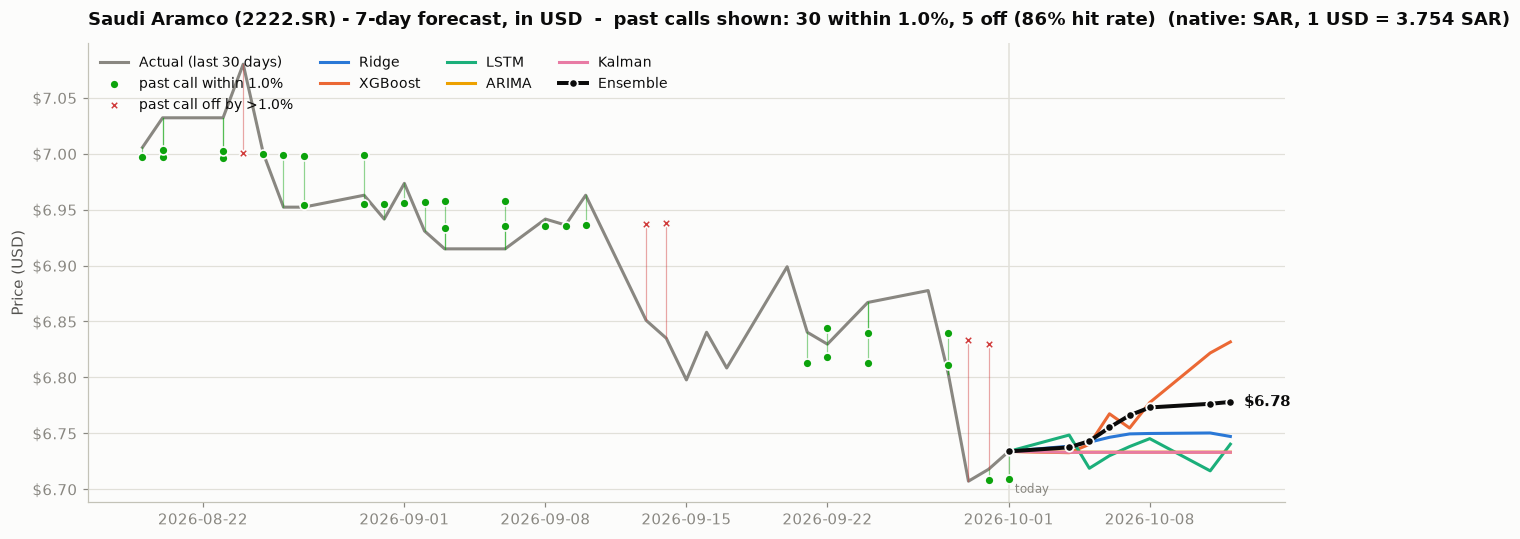


Predicted price by day, USD (native SAR: multiply by 3.754):
            Ridge  XGBoost  LSTM  ARIMA  Kalman  LASSO  RandomForest   DNN  WSAE-LSTM   TFT  Theta  N-BEATS  RegimeSwitch  ARIMAX  Ensemble  Fusion  Fusion-Top3
2026-10-04   6.74     6.73  6.75   6.73    6.73   6.73          6.74  6.81       6.72  6.79   6.73     6.73          6.73    6.73      6.74    6.74         6.74
2026-10-05   6.74     6.74  6.72   6.73    6.73   6.74          6.75  6.85       6.75  6.83   6.73     6.74          6.74    6.73      6.74    6.75         6.74
2026-10-06   6.75     6.77  6.73   6.73    6.73   6.74          6.77  6.90       6.73  6.84   6.73     6.74          6.74    6.73      6.76    6.75         6.75
2026-10-07   6.75     6.75  6.74   6.73    6.73   6.75          6.78  6.92       6.74  6.91   6.73     6.74          6.74    6.73      6.77    6.77         6.75
2026-10-08   6.75     6.78  6.75   6.73    6.73   6.75          6.79  6.94       6.74  6.86   6.74     6.73          6.74    6.73    

In [32]:
# ================================================================
# 7-DAY FORECAST GRAPH -- this company's price path, and the
# track record of what was predicted for the days already past
# ================================================================
# The Prediction Engine cell above gives ONE cumulative 7-day number and a
# BUY/HOLD/SELL. This cell answers the other question: what does the path look
# like day by day, and -- more usefully -- how did the last set of predictions
# actually turn out?
#
# Left of "today": grey is the real price; green dots and red crosses are what
# was forecast FOR those days before they happened, with a hairline down to
# what the price actually did. Right of "today": the next seven days.
#
# Every run archives its forecast to forecast_log/<TICKER>_forecasts.csv and
# grades any earlier forecast whose target date has now arrived, so the report
# card on the left builds itself as you keep running this notebook.

import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

import forecast_lib as fl

if COMPANY not in pl.TICKERS:
    print(f"WARNING: {COMPANY} is not in predictor_lib.TICKERS -- skipping the forecast graph.")
else:
    _fc = fl.forecast_ticker(COMPANY, verbose=True)
    fl.record_forecast(COMPANY, _fc)
    _newly_graded = fl.grade_forecasts(COMPANY)
    if _newly_graded:
        print(f"Graded {_newly_graded} past prediction(s) against what actually happened.")

    _SERIES = {"Ridge": "#2a78d6", "XGBoost": "#eb6834", "LSTM": "#1baf7a",
               "ARIMA": "#eda100", "Kalman": "#e87ba4"}
    _INK, _MUTED, _GRID, _SURF = "#0b0b0b", "#898781", "#e1e0d9", "#fcfcfb"
    _HIT, _MISS = "#0ca30c", "#d03b3b"

    plt.rcParams.update({
        "figure.facecolor": _SURF, "axes.facecolor": _SURF,
        "axes.edgecolor": "#c3c2b7", "axes.linewidth": 0.8,
        "axes.labelcolor": "#52514e", "text.color": _INK,
        "xtick.color": _MUTED, "ytick.color": _MUTED,
        "grid.color": _GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "font.family": "sans-serif", "font.size": 10, "figure.dpi": 110,
    })

    # Everything on this chart is shown in USD, converted at a single current
    # spot rate applied uniformly to past and future alike (no historical FX
    # series is fetched) -- "roughly what it was worth in USD", not an
    # FX-adjusted return series. For a USD company (AAPL, IBM) this is a no-op.
    _fx = _fc["fx_rate_to_usd"]
    _hist = _fc["raw"]["Close"].iloc[-30:] / _fx
    _paths = _fc["paths_usd"]
    _last_date, _last_price = _fc["last_date"], _fc["last_price_usd"]

    fig, ax = plt.subplots(figsize=(12, 5))
    ax.grid(True, axis="y", zorder=0)
    ax.set_axisbelow(True)
    ax.plot(_hist.index, _hist.values, color=_MUTED, linewidth=2, zorder=2,
            label="Actual (last 30 days)")

    _graded = fl.graded_points(COMPANY, model="Ensemble")
    _hit = _miss = 0
    if not _graded.empty:
        _g = _graded[_graded["target_date"] >= _hist.index[0]].copy()
        _g["predicted_price"] = _g["predicted_price"] / _fx
        _g["actual_price"] = _g["actual_price"] / _fx
        for _flag, _colour, _marker, _lbl in [
            (True, _HIT, "o", f"past call within {fl.TOLERANCE_PCT}%"),
            (False, _MISS, "X", f"past call off by >{fl.TOLERANCE_PCT}%"),
        ]:
            _sub = _g[_g["within_tolerance"] == _flag]
            if _sub.empty:
                continue
            if _flag:
                _hit = len(_sub)
            else:
                _miss = len(_sub)
            ax.scatter(_sub["target_date"], _sub["predicted_price"], s=34, c=_colour,
                       marker=_marker, zorder=5, linewidths=1.1,
                       edgecolors=_SURF, label=_lbl)
            for _, _r in _sub.iterrows():
                ax.plot([_r["target_date"], _r["target_date"]],
                        [_r["predicted_price"], _r["actual_price"]],
                        color=_colour, linewidth=0.8, alpha=0.45, zorder=3)

    for _model, _colour in _SERIES.items():
        if _model in _paths:
            ax.plot([_last_date] + list(_paths.index),
                    [_last_price] + list(_paths[_model].values),
                    color=_colour, linewidth=2, zorder=4, label=_model)
    ax.plot([_last_date] + list(_paths.index), [_last_price] + list(_paths["Ensemble"].values),
            color=_INK, linewidth=2.6, marker="o", markersize=5.5,
            markeredgecolor=_SURF, markeredgewidth=1.2, zorder=6, label="Ensemble")
    ax.annotate(f"${_paths['Ensemble'].iloc[-1]:,.2f}",
                xy=(_paths.index[-1], _paths["Ensemble"].iloc[-1]),
                xytext=(9, 0), textcoords="offset points",
                color=_INK, fontsize=10, va="center", fontweight="bold")

    ax.axvline(_last_date, color=_GRID, linewidth=1, zorder=1)
    ax.annotate("today", xy=(_last_date, ax.get_ylim()[0]), xytext=(4, 6),
                textcoords="offset points", color=_MUTED, fontsize=8)

    _scored = ""
    if _hit + _miss:
        _scored = (f"  -  past calls shown: {_hit} within {fl.TOLERANCE_PCT}%, "
                   f"{_miss} off ({_hit / (_hit + _miss):.0%} hit rate)")
    _native = "" if _fc["currency"] == "USD" else f"  (native: {_fc['currency']}, 1 USD = {_fx:.3f} {_fc['currency']})"
    ax.set_title(f"{_fc['company']} ({COMPANY}) - {fl.FORECAST_DAYS}-day forecast, in USD{_scored}{_native}",
                 loc="left", fontsize=11.5, color=_INK, fontweight="bold", pad=12)
    ax.set_ylabel("Price (USD)")
    _span = ax.get_ylim()[1] - ax.get_ylim()[0]
    _dp = 0 if _span > 20 else (1 if _span > 2 else 2)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _, d=_dp: f"${v:,.{d}f}"))
    for _spine in ("top", "right"):
        ax.spines[_spine].set_visible(False)
    ax.legend(frameon=False, fontsize=9, ncol=4, loc="upper left")
    fig.autofmt_xdate(rotation=0, ha="center")
    plt.tight_layout()
    plt.show()

    _table = _paths.round(2)
    _table.index = [d.date() for d in _table.index]
    _native_note = "" if _fc["currency"] == "USD" else f" (native {_fc['currency']}: multiply by {_fx:.3f})"
    print(f"\nPredicted price by day, USD{_native_note}:")
    print(_table.to_string())

    _acc = fl.accuracy_by_horizon(COMPANY, model="Ensemble")
    if not _acc.empty:
        print("\nTrack record -- how accuracy decays with distance:")
        print(_acc.to_string())

    log_step(
        "Forecast Graph",
        {"ticker": COMPANY, "horizon_days": fl.FORECAST_DAYS,
         "source": "forecast_lib (Ridge/XGBoost/LSTM/ARIMA/Kalman, multi-step)"},
        {"metrics": {
            "best_model": _fc["best_model"],
            "last_price_usd": round(_fc["last_price_usd"], 4),
            "forecast_final_price_usd": round(_fc["final_price_usd"], 4),
            "native_price": round(_fc["last_price"], 4),
            "native_currency": _fc["currency"],
            "total_move_pct": round(_fc["total_return_pct"], 3),
            "direction": _fc["direction"],
            "past_calls_within_tolerance": _hit,
            "past_calls_off": _miss,
        }},
    )


## 🔍 Decision Verifier / Fact-Check Agent — Post-Decision Recheck

In [ ]:
# ================================================================
# 🔍 DECISION VERIFIER / FACT-CHECK AGENT — নতুন Agent
# ================================================================
# Portfolio Manager-এর final decision নেওয়ার পরে চলে। ৯টা agent
# sequentially একে অপরের output-এর উপর নির্ভর করে বলে, শুরুর দিকের
# কোনো hallucination/ভুল ডেটা পুরো chain বেয়ে propagate হয়ে final
# decision পর্যন্ত পৌঁছাতে পারে — এই agent সেটা catch করার জন্য।
#
# কাজ করে দুই ধাপে:
#   1) Rule-based sanity check — RSI/news sentiment বনাম final_signal
#      সরাসরি contradict করছে কিনা
#   2) Numeric contradiction check — এখন DETERMINISTIC (Python regex +
#      tolerance), LLM-এর উপর নির্ভর করে না। ছোট local model (qwen2.5:7b)
#      decimal rounding-কে বারবার ভুলভাবে "contradiction" বলছিল (যেমন
#      68.17 vs 68.16905051254318-কে "genuine difference" বলে দিয়েছিল),
#      তাই এই arithmetic judgment আর LLM-কে দেওয়া হচ্ছে না।
#   3) LLM semantic check — শুধু SIGNAL_CONSISTENT (decision text নিজের
#      logic-এর সাথে নিজেই contradict করছে কিনা)। এটা ADVISORY — একা এটা
#      দিয়ে status FLAGGED হবে না, কারণ ৭B মডেলের এই subjective judgment-ও
#      বারবার over-trigger করছিল (হালকা hedge/caveat ভাষাকেও "inconsistent"
#      বলে দিচ্ছিল)।

import re
from langchain_ollama import ChatOllama

llm_verifier = ChatOllama(model="qwen2.5:7b", base_url="http://localhost:11434", num_ctx=8192, temperature=0, repeat_penalty=1.15, num_predict=2048)


def rule_based_checks(final_signal: str, indicators: dict, news_metrics: dict,
                       fundamentals_report: str = "") -> tuple:
    """সহজ contradiction checks চালায়। রিটার্ন করে (warnings, info_notes) —
    warnings status-কে FLAGGED করে, info_notes শুধু transparency-র জন্য
    দেখানো হয় কিন্তু status বদলায় না।
    """
    warnings = []
    info_notes = []

    fund_verdict = extract_final_proposal(fundamentals_report)
    fund_verdict_upper = fund_verdict.upper() if fund_verdict else ""
    fund_agrees_with_final = bool(fund_verdict) and final_signal in fund_verdict_upper

    def _add(msg: str):
        (info_notes if fund_agrees_with_final else warnings).append(msg)

    rsi = indicators.get("rsi")
    try:
        rsi_val = float(rsi)
        if rsi_val >= 70 and final_signal == "BUY":
            _add(f"RSI={rsi_val} overbought অঞ্চলে (>=70), কিন্তু signal BUY — সম্ভাব্য contradiction।")
        if rsi_val <= 30 and final_signal == "SELL":
            _add(f"RSI={rsi_val} oversold অঞ্চলে (<=30), কিন্তু signal SELL — সম্ভাব্য contradiction।")
    except (TypeError, ValueError):
        pass

    overall_sent = str(news_metrics.get("overall_sentiment", "")).lower()
    if "negative" in overall_sent and final_signal == "BUY":
        _add("News sentiment negative, কিন্তু signal BUY — যাচাই দরকার।")
    if "positive" in overall_sent and final_signal == "SELL":
        _add("News sentiment positive, কিন্তু signal SELL — যাচাই দরকার।")

    if fund_agrees_with_final and info_notes:
        info_notes.append(
            "ℹ️ উপরের technical/sentiment contradiction(গুলো) FLAG করা হয়নি, কারণ "
            "Fundamentals Analyst-এর নিজের HARD verdict (" + fund_verdict + ") ইতিমধ্যে "
            "final signal-এর সাথে align করে -- অর্থাৎ strong fundamentals soft "
            "sentiment/technical-কে ন্যায্যভাবে override করেছে।"
        )

    if fund_verdict:
        if "SELL" in fund_verdict_upper and final_signal == "BUY":
            warnings.append(
                "Fundamentals Analyst নিজে SELL বলেছিল (" + fund_verdict + "), কিন্তু final signal BUY -- "
                "debate/trader/PM chain এই verdict override করেছে, সরাসরি যাচাই দরকার।"
            )
        elif "BUY" in fund_verdict_upper and final_signal == "SELL":
            warnings.append(
                "Fundamentals Analyst নিজে BUY বলেছিল (" + fund_verdict + "), কিন্তু final signal SELL -- "
                "debate/trader/PM chain এই verdict override করেছে, সরাসরি যাচাই দরকার।"
            )

    return warnings, info_notes


# ── ✅ NEW: deterministic numeric-contradiction check (no LLM involved) ──
def _extract_cited_number(text: str, label_patterns: list) -> float | None:
    """Decision text-এ label-এর (যেমন RSI, MACD) ঠিক পরে যে সংখ্যাটা লেখা আছে
    সেটা বের করে। প্রথম যেটা মেলে সেটাই নেয়।"""
    for label in label_patterns:
        m = re.search(rf'{label}\s*(?:\([^)]*\))?\s*[:=]?\s*(-?\d+\.?\d*)', text, re.IGNORECASE)
        if m:
            try:
                return float(m.group(1))
            except ValueError:
                continue
    return None


def check_numeric_contradiction(final_decision_text: str, indicators: dict,
                                 fund_metrics: dict) -> list:
    """Decision text-এ cite করা প্রতিটা সংখ্যাকে raw ground-truth-এর সাথে
    tolerance রেখে compare করে। rounding/truncation সবসময় খুব ছোট একটা
    relative difference তৈরি করে, তাই generous tolerance ব্যবহার করলে
    'একই সংখ্যা, কম decimal' বনাম 'সত্যিকারের ভুল সংখ্যা' নির্ভরযোগ্যভাবে
    আলাদা করা যায় — এবং এখানে LLM-এর কোনো ভূমিকা নেই, তাই ভুল arithmetic
    judgment দেওয়ার সুযোগ নেই।
    """
    checks = [
        ("RSI", ["RSI"], indicators.get("rsi")),
        ("MACD", ["MACD"], indicators.get("macd")),
        ("P/E Ratio", ["P/E Ratio", "P/E"], fund_metrics.get("pe_ratio")),
        ("EPS (latest period)", ["EPS \\(TTM\\)", "EPS"], fund_metrics.get("eps_ttm")),
    ]
    mismatches = []
    for label, patterns, raw in checks:
        if raw in (None, "", "N/A"):
            continue
        try:
            raw_val = float(raw)
        except (TypeError, ValueError):
            continue
        cited = _extract_cited_number(final_decision_text, patterns)
        if cited is None:
            continue
        diff = abs(cited - raw_val)
        tolerance = max(0.5, 0.02 * abs(raw_val))  # rounding-tolerant: 2% relative or 0.5 absolute
        if diff > tolerance:
            mismatches.append(
                f"{label}: decision text-এ লেখা {cited}, কিন্তু raw data অনুযায়ী {raw_val} "
                f"(diff={diff:.2f}, tolerance={tolerance:.2f}) — সম্ভাব্য genuine mismatch।"
            )
    return mismatches


def check_fact_semantics(final_decision_text: str, indicators: dict, fund_metrics: dict, market_result: dict) -> list:
    """Code-computed checks for the errors the numeric-presence check cannot see (found in a real run):
    SMA called 'support' while price is below it, an N/A dividend yield cited as 0%, 'no dividend' next to a long dividend
    history, missing DSEX data read as 'neutral', and the GNN rank called a 'sector position'."""
    out, text = [], str(final_decision_text)
    try:
        px = None
        for line in str((market_result.get("market_raw_data") or {}).get("stock_data", "")).splitlines():
            p = [x.strip() for x in line.split(",")]
            if len(p) >= 5 and re.match(r"\d{4}-\d{2}-\d{2}$", p[0]):
                px = float(p[4])
        if px is None:
            px = float(fund_metrics.get("last_trading_price"))
    except Exception:
        px = None
    sma = indicators.get("close_50_sma")
    neg = re.compile(r"\b(not|no|isn't|doesn't|does not|fails?|failed|without|lack|break(?:s|ing)?\s+(?:below|through|above)|if|until|unless)\b", re.I)
    if px is not None and isinstance(sma, (int, float)) and sma:
        for sent in re.split(r"(?<=[.!?])\s+|\n", text):
            sl = sent.lower()
            if ("sma" in sl or "moving average" in sl) and re.search(r"stop[- ]?loss", sl) and px < sma and not re.search(r"\\b(above|over)\\b", sl):
                out.append(f"Stop-loss: placed at the 50-day SMA {sma}, which is ABOVE the price {px} (invalid for a long position): \"{sent.strip()[:110]}\"")
                continue
            if not ("sma" in sl or "moving average" in sl) or neg.search(sl):
                continue
            if re.search(r"\bsupport", sl) and px < sma:
                out.append(f"SMA direction: text calls the 50-day SMA {sma} support, but price {px} is BELOW it (the SMA is resistance): \"{sent.strip()[:110]}\"")
            elif re.search(r"\bresistance", sl) and px > sma:
                out.append(f"SMA direction: text calls the 50-day SMA {sma} resistance, but price {px} is ABOVE it (the SMA is support): \"{sent.strip()[:110]}\"")
    dy = str(fund_metrics.get("dividend_yield", "N/A"))
    if dy in ("N/A", "None", "") and re.search(r"dividend yield[^.\n]{0,25}?\b0(?:\.0+)?\s*%", text, re.I):
        out.append("Dividend yield: the data field is N/A (DSE publishes no yield) but the text cites it as 0%.")
    cash = str(fund_metrics.get("cash_dividend", ""))
    if re.search(r"\d+\s*%", cash) and re.search(r"\b(lack of|no|zero|without|absence of)\s+(?:a\s+)?(?:cash\s+)?dividend", text, re.I):
        out.append(f"Dividend: text claims no dividend, but the DSE history shows payouts ({cash[:60]}).")
    mres = globals().get("macro_result") or {}
    if mres.get("dsex_data_ok") is False and re.search(r"(absence|lack)\s+of[^.\n]{0,80}(volatil|trend|data)[^.\n]{0,100}\bneutral|\bno\s+(?:realized\s+)?volatil[^.\n]{0,80}\bneutral", text, re.I):
        out.append("Macro: DSEX data was UNAVAILABLE, but the text reads that absence as a 'neutral' market (missing data is unknown, not neutral).")
    if re.search(r"sector\s+(?:position|rank)[^.\n]{0,25}\d+(?:st|nd|rd|th)?\s*(?:/|out of)\s*\d+", text, re.I):
        out.append("GNN: the rank is across ALL graph stocks, not a sector position/rank.")
    return out


def llm_signal_consistency_check(final_decision_text: str, llm) -> str:
    """শুধু SIGNAL_CONSISTENT check করে LLM দিয়ে — এটা genuinely subjective/
    semantic একটা প্রশ্ন, তাই এখানেই LLM রাখা হয়েছে। কিন্তু এর ফলাফল
    এখন advisory-only (নিচে run_decision_verifier দেখুন)।"""
    prompt = f"""You are a fact-checking auditor reviewing a trading decision before it is finalized.

=== FINAL DECISION TEXT ===
{final_decision_text[:1200]}

Check ONLY this one thing:

Respond with ONE strict marker line FIRST (machine-parsed), THEN your explanation
— do not paraphrase the marker:
SIGNAL_CONSISTENT: YES or NO

RULES (read carefully before answering):
- HOLD is a legitimate, self-consistent conclusion whenever the inputs are mixed --
  e.g. overbought/oversold technicals pulling one way while fundamentals or news
  sentiment pull the other way. Mentioning a caution/risk factor and then still
  making a call (BUY/HOLD/SELL) is NORMAL trading commentary, not an inconsistency.
- Only answer NO if the decision text's OWN stated reasoning DIRECTLY and STRONGLY
  contradicts its OWN action -- e.g. the text says "this is a clear sell signal" or
  "there is no reason to buy" but then names BUY as the action. A hedge like
  "shows some overbought risk but still has growth potential" followed by BUY is
  CONSISTENT, not a contradiction -- do not flag it.
- Default to YES unless the contradiction is obvious and severe.

Then, in 1-2 short bullet points, if SIGNAL_CONSISTENT is NO, quote the specific
phrase in the decision text whose own reasoning contradicts its own action.

Be concise and only flag REAL, severe discrepancies -- do not invent problems.
"""
    try:
        response = llm.invoke(prompt)
        return response.content.strip()
    except Exception as e:
        return f"(LLM fact-check failed: {e})"


def run_decision_verifier(final_decision_text: str, market_result: dict,
                           fundamentals_result: dict, news_result: dict,
                           sentiment_result: dict, llm) -> dict:
    """Rule-based + deterministic numeric check + LLM semantic check চালায়,
    VERIFIED/FLAGGED status রিটার্ন করে।"""
    indicators = market_result.get("indicators_parsed", {})
    fund_metrics = fundamentals_result.get("fund_metrics", {})
    news_metrics = news_result.get("news_metrics", {})
    sentiment_metrics = sentiment_result.get("sentiment_metrics", {})

    sig_match = re.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", final_decision_text, re.IGNORECASE)
    final_signal = sig_match.group(1).upper() if sig_match else "N/A"

    # v8: the verdict only reaches the verifier if FUND_NUMBERS_ONLY is off or FUND_VERDICT_TO_VERIFIER is on
    _fr_for_verifier = fundamentals_result.get("fundamentals_report", "")
    if (not FUND_NUMBERS_ONLY) or FUND_VERDICT_TO_VERIFIER:
        _fr_for_verifier = fundamentals_result.get("fundamentals_report_llm") or _fr_for_verifier
    rule_warnings, rule_info_notes = rule_based_checks(
        final_signal, indicators, news_metrics,
        fundamentals_report=_fr_for_verifier,
    )

    # ✅ NEW: numeric contradiction is now code-computed, not LLM-judged
    numeric_mismatches = check_numeric_contradiction(final_decision_text, indicators, fund_metrics)
    numeric_mismatches += check_fact_semantics(final_decision_text, indicators, fund_metrics, market_result)

    llm_notes = llm_signal_consistency_check(final_decision_text, llm)

    llm_call_failed = "(llm fact-check failed" in llm_notes.lower()
    signal_consistent_m = re.search(r"SIGNAL_CONSISTENT:\s*(YES|NO)", llm_notes, re.IGNORECASE)
    signal_inconsistent = bool(signal_consistent_m and signal_consistent_m.group(1).upper() == "NO")
    markers_missing = signal_consistent_m is None

    # ✅ status এখন শুধু hard/reliable signal দিয়ে ঠিক হয়: rule-based
    # contradiction, code-verified numeric mismatch, বা LLM call fail/format
    # miss। LLM-এর SIGNAL_CONSISTENT opinion আর একা status FLAGGED করে না —
    # ৭B মডেলের এই subjective judgment বারবার over-trigger করছিল।
    status = "FLAGGED" if (rule_warnings or numeric_mismatches or llm_call_failed or markers_missing) else "VERIFIED"

    notes_parts = []
    if rule_warnings:
        notes_parts.append("Rule-based: " + " | ".join(rule_warnings))
    if rule_info_notes:
        notes_parts.append("Rule-based (info, non-flagging): " + " | ".join(rule_info_notes))
    if numeric_mismatches:
        notes_parts.append("Numeric check (code, non-LLM): " + " | ".join(numeric_mismatches))
    notes_parts.append(
        "LLM semantic check (advisory, does NOT affect status): " + llm_notes
    )
    notes = "\n".join(notes_parts)

    fundamentals_contradiction = any("Fundamentals Analyst নিজে" in w for w in rule_warnings)
    effective_signal = final_signal
    if fundamentals_contradiction and final_signal != "HOLD":
        effective_signal = "HOLD"
        notes += (
            f"\n\n[LOCKED] AUTO-OVERRIDE: Fundamentals Analyst-এর verdict-এর সাথে সরাসরি contradiction "
            f"পাওয়া গেছে -- raw signal ছিল {final_signal}, কিন্তু effective/actionable signal জোর করে "
            f"HOLD-এ নামিয়ে দেওয়া হলো। কারণ ছাড়া trade না করাই নিরাপদ।"
        )

    return {
        "status": status,
        "notes": notes,
        "final_signal": final_signal,
        "effective_signal": effective_signal,
        "auto_overridden": fundamentals_contradiction and final_signal != "HOLD",
    }


# ── ACTUALLY RUN IT ──
print("=" * 60)
print("🔍 DECISION VERIFIER / FACT-CHECK")
print("=" * 60)

verification_result = run_decision_verifier(
    final_decision_text, market_result, fundamentals_result,
    news_result, sentiment_result, llm_verifier,
)

status_icon = "✅" if verification_result["status"] == "VERIFIED" else "⚠️"
print(f"{status_icon} Verification Status: {verification_result['status']}")
print(f"\n📋 Notes:\n{verification_result['notes']}")
if verification_result["auto_overridden"]:
    print(f"\n[LOCKED] ACTIONABLE SIGNAL: {verification_result['effective_signal']} "
          f"(raw model output was {verification_result['final_signal']}, auto-downgraded)")
else:
    print(f"\n[OK] ACTIONABLE SIGNAL: {verification_result['effective_signal']}")
print("=" * 60)
print()

log_step(
    "Decision Verifier",
    {"final_signal": verification_result["final_signal"]},
    {
        "status": verification_result["status"],
        "notes": verification_result["notes"],
        "effective_signal": verification_result["effective_signal"],
        "auto_overridden": verification_result["auto_overridden"],
    },
)

## 📐 Position Sizing — rule-based vol-target + market-stress thermometer (v7) + gated RL (PPO) overlay

v7: size = min(MAX_WEIGHT, TARGET_VOL / vol) × market-stress multiplier, where vol = max(EWMA20, 60-day) and the stress multiplier comes from an equal-weight index of the other graph-panel stocks. HOLD can now trim a position that exceeds the cap. Switches: `USE_MARKET_STRESS`, `USE_RL_OVERLAY`, `RUN_SIZING_PRICE_BACKTEST`.


In [ ]:
# ================================================================
# 📐 POSITION SIZING — (A) rule-based vol-target sizing + (B) gated PPO overlay
# ================================================================
# WHY THIS EXISTS (see the RL discussion): the LLM agents decide DIRECTION (BUY/HOLD/SELL).
# This cell decides HOW MUCH, and it runs AFTER the Decision Verifier so it uses the
# verified `effective_signal`. It does not change the agents' decision and it feeds nothing
# back into any LLM prompt (no circularity). The output is an ADVISORY PAPER position
# (fraction of capital in 2222.SR), not an order. Long-only: DSE retail cannot short, so
# SELL = go flat.
#
# (A) RULES (always on, explainable)   -- v7 changes marked [v7]:
#     risk cap = min(MAX_WEIGHT, TARGET_VOL / vol) x market_stress_mult x (verifier-FLAGGED haircut)
#       [v7] vol = max(EWMA20, 60-day) so a calm month cannot hide a regime change
#       [v7] market_stress_mult comes from an equal-weight index of the other graph-panel stocks
#            (the DSEX endpoint is dead): index 20d return <= -2.5% -> x0.75, <= -5% -> x0.5
#       [v7] defaults lowered (TARGET_VOL 10%, MAX_WEIGHT 80%) -- at 15%/100% the cap bound almost every
#            calm day, so "sizing" was just "all in"
#     BUY  -> target = risk cap (x RL scale if the overlay validated)
#     SELL -> 0 (exit)
#     HOLD -> [v7] keep the position but TRIM it if it is above the current risk cap (never adds)
#     NO-TRADE BAND: changes smaller than SIZING_BAND are skipped (turnover control, the one
#     thing the RL policy mainly learned in the BlindTrade ablation). Entries below
#     SIZING_MIN_WEIGHT are skipped.
# (B) RL OVERLAY (optional, needs torch): a tiny PPO policy with a Differential-Sharpe reward and
#     transaction costs, trained walk-forward on PRICE features only (no LLM history exists to
#     train on). It picks an exposure scale in {0, 0.5, 1} that multiplies the BUY size. It is
#     only used if it VALIDATES: on a held-out final SIZING_HOLDOUT days it must beat the plain
#     vol-target baseline (net of costs) with a positive Sharpe in most seeds. Otherwise scale = 1.
#     With ~60 holdout days the Sharpe is very noisy (SE ~ 2) -- the gate is a safety check,
#     not proof of skill, and it will often (correctly) say NOT_VALIDATED.
import os, json, warnings
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

warnings.filterwarnings("ignore", message="Mean of empty slice")

# ── Config ───────────────────────────────────────────────────────
SIZING_TARGET_VOL_ANN = 0.10     # annualised vol the position is scaled to   [v7: was 0.15 -- TUNE with the price-only backtest]
SIZING_MAX_WEIGHT     = 0.80     # max fraction of capital in this stock       [v7: was 1.0  -- TUNE with the price-only backtest]
SIZING_VOL_LONG_SPAN  = 60       # [v7] slow vol window (days); vol used = max(EWMA20, this)
USE_MARKET_STRESS     = True     # [v7] ablation switch: False = no market-stress scaling
STRESS_WEAK_RET20     = -0.025   # [v7] equal-weight index 20-trading-day return at/below this -> WEAK
STRESS_RET20          = -0.05    # [v7] ... at/below this -> STRESS
STRESS_WEAK_MULT      = 0.75     # [v7] size multiplier in WEAK
STRESS_MULT           = 0.50     # [v7] size multiplier in STRESS
STRESS_MIN_PEERS      = 15       # [v7] need at least this many other stocks to trust the index
SIZING_REBALANCE_ON_HOLD = True  # [v7] HOLD may trim a position that exceeds the risk cap (never adds)
USE_RL_OVERLAY        = True     # [v7] False skips the PPO overlay entirely (faster; it rarely validates)
RUN_SIZING_PRICE_BACKTEST = False  # [v7] True = LLM-free backtest of old vs new sizing on the 51-stock panel
SIZING_MIN_WEIGHT     = 0.10     # don't open a position smaller than this
SIZING_BAND           = 0.20     # no-trade band (abs change in weight) for adjustments
SIZING_FLAGGED_HAIRCUT = 0.5     # multiply the risk cap if the Decision Verifier FLAGGED the decision [v7: also applies to HOLD trims]
SIZING_COST           = 0.005    # ONE-WAY cost fraction (PLACEHOLDER -- set to your broker's real one-way cost)
SIZING_LOOKBACK_DAYS  = 900      # calendar days of price history (~600 trading days)
SIZING_HOLDOUT        = 60       # last N trading days held out to validate the RL overlay
SIZING_RL_SEEDS       = 5
SIZING_RL_ITERS       = 60       # PPO updates per seed (each = one 120-day episode)
SIZING_RL_ACTIONS     = [0.0, 0.5, 1.0]
SIZING_STATE_FILE     = "position_state_2222_SR.json"
_TD = 250                        # trading days per year (annualisation)


# ── helpers ──────────────────────────────────────────────────────
def _sz_prices(company: str, as_of: str):
    start = (datetime.strptime(as_of, "%Y-%m-%d") - timedelta(days=SIZING_LOOKBACK_DAYS)).strftime("%Y-%m-%d")
    try:
        df = fetch_dse_ohlcv_range(company, start, as_of)
    except Exception as e:
        print(f"   ⚠️ sizing: price fetch failed: {str(e)[:120]}")
        return None
    if df is None or df.empty:
        return None
    c = df["Close"].where(df["Close"] > 0).dropna()
    return c if len(c) >= 150 else None


def _sz_load_state() -> list:
    try:
        with open(SIZING_STATE_FILE, "r", encoding="utf-8") as f:
            return list(json.load(f).get("history", []))
    except Exception:
        return []


def _sz_save_state(history: list):
    try:
        with open(SIZING_STATE_FILE, "w", encoding="utf-8") as f:
            json.dump({"note": "advisory PAPER position (fraction of capital) per trade date", "history": history}, f, indent=1)
    except Exception as e:
        print(f"   ⚠️ sizing: could not save state: {e}")


def _sz_recompute_equity(history: list) -> list:
    """[v7] Paper equity curve of the advisory positions: the weight held from one decision date to the next earns
    the stock's return between those dates, minus SIZING_COST on every weight change. Recomputed from scratch on each
    save, so re-running an older date never leaves stale numbers. Entries without a stored price (written by older
    versions) restart the chain. Decision-date-to-decision-date only -- NOT a daily marked equity."""
    eq, prev = 1.0, None
    for h in history:
        p, w = h.get("price"), float(h.get("weight", 0.0))
        if not p or not p > 0:
            h.pop("equity", None); eq, prev = 1.0, None
            continue
        if prev is None:
            eq *= (1 - SIZING_COST * w)
        else:
            eq *= (1 + prev["w"] * (p / prev["p"] - 1) - SIZING_COST * abs(w - prev["w"]))
        h["equity"] = round(eq, 5)
        prev = {"p": float(p), "w": w}
    return history


def _sz_current_weight(history: list, as_of: str) -> float:
    """Position BEFORE today's decision: last entry strictly before as_of (re-runs on the same day
    never compound on each other)."""
    prev = [h for h in history if h.get("date", "") < as_of]
    return float(prev[-1]["weight"]) if prev else 0.0


def _sz_vol_series(close: pd.Series) -> pd.Series:
    """[v7] annualised vol = max(EWMA20, 60-day std). np.fmax ignores NaN, so early rows fall back to EWMA20."""
    r = close.pct_change()
    fast = r.ewm(span=20, adjust=False).std()
    slow = r.rolling(SIZING_VOL_LONG_SPAN, min_periods=30).std()
    return pd.Series(np.fmax(fast.to_numpy(), slow.to_numpy()) * np.sqrt(_TD), index=close.index)


def _sz_realised_vol_ann(close: pd.Series) -> float:
    v = _sz_vol_series(close).iloc[-1]
    return float(v) if np.isfinite(v) and v > 0 else float("nan")


def _sz_vol_parts(close: pd.Series):
    """(EWMA20 vol, 60-day vol), annualised -- only for the printed report."""
    r = close.pct_change()
    f = r.ewm(span=20, adjust=False).std().iloc[-1] * np.sqrt(_TD)
    sl = r.rolling(SIZING_VOL_LONG_SPAN, min_periods=30).std().iloc[-1] * np.sqrt(_TD)
    return (float(f) if np.isfinite(f) else None), (float(sl) if np.isfinite(sl) else None)


def _stress_level(ret20: float):
    if ret20 <= STRESS_RET20:
        return "STRESS", STRESS_MULT
    if ret20 <= STRESS_WEAK_RET20:
        return "WEAK", STRESS_WEAK_MULT
    return "NORMAL", 1.0


def market_stress_from_panel(close_df, company: str, as_of: str) -> dict:
    """[v7] Market-stress thermometer from an equal-weight index of the OTHER panel stocks (company excluded, so
    the index does not contain the stock being sized). Uses rows <= as_of only. Pure function -> unit-testable."""
    out = {"status": "UNAVAILABLE", "level": "UNKNOWN", "mult": 1.0}
    try:
        if close_df is None or len(close_df) == 0:
            out["reason"] = "no panel"; return out
        px = close_df.drop(columns=[company], errors="ignore").copy()
        px.index = pd.to_datetime(px.index)
        px = px.loc[:pd.Timestamp(as_of)]
        px = px.dropna(axis=1, thresh=int(0.7 * max(len(px), 1)))
        if px.shape[1] < STRESS_MIN_PEERS or len(px) < 25:
            out["reason"] = f"only {px.shape[1]} stocks / {len(px)} days"; return out
        if (pd.Timestamp(as_of) - px.index[-1]).days > 7:
            out["reason"] = f"panel is stale (last row {px.index[-1].date()})"; return out
        r = px.pct_change(fill_method=None)
        lvl = (1 + r.mean(axis=1, skipna=True).fillna(0.0)).cumprod()
        ret20 = float(lvl.iloc[-1] / lvl.iloc[-21] - 1)
        breadth_down = float(((px.iloc[-1] / px.iloc[-21] - 1) < 0).mean())
        level, mult = _stress_level(ret20)
        out.update({"status": "OK", "level": level, "mult": mult, "index_ret20_pct": round(ret20 * 100, 2),
                    "breadth_down_pct": round(breadth_down * 100, 0), "n_stocks": int(px.shape[1]),
                    "last_row": str(px.index[-1].date())})
    except Exception as e:
        out["reason"] = str(e)[:100]
    return out


def _sz_features(close: pd.Series) -> np.ndarray:
    """Causal features only (rolling windows, no global statistics -> no look-ahead). [T, 6]"""
    r1 = close.pct_change()
    v20 = r1.rolling(20, min_periods=10).std().replace(0, np.nan)
    v60 = r1.rolling(60, min_periods=20).std().replace(0, np.nan)
    delta = close.diff()
    gain = delta.clip(lower=0).rolling(14, min_periods=5).mean()
    loss = (-delta.clip(upper=0)).rolling(14, min_periods=5).mean()
    rsi = (100 - 100 / (1 + gain / loss.replace(0, np.nan))) / 100 - 0.5
    f = pd.DataFrame({
        "r1": r1 / v20,
        "r5": close.pct_change(5) / (v20 * np.sqrt(5)),
        "r20": close.pct_change(20) / (v20 * np.sqrt(20)),
        "trend": (close / close.rolling(50, min_periods=20).mean() - 1) / (v20 * np.sqrt(50)),
        "rsi": rsi * 2,
        "volreg": (v20 / v60 - 1),
    }, index=close.index)
    return np.nan_to_num(f.clip(-3, 3).to_numpy(copy=True), nan=0.0)


def _sz_metrics(net: np.ndarray, turnover: float) -> dict:
    net = np.asarray(net, dtype=float)
    sd = net.std(ddof=1) if len(net) > 2 else np.nan
    sharpe = float(net.mean() / sd * np.sqrt(_TD)) if sd and np.isfinite(sd) and sd > 1e-12 else 0.0
    eq = np.cumprod(1 + net)
    mdd = float((eq / np.maximum.accumulate(eq) - 1).min()) if len(eq) else 0.0
    return {"sharpe": round(sharpe, 3), "total_return_pct": round(float(eq[-1] - 1) * 100, 2) if len(eq) else 0.0,
            "max_drawdown_pct": round(mdd * 100, 2), "turnover": round(float(turnover), 2)}


def _sz_simulate(weights: np.ndarray, rn: np.ndarray):
    """weights[t] = position held from close t to close t+1; rn[t] = next-day return. Net of costs."""
    prev = np.concatenate([[0.0], weights[:-1]])
    turn = np.abs(weights - prev)
    net = weights * rn - SIZING_COST * turn
    return net, float(turn.sum())


def _sz_voltarget_weights(close: pd.Series, idx: np.ndarray) -> np.ndarray:
    """Always-long vol-target baseline WITH the same no-trade band, evaluated on dates idx."""
    r = close.pct_change()
    vol = _sz_vol_series(close).to_numpy()                      # [v7] same vol definition as the live rule
    w, cur = [], 0.0
    for t in idx:
        tgt = float(np.clip(SIZING_TARGET_VOL_ANN / vol[t], 0, SIZING_MAX_WEIGHT)) if np.isfinite(vol[t]) and vol[t] > 0 else cur
        if cur == 0.0 and tgt >= SIZING_MIN_WEIGHT:
            cur = tgt
        elif cur > 0.0 and abs(tgt - cur) >= SIZING_BAND:
            cur = tgt
        w.append(cur)
    return np.array(w)


# ── (B) PPO overlay ──────────────────────────────────────────────
def _sz_train_ppo(F: np.ndarray, rn: np.ndarray, t_lo: int, t_hi: int, seed: int, iters: int):
    """Trains on days [t_lo, t_hi) (rn must be valid there). Returns a policy callable
    probs(feature_row, prev_pos) -> action probabilities."""
    import torch, torch.nn as nn
    from torch.distributions import Categorical
    torch.manual_seed(seed); rng = np.random.default_rng(seed)
    nF, nA = F.shape[1] + 1, len(SIZING_RL_ACTIONS)
    pi = nn.Sequential(nn.Linear(nF, 16), nn.Tanh(), nn.Linear(16, nA))
    vf = nn.Sequential(nn.Linear(nF, 16), nn.Tanh(), nn.Linear(16, 1))
    opt = torch.optim.Adam(list(pi.parameters()) + list(vf.parameters()), lr=3e-3)
    EP, gamma, lam, eta = 120, 0.99, 0.95, 0.02

    for _ in range(iters):
        s0 = int(rng.integers(t_lo, max(t_lo + 1, t_hi - EP)))
        obs, acts, lps, rews, vals = [], [], [], [], []
        prev, A, B = 0.0, 0.0, 1e-4                        # DSR moments (B init = 1% daily vol)
        for t in range(s0, min(s0 + EP, t_hi)):
            o = torch.tensor(np.append(F[t], prev), dtype=torch.float32)
            with torch.no_grad():
                d = Categorical(logits=pi(o)); a = d.sample(); lp = d.log_prob(a); v = vf(o).squeeze()
            pos = SIZING_RL_ACTIONS[int(a)]
            net = pos * rn[t] - SIZING_COST * abs(pos - prev)
            dA, dB = net - A, net * net - B               # Differential Sharpe Ratio (Moody & Saffell)
            den = (B - A * A) ** 1.5
            r = float(np.clip((B * dA - 0.5 * A * dB) / den, -5, 5)) if den > 1e-12 else 0.0
            A, B = A + eta * dA, B + eta * dB
            obs.append(o); acts.append(a); lps.append(lp); rews.append(r); vals.append(v); prev = pos
        n = len(rews)
        if n < 10:
            continue
        vals_t = torch.stack(vals).detach().numpy(); last_v = 0.0
        adv, gae = np.zeros(n), 0.0
        for i in reversed(range(n)):
            nv = vals_t[i + 1] if i + 1 < n else last_v
            delta = rews[i] + gamma * nv - vals_t[i]
            gae = delta + gamma * lam * gae; adv[i] = gae
        ret = torch.tensor(adv + vals_t, dtype=torch.float32)
        advt = torch.tensor((adv - adv.mean()) / (adv.std() + 1e-8), dtype=torch.float32)
        O, Ac, LP = torch.stack(obs), torch.stack(acts), torch.stack(lps)
        for _k in range(4):                                # PPO epochs
            d = Categorical(logits=pi(O))
            ratio = torch.exp(d.log_prob(Ac) - LP)
            loss_pi = -torch.min(ratio * advt, torch.clamp(ratio, 0.8, 1.2) * advt).mean() - 0.01 * d.entropy().mean()
            loss_v = ((vf(O).squeeze(-1) - ret) ** 2).mean()
            opt.zero_grad(); (loss_pi + 0.5 * loss_v).backward(); opt.step()

    def probs(row, prev_pos):
        with torch.no_grad():
            return torch.softmax(pi(torch.tensor(np.append(row, prev_pos), dtype=torch.float32)), -1).numpy()
    return probs


def _sz_eval_policy(probs, F, rn, idx):
    w, prev = [], 0.0
    for t in idx:
        prev = SIZING_RL_ACTIONS[int(np.argmax(probs(F[t], prev)))]
        w.append(prev)
    return np.array(w)


def _sz_run_rl(close: pd.Series, cur_w: float) -> dict:
    out = {"status": "NOT_RUN", "scale": 1.0}
    try:
        import torch  # noqa: F401
    except ImportError:
        out["reason"] = "torch not installed"; return out
    try:
        F = _sz_features(close)
        rn = close.pct_change().shift(-1).to_numpy(copy=True)          # next-day return (NaN on last row)
        T = len(close)
        t_hold0 = T - 1 - SIZING_HOLDOUT                                # holdout days: [t_hold0, T-1)
        t_lo, t_hi = 60, t_hold0 - 1                                    # purge: last train day's next-day return < holdout start
        if t_hi - t_lo < 200:
            out["status"] = "INSUFFICIENT_DATA"; out["reason"] = f"only {t_hi - t_lo} training days (need >= 200)"; return out
        hold_idx = np.arange(t_hold0, T - 1)
        base_w = _sz_voltarget_weights(close, hold_idx)
        bh_net, bh_turn = _sz_simulate(np.ones(len(hold_idx)), rn[hold_idx])
        base_net, base_turn = _sz_simulate(base_w, rn[hold_idx])
        base_m, bh_m = _sz_metrics(base_net, base_turn), _sz_metrics(bh_net, bh_turn)

        seed_m = []
        for s in range(SIZING_RL_SEEDS):
            pr = _sz_train_ppo(F, rn, t_lo, t_hi, s, SIZING_RL_ITERS)
            w = _sz_eval_policy(pr, F, rn, hold_idx)
            net, turn = _sz_simulate(w, rn[hold_idx])
            seed_m.append(_sz_metrics(net, turn))
        rl_sh = [m["sharpe"] for m in seed_m]
        mean_sh, beat = float(np.mean(rl_sh)), float(np.mean([x > base_m["sharpe"] for x in rl_sh]))
        validated = mean_sh > base_m["sharpe"] and mean_sh > 0 and beat >= 0.6
        se = float(np.sqrt(_TD / SIZING_HOLDOUT))
        out.update({
            "status": "VALIDATED" if validated else "NOT_VALIDATED",
            "holdout_days": len(hold_idx), "sharpe_se_approx": round(se, 2),
            "rl_sharpe_mean": round(mean_sh, 3), "rl_sharpe_per_seed": rl_sh, "rl_seeds_beating_baseline": round(beat, 2),
            "rl_turnover_mean": round(float(np.mean([m["turnover"] for m in seed_m])), 2),
            "voltarget_baseline": base_m, "buy_and_hold": bh_m,
        })
        if validated:                                                  # final policies: retrain on ALL history
            ps = [_sz_train_ppo(F, rn, t_lo, T - 1, s, SIZING_RL_ITERS) for s in range(SIZING_RL_SEEDS)]
            p = np.mean([pp(F[-1], float(np.clip(cur_w, 0, 1))) for pp in ps], axis=0)
            out["scale"] = float(SIZING_RL_ACTIONS[int(np.argmax(p))])
            out["action_probs"] = [round(float(x), 2) for x in p]
    except Exception as e:
        out.update({"status": "ERROR", "scale": 1.0, "reason": str(e)[:150]})
        print(f"   ❌ RL overlay error: {e}")
    return out


# ── main ─────────────────────────────────────────────────────────
def run_position_sizing(company: str, as_of: str, verification: dict) -> dict:
    sig = str((verification or {}).get("effective_signal") or (verification or {}).get("final_signal") or "HOLD").upper()
    sig = sig if sig in ("BUY", "SELL", "HOLD") else "HOLD"
    flagged = str((verification or {}).get("status", "")).upper() == "FLAGGED"
    history = _sz_load_state()
    cur_w = _sz_current_weight(history, as_of)
    res = {"company": company, "as_of": as_of, "signal": sig, "verifier_flagged": flagged, "current_weight": round(cur_w, 3),
           "disclaimer": "advisory PAPER position (fraction of capital), long-only -- not an order"}

    close = _sz_prices(company, as_of)       # last close on or before as_of (decision assumed to be taken after that close)
    if close is None:
        res.update({"status": "SKIPPED", "reason": "not enough DSE price history", "final_weight": cur_w, "action": "NO_CHANGE", "rl": {"status": "NOT_RUN"}})
        return res
    vol = _sz_realised_vol_ann(close)
    res["realised_vol_ann_pct"] = round(vol * 100, 1) if np.isfinite(vol) else None
    f_vol, s_vol = _sz_vol_parts(close)
    res["vol_ewma20_pct"] = round(f_vol * 100, 1) if f_vol is not None else None
    res["vol_60d_pct"] = round(s_vol * 100, 1) if s_vol is not None else None

    # [v7] market-stress thermometer (equal-weight index of the other graph-panel stocks)
    stress = {"status": "OFF", "level": "OFF", "mult": 1.0}
    if USE_MARKET_STRESS:
        try:
            panel_close, _v, _s = _load_graph_panel(company, as_of)
            stress = market_stress_from_panel(panel_close, company, as_of)
        except Exception as e:
            stress = {"status": "UNAVAILABLE", "level": "UNKNOWN", "mult": 1.0, "reason": str(e)[:100]}
    res["market_stress"] = stress

    use_rl = USE_RL_OVERLAY and sig == "BUY"
    rl = _sz_run_rl(close, cur_w) if use_rl else {"status": "NOT_RUN", "scale": 1.0,
                                                  "reason": f"signal is {sig}; overlay only scales BUY" if USE_RL_OVERLAY else "USE_RL_OVERLAY=False"}
    res["rl"] = rl

    cap_w = None                                                      # [v7] risk cap, computed on EVERY run
    if np.isfinite(vol):
        cap_w = min(SIZING_MAX_WEIGHT, SIZING_TARGET_VOL_ANN / vol) * float(stress.get("mult", 1.0))
        if flagged:
            cap_w *= SIZING_FLAGGED_HAIRCUT
    res["risk_cap_weight"] = round(float(cap_w), 3) if cap_w is not None else None

    if sig == "BUY" and cap_w is not None:
        rule_w = cap_w
        target = rule_w * (rl["scale"] if rl.get("status") == "VALIDATED" else 1.0)
    elif sig == "SELL":
        rule_w, target = 0.0, 0.0
    elif sig == "HOLD" and SIZING_REBALANCE_ON_HOLD and cur_w > 0 and cap_w is not None:
        rule_w, target = cap_w, min(cur_w, cap_w)                    # [v7] HOLD can only trim
    else:
        rule_w, target = cur_w, cur_w
    res["rule_weight"] = round(float(rule_w), 3)
    res["target_before_band"] = round(float(target), 3)

    # no-trade band
    final = cur_w
    if sig == "SELL":
        final = 0.0
    elif cur_w == 0.0:
        final = target if target >= SIZING_MIN_WEIGHT else 0.0
    elif abs(target - cur_w) >= SIZING_BAND or target == 0.0:
        final = target
    if sig != "BUY" and 0.0 < final < SIZING_MIN_WEIGHT:             # [v7] a trim must not leave a dust position
        final = 0.0
    if final > cur_w + 1e-9:
        action = "ENTER" if cur_w == 0.0 else "ADD"
    elif final < cur_w - 1e-9:
        action = "EXIT" if final == 0.0 else "TRIM"
    else:
        action = "HOLD_POSITION" if cur_w > 0 else "STAY_FLAT"
    final = float(min(max(final, 0.0), SIZING_MAX_WEIGHT))
    res.update({"status": "OK", "final_weight": round(final, 3), "action": action})

    entry = {"date": as_of, "weight": round(final, 4), "signal": sig, "action": action, "price": round(float(close.iloc[-1]), 4)}
    history = _sz_recompute_equity(sorted([h for h in history if h.get("date") != as_of] + [entry], key=lambda h: h["date"]))
    _sz_save_state(history)
    res["paper_equity"] = next((h.get("equity") for h in history if h.get("date") == as_of), None)
    return res


def _sz_format(res: dict) -> str:
    rl = res.get("rl", {})
    lines = [f"📐 POSITION SIZING — {res['company']} | {res['as_of']}  (advisory paper position, long-only)",
             f"   Signal (verified): {res['signal']}{'  [verifier FLAGGED -> cap x' + str(SIZING_FLAGGED_HAIRCUT) + ']' if res.get('verifier_flagged') else ''}"]
    if res.get("status") != "OK":
        lines.append(f"   ⚠️ {res.get('status')}: {res.get('reason', '')}")
        return "\n".join(lines)
    st = res.get("market_stress", {})
    if st.get("status") == "OK":
        mline = (f"   Market stress: {st['level']} (equal-weight index of {st['n_stocks']} other stocks: 20d {st['index_ret20_pct']:+.1f}%, "
                 f"{st['breadth_down_pct']:.0f}% of them down) -> size x{st['mult']}")
    elif st.get("status") == "OFF":
        mline = "   Market stress: OFF (USE_MARKET_STRESS=False)"
    else:
        mline = f"   Market stress: UNAVAILABLE ({st.get('reason', '')}) -> no scaling applied"
    lines += [f"   Vol used (max of EWMA20 {res.get('vol_ewma20_pct')}% / 60d {res.get('vol_60d_pct')}%): {res.get('realised_vol_ann_pct')}%",
              mline,
              f"   Risk cap {res.get('risk_cap_weight') if res.get('risk_cap_weight') is None else format(res['risk_cap_weight'], '.0%')}  ->  rule weight {res['rule_weight']:.0%}",
              f"   RL overlay: {rl.get('status')}" + (f" (scale x{rl['scale']})" if rl.get("status") == "VALIDATED" else ""),
              f"   Current {res['current_weight']:.0%}  ->  target {res['target_before_band']:.0%}  ->  after no-trade band {res['final_weight']:.0%}   => {res['action']}"]
    if res.get("paper_equity") is not None:
        lines.append(f"   Paper equity of the advisory positions (decision-date to decision-date, after cost): {res['paper_equity']:.3f}")
    if rl.get("rl_sharpe_mean") is not None:
        b = rl["voltarget_baseline"]
        lines.append(f"   RL holdout ({rl['holdout_days']}d, Sharpe SE ~{rl['sharpe_se_approx']}): RL {rl['rl_sharpe_mean']:+.2f} (beat baseline in {rl['rl_seeds_beating_baseline']:.0%} of seeds) "
                     f"vs vol-target {b['sharpe']:+.2f} vs buy&hold {rl['buy_and_hold']['sharpe']:+.2f}")
    return "\n".join(lines)


# ── [v7] LLM-free backtest: old sizing vs new sizing vs buy&hold, split by market regime ──
def sizing_price_only_backtest(close_df, company: str, start_after: int = 120, up_thr: float = 0.03, down_thr: float = -0.03,
                               verbose: bool = True) -> dict:
    """Stand-in signal = 'always BUY'. Compares (old) 15%/100%/EWMA20 sizing, (new) the v7 rule with and without
    the market-stress multiplier, and buy&hold. Segments days by the equal-weight index's trailing 60-day return
    (UP >= +3%, DOWN <= -3%, else FLAT). Needs only prices -> can use the full 2-year panel. Shows whether the
    thermometer helps in DOWN markets and what it costs in UP markets -- the FINSABER-style split."""
    px = close_df.copy(); px.index = pd.to_datetime(px.index)
    c = px[company].dropna()
    others = px.drop(columns=[company], errors="ignore")
    lvl = (1 + others.pct_change(fill_method=None).mean(axis=1, skipna=True).fillna(0.0)).cumprod().reindex(c.index).ffill()
    ret20, ret60 = (lvl / lvl.shift(20) - 1).to_numpy(), (lvl / lvl.shift(60) - 1).to_numpy()
    rn = c.pct_change().shift(-1).to_numpy(copy=True)
    vol_old = (c.pct_change().ewm(span=20, adjust=False).std() * np.sqrt(_TD)).to_numpy()
    vol_new = _sz_vol_series(c).to_numpy()
    idx = np.arange(start_after, len(c) - 1)

    def banded(target_fn):
        w, cur = [], 0.0
        for t in idx:
            tgt = target_fn(t)
            if cur == 0.0 and tgt >= SIZING_MIN_WEIGHT:
                cur = tgt
            elif cur > 0.0 and abs(tgt - cur) >= SIZING_BAND:
                cur = tgt
            w.append(cur)
        return np.array(w)

    def mult(t):
        return _stress_level(ret20[t])[1] if np.isfinite(ret20[t]) else 1.0
    strat = {
        "buy&hold": np.ones(len(idx)),
        "old (15%/100%/EWMA20)": banded(lambda t: float(np.clip(0.15 / vol_old[t], 0, 1.0)) if np.isfinite(vol_old[t]) and vol_old[t] > 0 else 0.0),
        "new, no stress": banded(lambda t: min(SIZING_MAX_WEIGHT, SIZING_TARGET_VOL_ANN / vol_new[t]) if np.isfinite(vol_new[t]) and vol_new[t] > 0 else 0.0),
        "new + stress": banded(lambda t: min(SIZING_MAX_WEIGHT, SIZING_TARGET_VOL_ANN / vol_new[t]) * mult(t) if np.isfinite(vol_new[t]) and vol_new[t] > 0 else 0.0),
    }
    seg = np.where(ret60[idx] >= up_thr, "UP", np.where(ret60[idx] <= down_thr, "DOWN", "FLAT"))
    seg = np.where(np.isfinite(ret60[idx]), seg, "FLAT")
    rows = []
    for name, w in strat.items():
        net, turn = _sz_simulate(w, rn[idx])
        for label in ("ALL", "UP", "FLAT", "DOWN"):
            m = np.ones(len(idx), bool) if label == "ALL" else (seg == label)
            if m.sum() < 5:
                rows.append({"strategy": name, "market": label, "days": int(m.sum()), "return_pct": np.nan, "max_dd_pct": np.nan, "avg_weight": np.nan}); continue
            eq = np.cumprod(1 + net[m])
            rows.append({"strategy": name, "market": label, "days": int(m.sum()), "return_pct": round(float(eq[-1] - 1) * 100, 2),
                         "max_dd_pct": round(float((eq / np.maximum.accumulate(eq) - 1).min()) * 100, 2), "avg_weight": round(float(w[m].mean()), 2)})
    df = pd.DataFrame(rows)
    if verbose:
        print("📊 Sizing price-only backtest (stand-in signal: always BUY; cost applied; segments = index 60d return)")
        print(df.pivot(index="strategy", columns="market", values="return_pct")[["ALL", "UP", "FLAT", "DOWN"]].to_string())
        print("   (segment days: " + ", ".join(f"{k}={int((seg == k).sum())}" for k in ("UP", "FLAT", "DOWN")) + "; returns compound only the days inside each segment)")
    return {"table": df, "segment_days": {k: int((seg == k).sum()) for k in ("UP", "FLAT", "DOWN")}}


# ── RUN ──
print("=" * 60)
sizing_result = run_position_sizing(COMPANY, TRADE_DATE, verification_result if "verification_result" in dir() else {})
print(_sz_format(sizing_result))
print("=" * 60 + "\n")

if RUN_SIZING_PRICE_BACKTEST:
    try:
        _pc, _pv, _ps = _load_graph_panel(COMPANY, TRADE_DATE)
        sizing_backtest_result = sizing_price_only_backtest(_pc, COMPANY)
    except Exception as _e:
        print(f"   ⚠️ sizing price-only backtest skipped: {str(_e)[:120]}")

try:
    session_log["summary_table"]["position_sizing"] = {
        k: sizing_result.get(k) for k in ("signal", "current_weight", "risk_cap_weight", "rule_weight", "final_weight", "action", "status", "paper_equity")
    } | {"market_stress": sizing_result.get("market_stress", {}).get("level"), "stress_mult": sizing_result.get("market_stress", {}).get("mult"),
        "rl_status": sizing_result.get("rl", {}).get("status"), "rl_scale": sizing_result.get("rl", {}).get("scale")}
except Exception:
    pass
log_step("Position Sizing (rule + RL overlay)",
         {"effective_signal": sizing_result.get("signal"), "verifier_flagged": sizing_result.get("verifier_flagged"),
          "current_weight": sizing_result.get("current_weight")},
         {"sizing": sizing_result, "report": _sz_format(sizing_result)})

## 📈 10-Day Scenario Estimate — if you buy today, what range of gain/loss could 10 trading days bring?

For every day in the last 12 months of daily closes: `10-day return % = (close 10 trading days later / close that day − 1) × 100`. The percentiles of those ~230 returns (worst 5% … best 5%) are applied to your buy price, with an assumed round-trip cost, and the chance of a gain is counted.

Set `SCEN_BUY_PRICE`, `SCEN_SHARES` and `SCEN_COST_PCT` at the top of the next cell. It is the **historical range** of outcomes, **not a forecast** and not investment advice. Skips quietly if the price fetch fails.

In [ ]:
# ================================================================
# 📈 10-DAY SCENARIO ESTIMATE -- "if I buy today, what range of gain/loss could 10 trading days bring?"
# ================================================================
# Method: for EVERY day in the last 12 months compute
#     10-day return % = (close 10 trading days later / close that day - 1) * 100
# then apply the percentiles of those ~230 returns to today's buy price.
# This is the historical RANGE of outcomes. It is NOT a forecast and NOT investment advice
# (in this project ARIMA / Kalman / Ridge forecasts did not beat a "price stays the same" baseline).
# Prices come live from DSE through fetch_dse_ohlcv_range (data layer cell), so the history is up to TRADE_DATE.
import numpy as np
import pandas as pd
from datetime import datetime, timedelta

SCEN_BUY_PRICE     = None   # None = latest close; or type today's real buy price, e.g. 218.60
SCEN_SHARES        = 100    # number of shares you buy
SCEN_COST_PCT      = 0.5    # ROUND-TRIP cost (buy + sell) as % of invested value -- PLACEHOLDER: set your broker's real cost
SCEN_HORIZON       = 10     # trading days you hold
SCEN_LOOKBACK_DAYS = 365    # calendar days of history used (12 months)


def ten_day_scenarios(company, as_of, buy_price=None, shares=SCEN_SHARES, cost_pct=SCEN_COST_PCT,
                      horizon=SCEN_HORIZON, lookback_days=SCEN_LOOKBACK_DAYS):
    start = (datetime.strptime(as_of, "%Y-%m-%d") - timedelta(days=lookback_days + 20)).strftime("%Y-%m-%d")
    df = fetch_dse_ohlcv_range(company, start, as_of)
    if df is None or df.empty:
        print("   ⚠️ 10-day scenario: no price data returned.")
        return None
    c = df["Close"].where(df["Close"] > 0).dropna()
    last = c.index.max()
    w = c[c.index >= last - pd.Timedelta(days=lookback_days)]
    r = ((w.shift(-horizon) / w - 1).dropna() * 100)
    if len(r) < 100:
        print(f"   ⚠️ 10-day scenario: only {len(r)} usable windows (need >= 100) -- skipped.")
        return None

    buy = float(buy_price) if buy_price is not None else float(c.iloc[-1])
    invested = buy * shares
    cost = invested * cost_pct / 100.0
    age = (pd.Timestamp(as_of) - last.normalize()).days

    lines = [f"📈 10-DAY SCENARIO ESTIMATE -- {company} | as of {as_of}",
             f"   Price data: {w.index.min().date()} -> {last.date()}  ({len(w)} days, {len(r)} ten-day windows)"]
    if age > 5:
        lines.append(f"   ⚠️ latest close is {age} days old -- check the data fetch.")
    lines.append(f"   Buy {shares:g} share(s) at {buy:,.2f} = {invested:,.0f} invested | assumed round-trip cost {cost_pct}% = {cost:,.0f}")
    lines.append("")
    lines.append(f"   {'Scenario':24s}{'10d return':>11s}{'Sell price':>12s}{'Net P/L':>12s}{'Net %':>9s}")

    scen = []
    for lab, q in (("Worst case (5th pct)", .05), ("Bad (25th pct)", .25), ("Typical (median)", .50),
                   ("Good (75th pct)", .75), ("Best case (95th pct)", .95)):
        p = float(r.quantile(q))
        sell = buy * (1 + p / 100)
        net = invested * p / 100 - cost
        scen.append({"scenario": lab, "pct": round(p, 2), "sell_price": round(sell, 2),
                     "net_pl": round(net, 0), "net_pct": round(net / invested * 100, 2)})
        lines.append(f"   {lab:24s}{p:10.1f}%{sell:12.2f}{net:12,.0f}{net / invested * 100:8.1f}%")

    p_gain = float((r > 0).mean() * 100)
    p_net = float((r > cost_pct).mean() * 100)
    lines += ["",
              f"   Chance of any gain (>0%)                 : {p_gain:.0f}%",
              f"   Chance of net profit after costs (>{cost_pct}%) : {p_net:.0f}%",
              f"   Chance of losing more than 5% / 10%      : {(r < -5).mean() * 100:.0f}% / {(r < -10).mean() * 100:.0f}%",
              f"   Worst / best 10-day window (12 months)   : {r.min():.1f}% / {r.max():.1f}%   (mean {r.mean():+.2f}%)"]

    lr = np.log(w).diff().dropna()
    vol = {}
    for lab, n in (("20d", 20), ("60d", 60)):
        sd = float(lr.tail(n).std() * np.sqrt(horizon) * 100)
        vol[lab] = round(sd, 2)
        lines.append(f"   Recent-volatility range (last {lab}): +/-{sd:.1f}% (68%), +/-{2 * sd:.1f}% (95%)"
                     f" -> {buy * (1 - sd / 100):,.2f} to {buy * (1 + sd / 100):,.2f}")
    lines.append("   Past distribution only -- not a prediction, not investment advice.")

    return {"company": company, "as_of": as_of, "data_end": str(last.date()), "n_windows": int(len(r)),
            "buy_price": round(buy, 2), "shares": shares, "cost_pct": cost_pct, "horizon": horizon,
            "scenarios": scen, "p_gain": round(p_gain, 1), "p_net_profit": round(p_net, 1),
            "mean_pct": round(float(r.mean()), 2), "median_pct": round(float(r.median()), 2),
            "vol_10d_1sigma_pct": vol, "report": "\n".join(lines)}


# ── RUN ──
print("=" * 60)
try:
    scenario_result = ten_day_scenarios(COMPANY, TRADE_DATE, buy_price=SCEN_BUY_PRICE)
except Exception as _e:
    scenario_result = None
    print(f"   ⚠️ 10-day scenario skipped: {str(_e)[:160]}")
if scenario_result:
    print(scenario_result["report"])
print("=" * 60 + "\n")

if scenario_result:
    try:
        session_log["summary_table"]["ten_day_scenario"] = {
            "buy_price": scenario_result["buy_price"], "shares": scenario_result["shares"],
            "p_gain": scenario_result["p_gain"], "p_net_profit": scenario_result["p_net_profit"],
            "median_pct": scenario_result["median_pct"],
            "worst_5pct": scenario_result["scenarios"][0]["pct"], "best_95pct": scenario_result["scenarios"][-1]["pct"]}
    except Exception:
        pass
    log_step("10-Day Scenario Estimate",
             {"buy_price": scenario_result["buy_price"], "shares": scenario_result["shares"],
              "cost_pct": scenario_result["cost_pct"], "horizon": scenario_result["horizon"]},
             {"scenario": {k: v for k, v in scenario_result.items() if k != "report"},
              "report": scenario_result["report"]})


## 💾 Save Episode to ChromaDB Memory

In [ ]:
# ================================================================
# 💾 SAVE EPISODE TO CHROMADB + RETRIEVE SIMILAR PAST EPISODES
# ================================================================
import re

def build_episode_document(
    company, trade_date, market_result, fundamentals_result,
    news_result, sentiment_result, trader_result, final_decision_text,
    macro_result=None, verification_result=None,
):
    """Returns (document_text, metadata_dict)."""
    indicators = market_result.get("indicators_parsed", {})
    regime = classify_regime(indicators)

    # ── Entry price — পরে outcome backfill-এর জন্য দরকার ──
    raw_stock_data = market_result.get("market_raw_data", {}).get("stock_data", "")
    entry_price = None
    _csv_lines = [l for l in str(raw_stock_data).split("\n") if l.strip() and not l.startswith("#")]
    if len(_csv_lines) > 1:
        for _row in reversed(_csv_lines[1:]):
            _parts = _row.split(",")
            if len(_parts) >= 5 and _parts[4].strip() and _parts[4].strip() not in ("", "Close"):
                try:
                    entry_price = float(_parts[4].strip())
                    break
                except ValueError:
                    pass

    sig_match = re.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", final_decision_text, re.IGNORECASE)
    final_signal = sig_match.group(1).upper() if sig_match else "N/A"

    fund_metrics = fundamentals_result.get("fund_metrics", {})
    news_metrics = news_result.get("news_metrics", {})
    sentiment_metrics = sentiment_result.get("sentiment_metrics", {})

    macro_regime_tag = (macro_result or {}).get("macro_regime", "N/A")
    verify_status = (verification_result or {}).get("status", "N/A")
    verify_notes = (verification_result or {}).get("notes", "")

    document_text = f"""Trading Episode: {company} on {trade_date}
Market Regime: {regime}
Macro Regime: {macro_regime_tag}
Technical Indicators: RSI={indicators.get('rsi', 'N/A')}, MACD={indicators.get('macd', 'N/A')}, 50-SMA={indicators.get('close_50_sma', 'N/A')}
Fundamentals: P/E={fund_metrics.get('pe_ratio', 'N/A')}, EPS={fund_metrics.get('eps_ttm', 'N/A')}, Market Cap={fund_metrics.get('market_cap', 'N/A')}
News Sentiment: {news_metrics.get('overall_sentiment', 'N/A')} (Pos:{news_metrics.get('positive_count', 0)} Neg:{news_metrics.get('negative_count', 0)} Neu:{news_metrics.get('neutral_count', 0)})
Social Sentiment Score: {sentiment_metrics.get('score', 'N/A')}/10 ({sentiment_metrics.get('overall', 'N/A')})
Final Decision: {final_signal}
Verification Status: {verify_status}
Decision Rationale Summary: {final_decision_text[:400]}
"""

    metadata = {
        "company": company,
        "trade_date": trade_date,
        "regime": regime,
        "macro_regime": macro_regime_tag,
        "verification_status": verify_status,
        "verification_notes": verify_notes[:300],
        "final_signal": final_signal,
        "rsi": str(indicators.get("rsi", "N/A")),
        "macd": str(indicators.get("macd", "N/A")),
        "pe_ratio": str(fund_metrics.get("pe_ratio", "N/A")),
        "news_sentiment": str(news_metrics.get("overall_sentiment", "N/A")),
        "entry_price": str(entry_price) if entry_price is not None else "N/A",
        "outcome_status": "PENDING",   # ← outcome backfill cell পরে এটা RESOLVED করবে
        "exit_price": "N/A",
        "pnl_pct": "N/A",
        "outcome_label": "N/A",
        # news-graph topics seen in today's company news (episode graph: Episode -had_topic-> TOPIC:x)
        "news_topics": ",".join(globals().get("today_news_topics", []) or []) or "NONE",
        # ✅ NEW: which run (of possibly several per day) this episode is from
        "session_id": SESSION_ID,
        # ✅ NEW: Graph Analyst signal, so resolved outcomes can later be used to check the GNN
        "graph_gnn_status": str(globals().get("graph_result", {}).get("metrics", {}).get("gnn_status", "N/A")),
        "graph_gnn_rank": str(globals().get("graph_result", {}).get("metrics", {}).get("gnn_rank", "N/A")),
        "sizing_final_weight": str(globals().get("sizing_result", {}).get("final_weight", "N/A")),
        "sizing_action": str(globals().get("sizing_result", {}).get("action", "N/A")),
        "sizing_rl_status": str(globals().get("sizing_result", {}).get("rl", {}).get("status", "N/A")),
    }

    return document_text.strip(), metadata


def save_episode_to_memory(
    company, trade_date, market_result, fundamentals_result,
    news_result, sentiment_result, trader_result, final_decision_text,
    macro_result=None, verification_result=None,
) -> str:
    """Episode বানিয়ে ChromaDB-তে upsert করে। Returns regime tag।"""
    doc_text, metadata = build_episode_document(
        company, trade_date, market_result, fundamentals_result,
        news_result, sentiment_result, trader_result, final_decision_text,
        macro_result=macro_result, verification_result=verification_result,
    )
    # ✅ CHANGED: pass SESSION_ID so every run (e.g. every 2 hours) creates
    # its own episode instead of overwriting the same day's earlier run.
    episode_id = make_episode_id(company, trade_date, run_id=SESSION_ID)

    episodic_memory.upsert(ids=[episode_id], documents=[doc_text], metadatas=[metadata])

    print(f"💾 Episode saved to memory: {company} | {trade_date} | Regime: {metadata['regime']} | Signal: {metadata['final_signal']}")
    print(f"   Total episodes in memory: {episodic_memory.count()}")
    return metadata["regime"]


# ── ACTUALLY RUN IT ──
current_regime = save_episode_to_memory(
    company="2222.SR",
    trade_date=TRADE_DATE,
    market_result=market_result,
    fundamentals_result=fundamentals_result,
    news_result=news_result,
    sentiment_result=sentiment_result,
    trader_result=trader_result,
    final_decision_text=final_decision_text,
    macro_result=macro_result if 'macro_result' in dir() else None,
    verification_result=verification_result if 'verification_result' in dir() else None,
)

# ── Demo: একই regime-এর সবচেয়ে similar past episode খোঁজা ──
print(f"\n{'='*60}")
print(f"🔍 RETRIEVING SIMILAR PAST EPISODES (Regime: {current_regime})")
print(f"{'='*60}")

query = f"2222.SR trading decision in {current_regime} market regime with technical and fundamental analysis"
similar = retrieve_similar_episodes(query, company="2222.SR", regime_filter=current_regime, n_results=3)

if similar:
    for ep in similar:
        print(f"\n📅 {ep['metadata']['trade_date']} | Signal: {ep['metadata']['final_signal']} | Distance: {ep['distance']:.3f}")
        print(f"   {ep['document'][:1000]}...")
else:
    print("   (এই regime-এ এখনো কোনো past episode নেই — সম্ভবত এটাই প্রথম episode)")

print(f"\n{'='*60}\n")


In [35]:
import json

with open("trading_log_ARAMCO.json", "r", encoding="utf-8") as f:
    raw = json.load(f)

sessions = raw if isinstance(raw, list) else [raw]
log = sessions[-1]

print(f"📦 Total sessions in file: {len(sessions)}")
print(f"📅 Showing: {log.get('trade_date', '?')} (most recent)\n")
print(f"Session start : {log['session_start']}")
print(f"Company       : {log['company']}")
print(f"Total steps   : {len(log['steps'])}\n")

for step in log['steps']:
    print("=" * 70)
    print(f"⏰ {step['timestamp']} | 📌 {step['step']}")
    print("-" * 70)
    print("📥 INPUT:")
    print(str(step['input'])[:1000])
    print("\n📤 OUTPUT:")
    out = step['output']
    if isinstance(out, dict):
        for k, v in out.items():
            if k == "report":
                print(f"  [REPORT]: {str(v)[:1000]}...")
            elif k in ("news_table_md", "news_summary_markdown"):
                print(f"  [NEWS TABLE MD]:\n{str(v)[:1000]}")
            else:
                print(f"  [{k.upper()}]: {str(v)[:1000]}")
    else:
        print(str(out)[:600])
    print()

# ── summary_table ──
tbl = log.get("summary_table", {})
if tbl:
    print("=" * 70)
    print("📋 SUMMARY TABLE (top-level structured data):")
    print("=" * 70)
    for k, v in tbl.items():
        if isinstance(v, dict):
            print(f"  [{k.upper()}]:")
            for kk, vv in v.items():
                print(f"    {kk}: {str(vv)[:200]}")
        elif k in ("news_summary_markdown", "final_decision", "market_stock_data"):
            print(f"  [{k.upper()}]: {str(v)[:150]}...")
        else:
            print(f"  [{k.upper()}]: {v}")

# ── all sessions summary ──
if len(sessions) > 1:
    print("\n" + "=" * 70)
    print(f"📋 ALL SESSIONS SUMMARY ({len(sessions)} sessions)")
    print("=" * 70)
    for s in sessions:
        sig = s.get("summary_table", {}).get("final_signal", "?")
        fd = s.get("final_decision", "")[:60].replace("\n", " ")
        print(f"  {s.get('trade_date','?')}  {s.get('company','?'):6s}  [{sig:4s}]  →  {fd}...")


📦 Total sessions in file: 3
📅 Showing: 2026-10-03 (most recent)

Session start : 2026-10-03 16:15:59
Company       : 2222.SR
Total steps   : 16

⏰ 16:16:00 | 📌 LLM Setup
----------------------------------------------------------------------
📥 INPUT:
Ollama Qwen2.5 7B

📤 OUTPUT:
LLM initialized

⏰ 16:17:07 | 📌 Fundamentals Analyst
----------------------------------------------------------------------
📥 INPUT:
  [COMPANY]: 2222.SR
  [DATE]: 2026-10-03
  [TOOLS_USED]: get_fundamentals, get_balance_sheet, get_cashflow, get_income_statement

📤 OUTPUT:
  [METRICS]: {'market_cap': '$6115.42B', 'pe_ratio': '14.95858', 'eps_ttm': '1.69', 'revenue_ttm': '$1823.48B', 'beta': '0.006', 'dividend_yield': '5.37', '52w_high': '27.96', '52w_low': '23.29', '50d_sma': '26.1716', 'net_income_q': '$121.51B', 'gross_profit_q': 'N/A', 'operating_income_q': '$216.15B', 'ebitda_q': '$245.18B', 'free_cash_flow_q': '$45.98B', 'stock_buybacks_q': '$-2.03B', 'net_debt': '$126.32B', 'total_debt': '$355.24B'}
  [REP

In [36]:
# ================================================================
# 📊 7-DAY COMPARISON & BACKTEST ANALYSIS
# ================================================================
import json, re
import pandas as pd
from datetime import datetime
from IPython.display import display, Markdown

LOG_FILE = "trading_log_ARAMCO.json"

with open(LOG_FILE, "r", encoding="utf-8") as f:
    raw = json.load(f)

sessions = raw if isinstance(raw, list) else [raw]
sessions = sorted(sessions, key=lambda s: s.get("trade_date", ""))
print(f"✅ Loaded {len(sessions)} sessions\n")


def get_step(session, step_name):
    for step in session.get("steps", []):
        if step_name.lower() in step["step"].lower():
            return step
    return None


# ── 1. DECISION COMPARISON TABLE ─────────────────────────────────
print("=" * 60)
print("📋 DAILY DECISION COMPARISON")
print("=" * 60)

rows = []
for s in sessions:
    date    = s.get("trade_date", "?")
    company = s.get("company", "?")
    fd      = s.get("final_decision", "")
    sig     = s.get("summary_table", {}).get("final_signal", "")

    match = re.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", fd, re.IGNORECASE)
    decision = sig if sig and sig != "N/A" else (match.group(1).upper() if match else "N/A")

    rows.append({
        "Date":     date,
        "Company":  company,
        "Decision": decision,
        "Summary":  fd[:120].replace("\n", " "),
    })

df_decisions = pd.DataFrame(rows)
display(df_decisions.to_string(index=False))


# ── 2. INDICATOR TREND TABLE ──────────────────────────────────────
print("\n" + "=" * 60)
print("📈 TECHNICAL INDICATOR TRENDS")
print("=" * 60)

ind_rows = []
for s in sessions:
    # ✅ Try summary_table first (structured), fallback to step output string
    inds = s.get("summary_table", {}).get("market_indicators", {})
    if not inds:
        step = get_step(s, "Market Analyst")
        if step:
            out = step.get("output", {})
            if isinstance(out, dict):
                inds = out.get("indicators", {})
            else:
                for line in str(out).split("\n"):
                    if ": " in line:
                        k, _, v = line.partition(": ")
                        inds[k.strip()] = v.strip()

    def parse_first_num(val):
        if isinstance(val, (int, float)):
            return float(val)
        nums = re.findall(r"-?\d+\.?\d*", str(val))
        return float(nums[0]) if nums else None

    ind_rows.append({
        "Date":    s.get("trade_date", "?"),
        "RSI":     parse_first_num(inds.get("rsi", "")),
        "MACD":    parse_first_num(inds.get("macd", "")),
        "50-SMA":  parse_first_num(inds.get("close_50_sma", "")),
        "Boll_UB": parse_first_num(inds.get("boll_ub", "")),
        "Boll_LB": parse_first_num(inds.get("boll_lb", "")),
    })

df_ind = pd.DataFrame(ind_rows)
if not df_ind.empty:
    display(df_ind.to_string(index=False))
else:
    print("  (No indicator data yet)")


# ── 3. FUNDAMENTALS TRACKING TABLE ───────────────────────────────
print("\n" + "=" * 60)
print("🏦 FUNDAMENTALS TRACKING")
print("=" * 60)

fund_rows = []
for s in sessions:
    # ✅ Try summary_table first
    m = s.get("summary_table", {}).get("fundamentals_analyst", {})
    if not m:
        step = get_step(s, "Fundamentals Analyst")
        if step:
            out = step.get("output", {})
            if isinstance(out, dict):
                m = out.get("metrics", {})

    fund_rows.append({
        "Date":       s.get("trade_date", "?"),
        "Market Cap": m.get("market_cap", "N/A"),
        "P/E":        m.get("pe_ratio", "N/A"),
        "EPS":        m.get("eps_ttm", "N/A"),
        "FCF (Q)":    m.get("free_cash_flow_q", "N/A"),
        "Net Debt":   m.get("net_debt", "N/A"),
    })

df_fund = pd.DataFrame(fund_rows)
if not df_fund.empty:
    display(df_fund.to_string(index=False))
else:
    print("  (No fundamentals data yet)")


# ── 4. NEWS SENTIMENT TREND TABLE ────────────────────────────────
print("\n" + "=" * 60)
print("📰 NEWS SENTIMENT TREND")
print("=" * 60)

news_rows = []
for s in sessions:
    # ✅ Try summary_table first
    nm = s.get("summary_table", {}).get("news_analyst", {})
    if not nm:
        step = get_step(s, "News Analyst")
        if step:
            out = step.get("output", {})
            if isinstance(out, dict):
                nm = out.get("news_metrics", out.get("metrics", {}))

    news_rows.append({
        "Date":        s.get("trade_date", "?"),
        "Overall":     nm.get("overall_sentiment", "N/A"),
        "Positive":    nm.get("positive_count", "N/A"),
        "Negative":    nm.get("negative_count", "N/A"),
        "Neutral":     nm.get("neutral_count", "N/A"),
    })

df_news = pd.DataFrame(news_rows)
if not df_news.empty:
    display(df_news.to_string(index=False))
else:
    print("  (No news sentiment data yet)")


# ── 5. SIMPLE BACKTEST ────────────────────────────────────────────
print("\n" + "=" * 60)
print("💰 SIMPLE BACKTEST — Follow-the-Signal Strategy")
print("=" * 60)

portfolio = 10000.0
position  = 0.0
buy_price = None
trades    = []
price     = None

for s in sessions:
    date = s.get("trade_date", "?")
    fd   = s.get("final_decision", "")
    sig  = s.get("summary_table", {}).get("final_signal", "")
    match = re.search(r"\*{0,2}(BUY|HOLD|SELL)\*{0,2}", fd, re.IGNORECASE)
    signal = sig if sig and sig != "N/A" else (match.group(1).upper() if match else "HOLD")

    # ✅ Try summary_table stock_data first
    raw_str = s.get("summary_table", {}).get("market_stock_data", "")
    if not raw_str:
        mstep = get_step(s, "Market Analyst")
        if mstep:
            out = mstep.get("output", {})
            raw_str = out.get("stock_data", "") if isinstance(out, dict) else str(out)

    # Close price: summary_table latest_close থেকে আগে দেখো
    price = s.get("summary_table", {}).get("market_latest_close")

    # Fallback: CSV থেকে extract
    if price is None:
        fallback_csv = s.get("summary_table", {}).get("market_stock_data", raw_str)
        csv_lines = [l for l in str(fallback_csv).split("\n") if l.strip() and not l.startswith("#")]
        if len(csv_lines) > 1:
            for row in reversed(csv_lines[1:]):
                parts = row.split(",")
                if len(parts) >= 5 and parts[4].strip() and parts[4].strip() not in ("", "Close"):
                    try:
                        price = float(parts[4].strip())
                        break
                    except ValueError:
                        pass
    if price is None:
        trades.append({"Date": date, "Signal": signal, "Price": "N/A",
                       "Action": "—", "Portfolio": f"${portfolio:,.0f}"})
        continue

    action = "—"
    if signal == "BUY" and position == 0:
        shares = portfolio / price
        position  = shares
        buy_price = price
        portfolio = 0
        action    = f"BOUGHT {shares:.2f} shares @ ${price:.2f}"
    elif signal == "SELL" and position > 0:
        portfolio = position * price
        action    = f"SOLD {position:.2f} shares @ ${price:.2f} | P&L: ${(price-buy_price)*position:+,.0f}"
        position  = 0
        buy_price = None

    trades.append({
        "Date":      date,
        "Signal":    signal,
        "Price":     f"${price:.2f}",
        "Action":    action,
        "Portfolio": f"${(portfolio + position * price):,.0f}",
    })

final_value = portfolio + (position * (price if price else 0))
pnl_pct     = ((final_value - 10000) / 10000) * 100
df_bt = pd.DataFrame(trades)
display(df_bt.to_string(index=False))
print(f"\n  Starting Capital : $10,000")
print(f"  Final Value      : ${final_value:,.0f}")
print(f"  Total Return     : {pnl_pct:+.2f}%")


# ── 6. DECISION CONSISTENCY SCORE ────────────────────────────────
print("\n" + "=" * 60)
print("🎯 DECISION CONSISTENCY")
print("=" * 60)

decisions = [r["Decision"] for r in rows if r["Decision"] != "N/A"]
if decisions:
    from collections import Counter
    counts = Counter(decisions)
    total  = len(decisions)
    for dec, cnt in counts.most_common():
        bar = "█" * cnt
        print(f"  {dec:5s}  {bar}  ({cnt}/{total} days — {cnt/total*100:.0f}%)")
else:
    print("  (No decisions yet)")

print("\n✅ Analysis complete!")


✅ Loaded 3 sessions

📋 DAILY DECISION COMPARISON


'      Date Company Decision                                                                                                                  Summary\n2026-09-24 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis and the final recommendation from the Funda\n2026-09-27 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis and the provided data, the final decision f\n2026-10-03 2222.SR     HOLD **Rating**: Hold  **Executive Summary**: Based on the comprehensive analysis provided and considering the investor profi'


📈 TECHNICAL INDICATOR TRENDS


'      Date       RSI      MACD    50-SMA   Boll_UB   Boll_LB\n2026-09-24 41.249192 -0.147839 26.143661 26.335321 25.472679\n2026-09-27 49.758178 -0.116257 26.124843 26.291943 25.466057\n2026-10-03 36.659911 -0.204065 26.036078 26.269237 25.160763'


🏦 FUNDAMENTALS TRACKING


...


📰 NEWS SENTIMENT TREND


'      Date  Overall  Positive  Negative  Neutral\n2026-09-24 POSITIVE         3         0        2\n2026-09-27 POSITIVE         3         0        2\n2026-10-03 POSITIVE         1         2        2'


💰 SIMPLE BACKTEST — Follow-the-Signal Strategy


'      Date Signal  Price Action Portfolio\n2026-09-24   HOLD $25.64      —   $10,000\n2026-09-27   HOLD $25.92      —   $10,000\n2026-10-03   HOLD $25.28      —   $10,000'


  Starting Capital : $10,000
  Final Value      : $10,000
  Total Return     : +0.00%

🎯 DECISION CONSISTENCY
  HOLD   ███  (3/3 days — 100%)

✅ Analysis complete!


## 📈 7-Day Forecast & Hit Rate (standalone)

This section runs **on its own**: no Ollama and none of the agent cells above are needed. After a kernel restart you can run just the cell below.

It trains 14 base models:

- **Originals:** Ridge, XGBoost, LSTM, ARIMA, Kalman.
- **From the papers in `paper/`:** LASSO (Iworiso 2023), Random Forest and DNN (Krauss et al. 2016), WSAE-LSTM (Bao et al. 2017), N-BEATS (Oreshkin et al. 2020).
- **Also added:** regime switching, ARIMAX, a Temporal Fusion Transformer (TFT), and the Theta method.

On top of these sit two **fusion** models, which learn for this ticker how to combine the base models:

- **Fusion:** learned non-negative weights, with "no change" as one of the options.
- **Fusion-Top3:** the 3 lowest-error models, each weighted by 1/error.

The **Ensemble** is the average of the **best two** base models for this ticker, meaning the two with the lowest error on past holdout dates. The chart and the price table show the **top 10** base models.

**Fusion check table:** this is the fair comparison. Each pick (best two, fusion weights, top 3) is made on the earlier holdout dates. Then every model, the Ensemble, both fusions, the mean of all models and "no change" are scored on later dates that the picks never saw. A `mae_vs_naive` below 1 beats "no change".

Every run saves today's 7-day forecast to `forecast_log/`. It then grades every earlier forecast whose target date has arrived. The **hit rate** is measured two ways:

- **Within ±1%**: the predicted price landed within 1% of the actual close on that day.
- **Direction right**: the forecast said up or down from the price when it was made, and the price went that way. "No change" forecasts don't count either way.

A direction hit rate only means something if it beats **always predicting UP**, because stocks drift, so that baseline is shown next to it. The **p-value** says whether the day-7 calls beat a coin flip by more than luck; under 0.05 means they do. Past forecasts include walk-forward replays, each trained only on data available on that date.

  2222.SR: already current (last row 2026-10-01)
2222.SR (Saudi Aramco): 514 rows (514 snapshot + 0 daily-log), 2024-09-17 to 2026-10-01
  training 14 multi-step models on 458 labeled rows ...
Graded 0 past prediction(s) whose target date has now arrived.


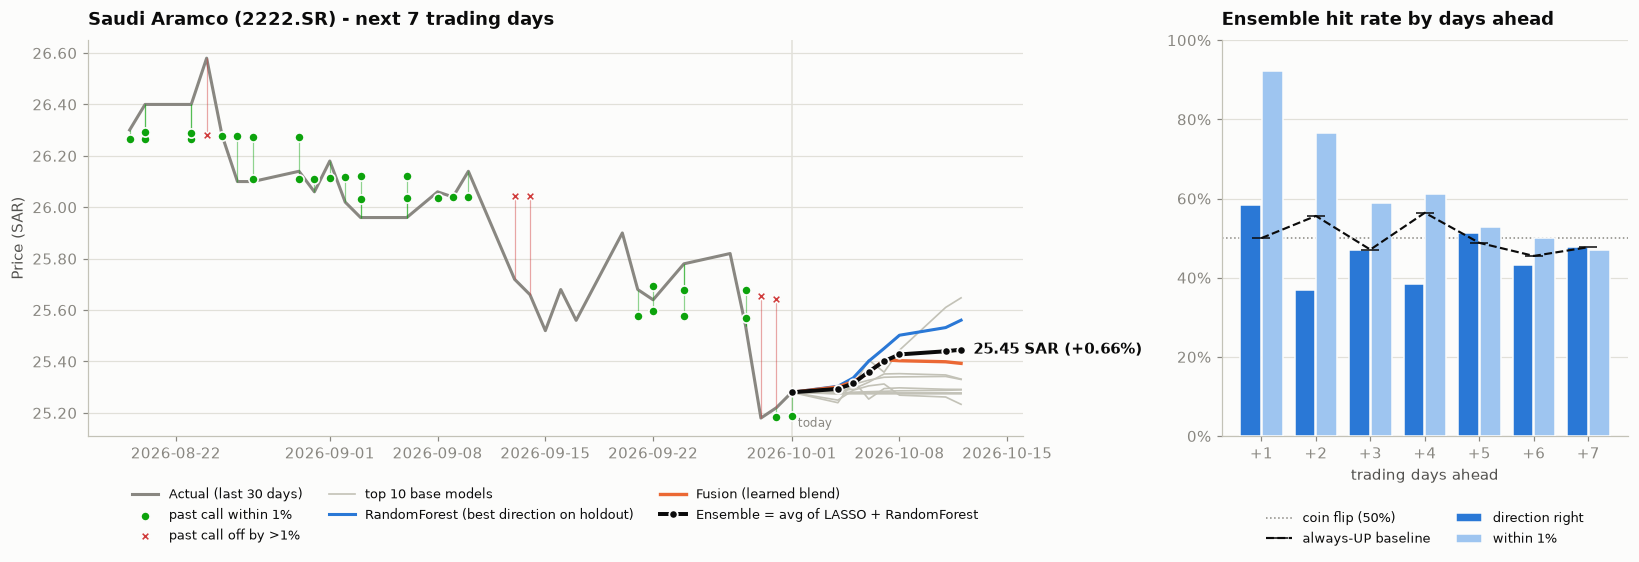

Ensemble = average of the best two models: LASSO + RandomForest
Predicted price (SAR) for the next 7 trading days -- Ensemble, fusions and the top 10 models:


,Ensemble,Fusion,Fusion-Top3,LASSO,RandomForest,ARIMAX,Kalman,ARIMA,Theta,Ridge,WSAE-LSTM,N-BEATS,XGBoost
date,,,,,,,,,,,,,
2026-10-04,25.29,25.30,25.29,25.28,25.30,25.27,25.28,25.28,25.28,25.30,25.24,25.25,25.28
2026-10-05,25.31,25.32,25.30,25.29,25.34,25.27,25.28,25.28,25.28,25.31,25.33,25.29,25.30
2026-10-06,25.36,25.36,25.33,25.32,25.40,25.27,25.28,25.28,25.28,25.33,25.25,25.31,25.41
2026-10-07,25.40,25.41,25.36,25.35,25.45,25.27,25.28,25.28,25.28,25.34,25.29,25.31,25.36
2026-10-08,25.43,25.40,25.38,25.35,25.50,25.27,25.28,25.28,25.29,25.34,25.30,25.27,25.44
2026-10-11,25.44,25.40,25.38,25.35,25.53,25.27,25.28,25.28,25.29,25.34,25.29,25.26,25.61
2026-10-12,25.45,25.39,25.39,25.33,25.56,25.27,25.28,25.28,25.29,25.33,25.29,25.23,25.65


Top 10 base models by error on the common holdout dates (mae_vs_naive < 1 beats 'no change'):


,holdout_mae,mae_vs_naive
model,,
LASSO,0.0081,0.9627
RandomForest,0.0082,0.9827
ARIMAX,0.0083,0.9923
Kalman,0.0083,0.9944
ARIMA,0.0083,0.9953
Theta,0.0084,0.9999
Ridge,0.0084,1.0015
WSAE-LSTM,0.0085,1.0108
N-BEATS,0.0087,1.0364


Holdout scoreboard -- every base model on the last 15% of history (mae_vs_naive < 1 beats 'no change'; always-UP would score 38.7% direction):


...

Ensemble, by days ahead:


,graded_calls,hit_within_1pct_%,mean_abs_error_%,direction_calls,direction_hit_%,always_up_%
days_ahead,,,,,,
1,51,92.2,0.55,12,58.3,50.0
2,51,76.5,0.73,27,37.0,55.6
3,51,58.8,0.99,34,47.1,47.1
4,49,61.2,1.03,39,38.5,56.4
5,51,52.9,1.32,43,51.2,48.8
6,50,50.0,1.47,44,43.2,45.5
7,51,47.1,1.52,44,47.7,47.7


Most recent graded Ensemble calls:


,made_on,target_date,days_ahead,price_then,predicted,actual,error_%,within_1pct,direction
0,2026-09-21,2026-09-22,1,25.68,25.70,25.64,0.22,HIT,wrong
1,2026-09-17,2026-09-22,3,25.56,25.60,25.64,0.17,HIT,right
2,2026-09-21,2026-09-24,3,25.68,25.68,25.78,0.39,HIT,flat call
3,2026-09-17,2026-09-24,5,25.56,25.58,25.78,0.79,HIT,right
4,2026-09-21,2026-09-28,5,25.68,25.68,25.54,0.53,HIT,flat call
5,2026-09-17,2026-09-28,7,25.56,25.57,25.54,0.12,HIT,flat call
6,2026-09-21,2026-09-29,6,25.68,25.65,25.18,1.88,miss,right
7,2026-09-29,2026-09-30,1,25.18,25.18,25.22,0.14,HIT,flat call
8,2026-09-21,2026-09-30,7,25.68,25.64,25.22,1.67,miss,right
9,2026-09-29,2026-10-01,2,25.18,25.19,25.28,0.37,HIT,flat call


149 call(s) still waiting for their target date (next one: 2026-10-04); 30 fell on a holiday or missing day and can never be graded.


In [37]:
# ================================================================
# 7-DAY FORECAST + HIT RATE -- standalone, run this cell on its own
# ================================================================
import os, sys, warnings
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

import matplotlib.pyplot as plt
from IPython.display import display

import predictor_lib as pl
import forecast_lib as fl

# after the imports: statsmodels re-enables its own warnings when first imported
warnings.filterwarnings("ignore")

FORECAST_TICKER = "2222.SR"

pl.top_up_data_csv(FORECAST_TICKER)                # adds finished trading days only
fcast = fl.forecast_ticker(FORECAST_TICKER)        # 14 base models, best-two Ensemble, 2 fusions (~2 min)
fl.record_forecast(FORECAST_TICKER, fcast)         # archived, graded on later runs
newly_graded = fl.grade_forecasts(FORECAST_TICKER)
print(f"Graded {newly_graded} past prediction(s) whose target date has now arrived.")

hit_report = fl.hit_rate_report(FORECAST_TICKER)
fl.plot_forecast_report(fcast, hit_report)
plt.show()

print(f"Ensemble = average of the best two models: {' + '.join(fcast['ensemble_members'])}")
print(f"Predicted price ({fcast['currency']}) for the next {fl.FORECAST_DAYS} trading days -- "
      f"Ensemble, fusions and the top {len(fcast['top_models'])} models:")
shown = ["Ensemble", *[c for c in fl.FUSION_LABELS if c in fcast["paths"]], *fcast["top_models"]]
display(fcast["paths"][shown].round(2).rename(index=lambda d: d.date()))

ranking = fcast["fusion_report"].attrs.get("ranking")
if ranking is not None:
    print(f"Top {len(fcast['top_models'])} base models by error on the common holdout dates "
          f"(mae_vs_naive < 1 beats 'no change'):")
    display(ranking.head(len(fcast["top_models"])).round(4))

print(f"Holdout scoreboard -- every base model on the last {100 - int(fl.SPLIT_RATIO * 100)}% of history "
      f"(mae_vs_naive < 1 beats 'no change'; always-UP would score "
      f"{fcast['always_up_holdout_acc']:.1%} direction):")
display(fcast["scoreboard"].drop(columns="params").round(4))
if fcast["failed_models"]:
    print("Skipped this run:", fcast["failed_models"])

fusion_check = fcast["fusion_report"]
if not fusion_check.empty:
    a = fusion_check.attrs
    print(f"Fusion check -- same dates for every model: fusion weights learned on {a['fit_origins']} holdout "
          f"dates, then everything scored on the next {a['test_origins']} ({a['test_from']} to {a['test_to']}):")
    display(fusion_check.round(4))
    print("Fusion weights behind today's forecast:", fcast["results"]["fusion"]["params"]["weights"])

print("HIT RATE --", hit_report["verdict"])
print("\nPer model (all graded forecasts; most-tested first):")
display(hit_report["per_model"])
print("Ensemble, by days ahead:")
display(hit_report["by_horizon"])
print("Most recent graded Ensemble calls:")
display(hit_report["recent_calls"])
print(f"{hit_report['pending_calls']} call(s) still waiting for their target date "
      f"(next one: {hit_report['next_grading_date']}); {hit_report['ungradable_calls']} "
      f"fell on a holiday or missing day and can never be graded.")


## 🔮🧐 7-Day Price Forecast Agent + Reviewer Agent (standalone)

Two code-only agents (no Ollama, no earlier cell needed) that sit on top of the 7-day models above and give one answer to *"what will the price be over the next 7 trading days?"*.

**Forecast agent** — takes every base model's error on the common out-of-sample holdout dates, picks the **3 best models for this ticker**, and averages their day+1 ... day+7 paths into one forecast.

**Reviewer agent** — audits that forecast. When a check fails it **changes the forecast** and says what it changed:

- **Data freshness** — warns if the last price is old (the forecast would start from a stale price).
- **Path integrity** — a member with NaN or non-positive prices is replaced by the next best model.
- **Members beat naive** — a member that does not beat "no change" on the holdout is swapped for a better one.
- **Direction agreement** — warns when the 3 models disagree on up/down.
- **Calibration** — if the average is over-confident on the holdout, every move is scaled toward "no change" (only if that cuts the holdout error by 2% or more).
- **Plausible range** — a move bigger than the 95th percentile of past same-horizon moves is clipped.
- **Price band** — a 10-90% range from the models' own holdout errors.
- **Live track record** — the graded hit rate from `forecast_log/`, for context.

The result is a day-by-day price table (the 3 members, the reviewed forecast, low/high), a chart, and a confidence label (HIGH / MEDIUM / LOW). During **Run All** it reuses the forecast trained earlier; run on its own it trains the models first (~2 min). The logic lives in `forecast_agent.py` in the project root.

This is a statistical forecast, not advice: the fusion check table above shows how little most models beat "no change", and LOW confidence means exactly that.

In [ ]:
# ================================================================
# 7-DAY FORECAST AGENT + REVIEWER AGENT -- standalone, run this cell on its own
# ================================================================
import os, sys, warnings
if os.path.abspath("..") not in sys.path:
    sys.path.insert(0, os.path.abspath(".."))

import predictor_lib as pl
import forecast_lib as fl
import forecast_agent as fa

# after the imports: statsmodels re-enables its own warnings when first imported
warnings.filterwarnings("ignore")

AGENT_TICKER = "2222.SR"

# During "Run All" the 7-DAY FORECAST GRAPH cell has already trained every model
# for this ticker -- reuse that instead of training twice.
if isinstance(globals().get("fcast"), dict) and fcast.get("ticker") == AGENT_TICKER:
    print("Reusing the forecast trained earlier in this run.")
else:
    pl.top_up_data_csv(AGENT_TICKER)               # adds finished trading days only
    fcast = fl.forecast_ticker(AGENT_TICKER)       # 14 base models, best-two Ensemble, 2 fusions (~2 min)
    fl.record_forecast(AGENT_TICKER, fcast)        # archived, graded on later runs
    fl.grade_forecasts(AGENT_TICKER)

agent_out = fa.run_forecast_and_review(fcast)      # forecast agent -> reviewer agent -> table + chart
